In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Install Required Libraries

In [2]:
%pip install -q \
    pyarrow \
    xgboost \
    lightgbm \
    catboost \
    optuna \
    imbalanced-learn

# Imports & Global Configuration

In [3]:
import os
import json
import time
import warnings
import random

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
    RandomizedSearchCV,
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    OneHotEncoder,
    FunctionTransformer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier,
    VotingClassifier,
    StackingClassifier,
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# Gradient Boosting Libraries
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Hyperparameter Optimization
import optuna

# Imbalanced Learning
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# Global settings
RANDOM_STATE = 42
N_JOBS = -1
CV_FOLDS = 5
TARGET = "SeriousDlqin2yrs"
PRIMARY_METRIC = "roc_auc"

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

print("Environment initialized successfully!")

Environment initialized successfully!


# Load Datasets

In [4]:
DATA_DIR = Path(
    "/content/drive/MyDrive/Datasets/"
    "Give Me Some Credit/modeling_data"
)

# Validate required files
required_files = [
    "train_raw.parquet",
    "holdout_raw.parquet",
    "kaggle_test_raw.parquet",
    "experiment_config.json",
]

for filename in required_files:
    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )

# Load datasets
train_df = pd.read_parquet(
    DATA_DIR / "train_raw.parquet"
)

holdout_df = pd.read_parquet(
    DATA_DIR / "holdout_raw.parquet"
)

kaggle_df = pd.read_parquet(
    DATA_DIR / "kaggle_test_raw.parquet"
)

# Load previous experiment configuration
with open(DATA_DIR / "experiment_config.json", "r") as f:
    experiment_config = json.load(f)

RANDOM_STATE = experiment_config["random_state"]
CV_FOLDS = experiment_config["cv_folds"]
TARGET = experiment_config["target"]
PRIMARY_METRIC = experiment_config["primary_metric"]

# Separate features and targets
X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET].astype(int)

X_holdout = holdout_df.drop(columns=[TARGET])
y_holdout = holdout_df[TARGET].astype(int)

# External Kaggle test dataset
kaggle_test_ids = kaggle_df["Id"].copy()

X_kaggle_test = kaggle_df.drop(columns=["Id"])

# Ensure the same feature order
feature_names = X_train.columns.tolist()

assert set(feature_names) == set(X_holdout.columns)
assert set(feature_names) == set(X_kaggle_test.columns)

X_holdout = X_holdout[feature_names]
X_kaggle_test = X_kaggle_test[feature_names]

# Dataset validation
assert not y_train.isna().any()
assert not y_holdout.isna().any()
assert TARGET not in X_kaggle_test.columns

print("Datasets loaded successfully!\n")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_holdout:", X_holdout.shape)
print("y_holdout:", y_holdout.shape)

print("X_kaggle_test:", X_kaggle_test.shape)

print("\nTarget Distribution (%)")

display(
    pd.DataFrame({
        "Train": y_train.value_counts(normalize=True),
        "Holdout": y_holdout.value_counts(normalize=True)
    }).sort_index().mul(100).round(3)
)

print("\nPrevious Experiment Configuration:")
print(json.dumps(experiment_config, indent=2))

Datasets loaded successfully!

X_train: (120000, 10)
y_train: (120000,)
X_holdout: (30000, 10)
y_holdout: (30000,)
X_kaggle_test: (101503, 10)

Target Distribution (%)


,Train,Holdout
SeriousDlqin2yrs,,
0,93.316,93.317
1,6.684,6.683



Previous Experiment Configuration:
{
  "dataset": "Give Me Some Credit",
  "target": "SeriousDlqin2yrs",
  "random_state": 42,
  "primary_metric": "roc_auc",
  "cv_folds": 5,
  "feature_engineering": "Manual",
  "feature_selection": "All_Features",
  "clipping": "No_Clipping",
  "scaling": "StandardScaler",
  "raw_feature_count": 10,
  "transformed_feature_count": 26,
  "train_rows": 120000,
  "holdout_rows": 30000,
  "kaggle_test_rows": 101503,
  "note": "Use raw splits for model training and CV. Fit preprocessing inside each CV training fold. Transformed preview is not for cross-validation."
}


# Feature Engineering & Preprocessing Pipeline

In [5]:
import re
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.compose import make_column_selector


class ManualFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Replicates the selected Manual feature engineering
    strategy from Notebook 1.
    """

    def __init__(self, skew_threshold=1.0):
        self.skew_threshold = skew_threshold

    def fit(self, X, y=None):

        num = X.select_dtypes(include=np.number)
        n_unique = num.nunique(dropna=True)

        # Missing-value indicators
        self.missing_cols_ = [
            c for c in num.columns
            if num[c].isna().any()
        ]

        # Zero-value indicators
        self.zero_cols_ = [
            c for c in num.columns
            if (
                n_unique[c] > 2
                and 0.001 <= num[c].eq(0).mean() <= 0.5
            )
        ]

        # Log features for positively skewed variables
        self.log_cols_ = [
            c for c in num.columns
            if (
                n_unique[c] > 10
                and num[c].min() >= 0
                and num[c].skew() > self.skew_threshold
            )
        ]

        return self

    def transform(self, X):

        check_is_fitted(self, "log_cols_")
        X = X.copy()

        # Missing indicators
        for col in self.missing_cols_:
            X[f"{col}_is_missing"] = (
                X[col].isna().astype("int8")
            )

        # Zero indicators
        for col in self.zero_cols_:
            X[f"{col}_is_zero"] = (
                X[col].eq(0).astype("int8")
            )

        # Logarithmic transformations
        for col in self.log_cols_:
            X[f"log_{col}"] = np.log1p(
                X[col].clip(lower=0)
            )

        return X.replace([np.inf, -np.inf], np.nan)


class FeatureNameCleaner(BaseEstimator, TransformerMixin):
    """Clean feature names for ML model compatibility."""

    def fit(self, X, y=None):

        self.columns_ = []
        used = set()

        for col in map(str, X.columns):

            base = (
                re.sub(r"[^0-9a-zA-Z_]+", "_", col)
                .strip("_") or "feature"
            )

            name = base
            suffix = 1

            while name in used:
                name = f"{base}_{suffix}"
                suffix += 1

            self.columns_.append(name)
            used.add(name)

        return self

    def transform(self, X):

        check_is_fitted(self, "columns_")

        X = pd.DataFrame(X).copy()
        X.columns = self.columns_

        return X

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "columns_")
        return np.asarray(self.columns_, dtype=object)


def build_preprocessing_pipeline(scaler=None):
    """
    Build an unfitted preprocessing pipeline.

    - Linear models: StandardScaler
    - Tree models: passthrough (no scaling)
    """

    if scaler is None:
        scaler = StandardScaler()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_pipeline,
                make_column_selector(dtype_include=np.number)
            )
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    ).set_output(transform="pandas")

    return Pipeline([
        ("feature_engineering", ManualFeatureEngineer()),
        ("preprocessing", preprocessor),
        ("clean_names", FeatureNameCleaner()),
    ])


# ============================================================
# Verify feature engineering on training data
# ============================================================

preprocessing_pipeline = build_preprocessing_pipeline()

# Preview only: clone and fit on training data
preview_preprocessor = clone(preprocessing_pipeline)

X_train_preview = preview_preprocessor.fit_transform(
    X_train, y_train
)

print("Original Training Shape:", X_train.shape)
print("Transformed Training Shape:", X_train_preview.shape)

print("\nGenerated Features:")
for i, col in enumerate(X_train_preview.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nMissing values after preprocessing:",
      X_train_preview.isna().sum().sum())

assert X_train_preview.shape[1] == 26, (
    "Expected 26 features. Check feature engineering settings."
)

display(X_train_preview.head())

Original Training Shape: (120000, 10)
Transformed Training Shape: (120000, 26)

Generated Features:
01. num__RevolvingUtilizationOfUnsecuredLines
02. num__age
03. num__NumberOfTime30_59DaysPastDueNotWorse
04. num__DebtRatio
05. num__MonthlyIncome
06. num__NumberOfOpenCreditLinesAndLoans
07. num__NumberOfTimes90DaysLate
08. num__NumberRealEstateLoansOrLines
09. num__NumberOfTime60_89DaysPastDueNotWorse
10. num__NumberOfDependents
11. num__MonthlyIncome_is_missing
12. num__NumberOfDependents_is_missing
13. num__RevolvingUtilizationOfUnsecuredLines_is_zero
14. num__DebtRatio_is_zero
15. num__MonthlyIncome_is_zero
16. num__NumberOfOpenCreditLinesAndLoans_is_zero
17. num__NumberRealEstateLoansOrLines_is_zero
18. num__log_RevolvingUtilizationOfUnsecuredLines
19. num__log_NumberOfTime30_59DaysPastDueNotWorse
20. num__log_DebtRatio
21. num__log_MonthlyIncome
22. num__log_NumberOfOpenCreditLinesAndLoans
23. num__log_NumberOfTimes90DaysLate
24. num__log_NumberRealEstateLoansOrLines
25. num__log_

,num__RevolvingUtilizationOfUnsecuredLines,num__age,num__NumberOfTime30_59DaysPastDueNotWorse,num__DebtRatio,num__MonthlyIncome,num__NumberOfOpenCreditLinesAndLoans,num__NumberOfTimes90DaysLate,num__NumberRealEstateLoansOrLines,num__NumberOfTime60_89DaysPastDueNotWorse,num__NumberOfDependents,...,num__NumberRealEstateLoansOrLines_is_zero,num__log_RevolvingUtilizationOfUnsecuredLines,num__log_NumberOfTime30_59DaysPastDueNotWorse,num__log_DebtRatio,num__log_MonthlyIncome,num__log_NumberOfOpenCreditLinesAndLoans,num__log_NumberOfTimes90DaysLate,num__log_NumberRealEstateLoansOrLines,num__log_NumberOfTime60_89DaysPastDueNotWorse,num__log_NumberOfDependents
0,-0.023737,0.657506,-0.100445,0.711051,-0.077669,-0.671428,-0.063715,-0.016033,-0.057873,1.140084,...,-0.773220,-0.386666,-0.376711,2.285184,0.123690,-0.497344,-0.196265,0.238665,-0.180847,1.332142
1,-0.024156,1.402198,-0.100445,-0.168015,-0.199624,-0.477692,-0.063715,-0.016033,-0.057873,-0.666121,...,-0.773220,-0.647662,-0.376711,-0.425369,-0.166987,-0.239950,-0.196265,0.238665,-0.180847,-0.748717
2,-0.023344,-1.373472,-0.100445,-0.168152,-0.206067,-0.090221,-0.063715,-0.898607,-0.057873,1.140084,...,1.293293,-0.163928,-0.376711,-0.506231,-0.185575,0.179684,-0.196265,-1.149254,-0.180847,1.332142
3,-0.020244,0.522107,-0.100445,-0.111893,-0.077669,-0.671428,-0.063715,-0.898607,-0.057873,-0.666121,...,1.293293,1.135682,-0.376711,1.241411,0.123690,-0.497344,-0.196265,-1.149254,-0.180847,-0.748717
4,-0.023281,0.522107,-0.100445,-0.167767,-0.260985,0.297250,-0.063715,-0.016033,-0.057873,-0.666121,...,-0.773220,-0.129846,-0.376711,-0.312104,-0.363551,0.514756,-0.196265,0.238665,-0.180847,-0.748717


 # Baseline Model Definitions

In [7]:
from sklearn.dummy import DummyClassifier

baseline_models = {

    "Dummy": DummyClassifier(
        strategy="prior"
    ),

    "Logistic_Regression": LogisticRegression(
        C=1.0,
        solver="liblinear",
        max_iter=3000,
        random_state=RANDOM_STATE
    ),

    "Decision_Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    ),

    "Random_Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=10,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE
    ),

    "Extra_Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=10,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        verbosity=-1,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        eval_metric="AUC",
        verbose=False,
        thread_count=-1,
        random_seed=RANDOM_STATE
    )
}


# ------------------------------------------------------------
# 2. Build model-specific preprocessing pipelines
# ------------------------------------------------------------

baseline_pipelines = {}

for model_name, model in baseline_models.items():

    # Logistic Regression requires scaling.
    # Tree-based models generally do not.
    if model_name == "Logistic_Regression":
        scaler = StandardScaler()
    else:
        scaler = "passthrough"

    preprocessing = build_preprocessing_pipeline(
        scaler=scaler
    )

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", clone(model))
    ])

    baseline_pipelines[model_name] = pipeline

print("Total baseline models:", len(baseline_pipelines))

for i, (name, pipeline) in enumerate(
    baseline_pipelines.items(), start=1
):
    print(f"{i:02d}. {name}")

print("\nAll baseline pipelines configured successfully.")

Total baseline models: 8
01. Dummy
02. Logistic_Regression
03. Decision_Tree
04. Random_Forest
05. Extra_Trees
06. XGBoost
07. LightGBM
08. CatBoost

All baseline pipelines configured successfully.


# Baseline Models — Stratified Cross-Validation

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from IPython.display import display


cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy"
}

baseline_results = []
baseline_fold_results = []

for model_name, pipeline in baseline_pipelines.items():

    print(f"\nCV: {model_name}", flush=True)

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=clone(pipeline),
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "Model": model_name,
        "roc_auc": np.mean(scores["test_roc_auc"]),
        "roc_auc_std": np.std(
            scores["test_roc_auc"], ddof=1
        ),
        "average_precision": np.mean(
            scores["test_average_precision"]
        ),
        "average_precision_std": np.std(
            scores["test_average_precision"], ddof=1
        ),
        "f1_macro": np.mean(scores["test_f1_macro"]),
        "balanced_accuracy": np.mean(
            scores["test_balanced_accuracy"]
        ),
        "accuracy": np.mean(scores["test_accuracy"]),
        "fit_time_s": np.mean(scores["fit_time"]),
        "total_time_s": elapsed
    }

    baseline_results.append(result)

    # Preserve individual fold results
    for fold_idx in range(CV_FOLDS):
        baseline_fold_results.append({
            "Model": model_name,
            "Fold": fold_idx + 1,
            "roc_auc": scores["test_roc_auc"][fold_idx],
            "average_precision": scores[
                "test_average_precision"
            ][fold_idx],
            "f1_macro": scores["test_f1_macro"][fold_idx],
            "balanced_accuracy": scores[
                "test_balanced_accuracy"
            ][fold_idx],
            "accuracy": scores["test_accuracy"][fold_idx]
        })

    print(
        f"ROC-AUC: {result['roc_auc']:.5f} "
        f"± {result['roc_auc_std']:.5f}"
    )

    print(
        f"Average Precision: "
        f"{result['average_precision']:.5f}"
    )

    print(f"Total time: {elapsed:.2f}s")


baseline_comparison = (
    pd.DataFrame(baseline_results)
    .sort_values(
        by="roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

baseline_folds_df = pd.DataFrame(
    baseline_fold_results
)

print("\n" + "=" * 60)
print("BASELINE MODEL COMPARISON")
print("=" * 60)

display(
    baseline_comparison.round(5)
)

best_baseline_name = baseline_comparison.loc[0, "Model"]

print("\nBest Baseline Model:", best_baseline_name)

print(
    "Best CV ROC-AUC:",
    round(baseline_comparison.loc[0, "roc_auc"], 5)
)

print("\nHoldout dataset has NOT been used.")


CV: Dummy
ROC-AUC: 0.50000 ± 0.00000
Average Precision: 0.06684
Total time: 4.06s

CV: Logistic_Regression
ROC-AUC: 0.85697 ± 0.00401
Average Precision: 0.37412
Total time: 14.35s

CV: Decision_Tree
ROC-AUC: 0.84716 ± 0.00263
Average Precision: 0.35075
Total time: 8.37s

CV: Random_Forest
ROC-AUC: 0.86288 ± 0.00311
Average Precision: 0.39630
Total time: 228.87s

CV: Extra_Trees
ROC-AUC: 0.85239 ± 0.00468
Average Precision: 0.38304
Total time: 71.18s

CV: XGBoost
ROC-AUC: 0.86441 ± 0.00402
Average Precision: 0.39878
Total time: 21.70s

CV: LightGBM
ROC-AUC: 0.86268 ± 0.00415
Average Precision: 0.39602
Total time: 25.08s

CV: CatBoost
ROC-AUC: 0.86536 ± 0.00383
Average Precision: 0.40005
Total time: 47.90s

BASELINE MODEL COMPARISON


,Model,roc_auc,roc_auc_std,average_precision,average_precision_std,f1_macro,balanced_accuracy,accuracy,fit_time_s,total_time_s
0,CatBoost,0.86536,0.00383,0.40005,0.00586,0.62810,0.59099,0.93708,9.40419,47.89821
1,XGBoost,0.86441,0.00402,0.39878,0.00765,0.62882,0.59189,0.93682,3.89740,21.70042
2,Random_Forest,0.86288,0.00311,0.39630,0.00382,0.61774,0.58262,0.93679,44.68284,228.87051
3,LightGBM,0.86268,0.00415,0.39602,0.00607,0.62817,0.59117,0.93698,4.31662,25.07700
4,Logistic_Regression,0.85697,0.00401,0.37412,0.00509,0.62480,0.58897,0.93633,2.64390,14.35368
5,Extra_Trees,0.85239,0.00468,0.38304,0.00473,0.58469,0.55783,0.93643,13.36833,71.17800
6,Decision_Tree,0.84716,0.00263,0.35075,0.00692,0.61573,0.58253,0.93512,1.53434,8.37045
7,Dummy,0.50000,0.00000,0.06684,0.00002,0.48271,0.50000,0.93316,0.64831,4.06223



Best Baseline Model: CatBoost
Best CV ROC-AUC: 0.86536

Holdout dataset has NOT been used.


# Baseline Performance Visualization

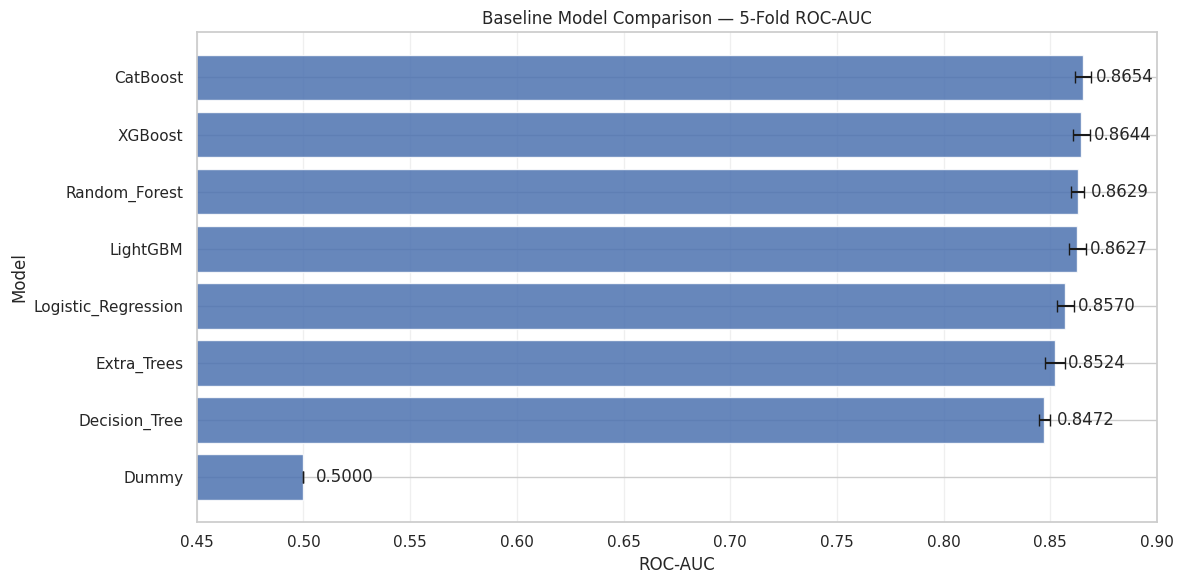

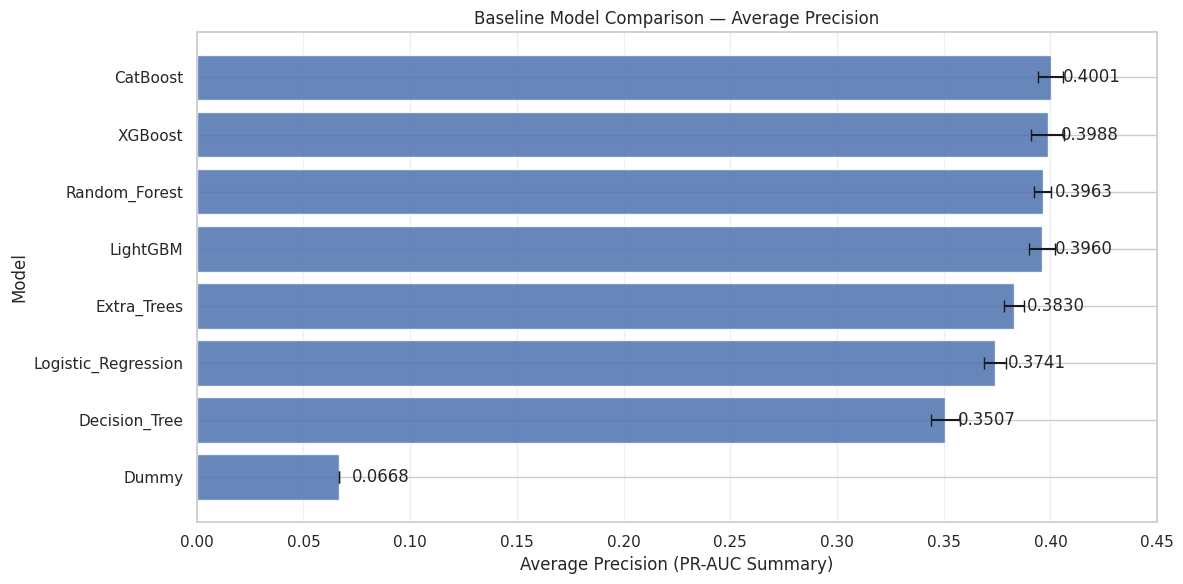


CatBoost vs XGBoost — Fold-Level ROC-AUC


Model,CatBoost,XGBoost,Difference_CatBoost_minus_XGBoost
Fold,,,
1,0.870069,0.869713,0.000356
2,0.862190,0.863226,-0.001036
3,0.862968,0.860627,0.002341
4,0.862618,0.861024,0.001594
5,0.868975,0.867483,0.001491



Mean ROC-AUC Difference: 0.000949
CatBoost Winning Folds: 4 / 5


In [9]:
plot_df = baseline_comparison.sort_values("roc_auc")

plt.figure(figsize=(12, 6))

plt.barh(
    plot_df["Model"],
    plot_df["roc_auc"],
    xerr=plot_df["roc_auc_std"],
    capsize=4,
    alpha=0.85
)

plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.title("Baseline Model Comparison — 5-Fold ROC-AUC")
plt.xlim(0.45, 0.90)
plt.grid(axis="x", alpha=0.3)

for i, value in enumerate(plot_df["roc_auc"]):
    plt.text(
        value + 0.006,
        i,
        f"{value:.4f}",
        va="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Average Precision Comparison
# ------------------------------------------------------------

plot_df = baseline_comparison.sort_values(
    "average_precision"
)

plt.figure(figsize=(12, 6))

plt.barh(
    plot_df["Model"],
    plot_df["average_precision"],
    xerr=plot_df["average_precision_std"],
    capsize=4,
    alpha=0.85
)

plt.xlabel("Average Precision (PR-AUC Summary)")
plt.ylabel("Model")
plt.title("Baseline Model Comparison — Average Precision")
plt.xlim(0, 0.45)
plt.grid(axis="x", alpha=0.3)

for i, value in enumerate(plot_df["average_precision"]):
    plt.text(
        value + 0.006,
        i,
        f"{value:.4f}",
        va="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. CatBoost vs XGBoost - Fold-Level Comparison
# ------------------------------------------------------------

top_models = ["CatBoost", "XGBoost"]

fold_comparison = (
    baseline_folds_df[
        baseline_folds_df["Model"].isin(top_models)
    ]
    .pivot(
        index="Fold",
        columns="Model",
        values="roc_auc"
    )
)

fold_comparison["Difference_CatBoost_minus_XGBoost"] = (
    fold_comparison["CatBoost"]
    - fold_comparison["XGBoost"]
)

print("\nCatBoost vs XGBoost — Fold-Level ROC-AUC")
display(fold_comparison.round(6))

print(
    "\nMean ROC-AUC Difference:",
    round(
        fold_comparison[
            "Difference_CatBoost_minus_XGBoost"
        ].mean(),
        6
    )
)

print(
    "CatBoost Winning Folds:",
    int(
        (
            fold_comparison[
                "Difference_CatBoost_minus_XGBoost"
            ] > 0
        ).sum()
    ),
    "/",
    len(fold_comparison)
)

# Class Imbalance Handling

In [11]:
from sklearn.metrics import make_scorer
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. Base classifier
base_model = baseline_models["CatBoost"]

# 2. Class-weighted classifier
weighted_model = clone(base_model).set_params(
    auto_class_weights="Balanced"
)

# 3. Imbalance strategies
imbalance_configs = {
    "No_Balancing": {
        "classifier": clone(base_model),
        "sampler": "passthrough",
    },
    "Class_Weights": {
        "classifier": weighted_model,
        "sampler": "passthrough",
    },
    "Random_Oversampling": {
        "classifier": clone(base_model),
        "sampler": RandomOverSampler(
            random_state=RANDOM_STATE
        ),
    },
    "Random_Undersampling": {
        "classifier": clone(base_model),
        "sampler": RandomUnderSampler(
            random_state=RANDOM_STATE
        ),
    },
}

# 4. Evaluation metrics
imbalance_scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": "recall",
}

# 5. Cross-validation comparison
imbalance_results = []
imbalance_fold_results = []

for strategy_name, config in imbalance_configs.items():

    print(f"\nCV: {strategy_name}", flush=True)



    # Extract individual preprocessing steps
    preprocessing_steps = clone(
        build_preprocessing_pipeline(
            scaler="passthrough"
        )
    ).steps

    # Build a flat Imbalanced-Learn Pipeline
    pipeline = ImbPipeline(
        steps=[
            *preprocessing_steps,
            ("sampler", config["sampler"]),
            ("classifier", clone(config["classifier"])),
        ]
    )





    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=imbalance_scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    elapsed = time.perf_counter() - start_time

    result = {"Strategy": strategy_name}

    for metric in imbalance_scoring:
        values = scores[f"test_{metric}"]

        result[metric] = np.mean(values)
        result[f"{metric}_std"] = np.std(
            values, ddof=1
        )

        for fold_idx, score in enumerate(values):
            imbalance_fold_results.append({
                "Strategy": strategy_name,
                "Fold": fold_idx + 1,
                "Metric": metric,
                "Score": score,
            })

    result["fit_time_s"] = np.mean(scores["fit_time"])
    result["total_time_s"] = elapsed

    imbalance_results.append(result)

    print(
        f"ROC-AUC: {result['roc_auc']:.5f} "
        f"± {result['roc_auc_std']:.5f}"
    )
    print(
        f"Average Precision: "
        f"{result['average_precision']:.5f}"
    )
    print(f"Recall: {result['recall']:.5f}")


# 6. Results
imbalance_comparison = (
    pd.DataFrame(imbalance_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

imbalance_folds_df = pd.DataFrame(
    imbalance_fold_results
)

print("\nCLASS IMBALANCE COMPARISON")

display(
    imbalance_comparison[
        [
            "Strategy",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "precision",
            "recall",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s",
        ]
    ].round(5)
)

best_imbalance_name = imbalance_comparison.loc[
    0, "Strategy"
]

print("\nHighest CV ROC-AUC strategy:", best_imbalance_name)
print("Holdout dataset has NOT been used.")


CV: No_Balancing
ROC-AUC: 0.86536 ± 0.00383
Average Precision: 0.40005
Recall: 0.19150

CV: Class_Weights
ROC-AUC: 0.86495 ± 0.00374
Average Precision: 0.39903
Recall: 0.77484

CV: Random_Oversampling
ROC-AUC: 0.86403 ± 0.00398
Average Precision: 0.39617
Recall: 0.76424

CV: Random_Undersampling
ROC-AUC: 0.86399 ± 0.00398
Average Precision: 0.38908
Recall: 0.78232

CLASS IMBALANCE COMPARISON


,Strategy,roc_auc,roc_auc_std,average_precision,precision,recall,f1_macro,balanced_accuracy,total_time_s
0,No_Balancing,0.86536,0.00383,0.40005,0.59066,0.19150,0.62810,0.59099,49.27487
1,Class_Weights,0.86495,0.00374,0.39903,0.21838,0.77484,0.61128,0.78809,53.44104
2,Random_Oversampling,0.86403,0.00398,0.39617,0.22027,0.76424,0.61321,0.78523,87.82764
3,Random_Undersampling,0.86399,0.00398,0.38908,0.21054,0.78232,0.60337,0.78608,15.70149



Highest CV ROC-AUC strategy: No_Balancing
Holdout dataset has NOT been used.


# Advanced Class Imbalance Handling

In [12]:
# ============================================================
# 9. Advanced Class Imbalance Handling
# SMOTE, Borderline-SMOTE, ADASYN, SMOTETomek
# ============================================================

from imblearn.over_sampling import (
    SMOTE,
    BorderlineSMOTE,
    ADASYN
)
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks
from imblearn.pipeline import Pipeline as ImbPipeline

# ------------------------------------------------------------
# 1. Resampling configuration
# ------------------------------------------------------------

SAMPLING_RATIO = 0.25
K_NEIGHBORS = 5

advanced_samplers = {

    "SMOTE": SMOTE(
        sampling_strategy=SAMPLING_RATIO,
        k_neighbors=K_NEIGHBORS,
        random_state=RANDOM_STATE
    ),

    "Borderline_SMOTE": BorderlineSMOTE(
        sampling_strategy=SAMPLING_RATIO,
        k_neighbors=K_NEIGHBORS,
        m_neighbors=10,
        kind="borderline-1",
        random_state=RANDOM_STATE
    ),

    "ADASYN": ADASYN(
        sampling_strategy=SAMPLING_RATIO,
        n_neighbors=K_NEIGHBORS,
        random_state=RANDOM_STATE
    ),

    "SMOTE_Tomek": SMOTETomek(
        sampling_strategy=SAMPLING_RATIO,
        smote=SMOTE(
            sampling_strategy=SAMPLING_RATIO,
            k_neighbors=K_NEIGHBORS,
            random_state=RANDOM_STATE
        ),
        tomek=TomekLinks(
            sampling_strategy="majority",
            n_jobs=1
        ),
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}


# ------------------------------------------------------------
# 2. Evaluation
# ------------------------------------------------------------

advanced_results = []
advanced_fold_results = []

for method_name, sampler in advanced_samplers.items():

    print(f"\nCV: {method_name}", flush=True)

    # Flatten preprocessing steps for imblearn compatibility
    preprocessing_steps = clone(
        build_preprocessing_pipeline(
            scaler="passthrough"
        )
    ).steps

    pipeline = ImbPipeline(
        steps=[
            *preprocessing_steps,
            ("sampler", clone(sampler)),
            ("classifier", clone(
                baseline_models["CatBoost"]
            ))
        ]
    )

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=imbalance_scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "Strategy": method_name,
        "total_time_s": elapsed,
        "fit_time_s": np.mean(scores["fit_time"])
    }

    for metric in imbalance_scoring:

        values = scores[f"test_{metric}"]

        result[metric] = np.mean(values)
        result[f"{metric}_std"] = np.std(
            values, ddof=1
        )

        for fold_idx, value in enumerate(values):
            advanced_fold_results.append({
                "Strategy": method_name,
                "Fold": fold_idx + 1,
                "Metric": metric,
                "Score": value
            })

    advanced_results.append(result)

    print(
        f"ROC-AUC: {result['roc_auc']:.5f} "
        f"± {result['roc_auc_std']:.5f}"
    )

    print(
        f"Average Precision: "
        f"{result['average_precision']:.5f}"
    )

    print(
        f"Precision: {result['precision']:.5f} | "
        f"Recall: {result['recall']:.5f}"
    )

    print(f"Total time: {elapsed:.2f}s")


# ------------------------------------------------------------
# 3. Advanced resampling comparison
# ------------------------------------------------------------

advanced_comparison = (
    pd.DataFrame(advanced_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

advanced_folds_df = pd.DataFrame(
    advanced_fold_results
)

print("\nADVANCED RESAMPLING COMPARISON")

display(
    advanced_comparison[
        [
            "Strategy",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "precision",
            "recall",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 4. Combine with previous imbalance experiments
# ------------------------------------------------------------

all_imbalance_comparison = pd.concat(
    [
        imbalance_comparison,
        advanced_comparison
    ],
    ignore_index=True
).sort_values(
    "roc_auc",
    ascending=False
).reset_index(drop=True)

print("\nALL CLASS IMBALANCE STRATEGIES")

display(
    all_imbalance_comparison[
        [
            "Strategy",
            "roc_auc",
            "average_precision",
            "precision",
            "recall",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(5)
)

print(
    "\nBest ROC-AUC strategy:",
    all_imbalance_comparison.iloc[0]["Strategy"]
)

print("\nHoldout dataset has NOT been used.")


CV: SMOTE
ROC-AUC: 0.86490 ± 0.00356
Average Precision: 0.39841
Precision: 0.58610 | Recall: 0.21606
Total time: 71.57s

CV: Borderline_SMOTE
ROC-AUC: 0.86474 ± 0.00362
Average Precision: 0.39909
Precision: 0.57580 | Recall: 0.21768
Total time: 91.86s

CV: ADASYN
ROC-AUC: 0.86510 ± 0.00340
Average Precision: 0.40077
Precision: 0.58399 | Recall: 0.21531
Total time: 91.40s

CV: SMOTE_Tomek
ROC-AUC: 0.86494 ± 0.00354
Average Precision: 0.39824
Precision: 0.57618 | Recall: 0.22030
Total time: 487.53s

ADVANCED RESAMPLING COMPARISON


,Strategy,roc_auc,roc_auc_std,average_precision,precision,recall,f1_macro,balanced_accuracy,total_time_s
0,ADASYN,0.86510,0.00340,0.40077,0.58399,0.21531,0.64082,0.60215,91.39593
1,SMOTE_Tomek,0.86494,0.00354,0.39824,0.57618,0.22030,0.64280,0.60433,487.53345
2,SMOTE,0.86490,0.00356,0.39841,0.58610,0.21606,0.64144,0.60256,71.56768
3,Borderline_SMOTE,0.86474,0.00362,0.39909,0.57580,0.21768,0.64139,0.60308,91.86250



ALL CLASS IMBALANCE STRATEGIES


,Strategy,roc_auc,average_precision,precision,recall,f1_macro,balanced_accuracy,total_time_s
0,No_Balancing,0.86536,0.40005,0.59066,0.19150,0.62810,0.59099,49.27487
1,ADASYN,0.86510,0.40077,0.58399,0.21531,0.64082,0.60215,91.39593
2,Class_Weights,0.86495,0.39903,0.21838,0.77484,0.61128,0.78809,53.44104
3,SMOTE_Tomek,0.86494,0.39824,0.57618,0.22030,0.64280,0.60433,487.53345
4,SMOTE,0.86490,0.39841,0.58610,0.21606,0.64144,0.60256,71.56768
5,Borderline_SMOTE,0.86474,0.39909,0.57580,0.21768,0.64139,0.60308,91.86250
6,Random_Oversampling,0.86403,0.39617,0.22027,0.76424,0.61321,0.78523,87.82764
7,Random_Undersampling,0.86399,0.38908,0.21054,0.78232,0.60337,0.78608,15.70149



Best ROC-AUC strategy: No_Balancing

Holdout dataset has NOT been used.


# Class Imbalance - Performance Visualization

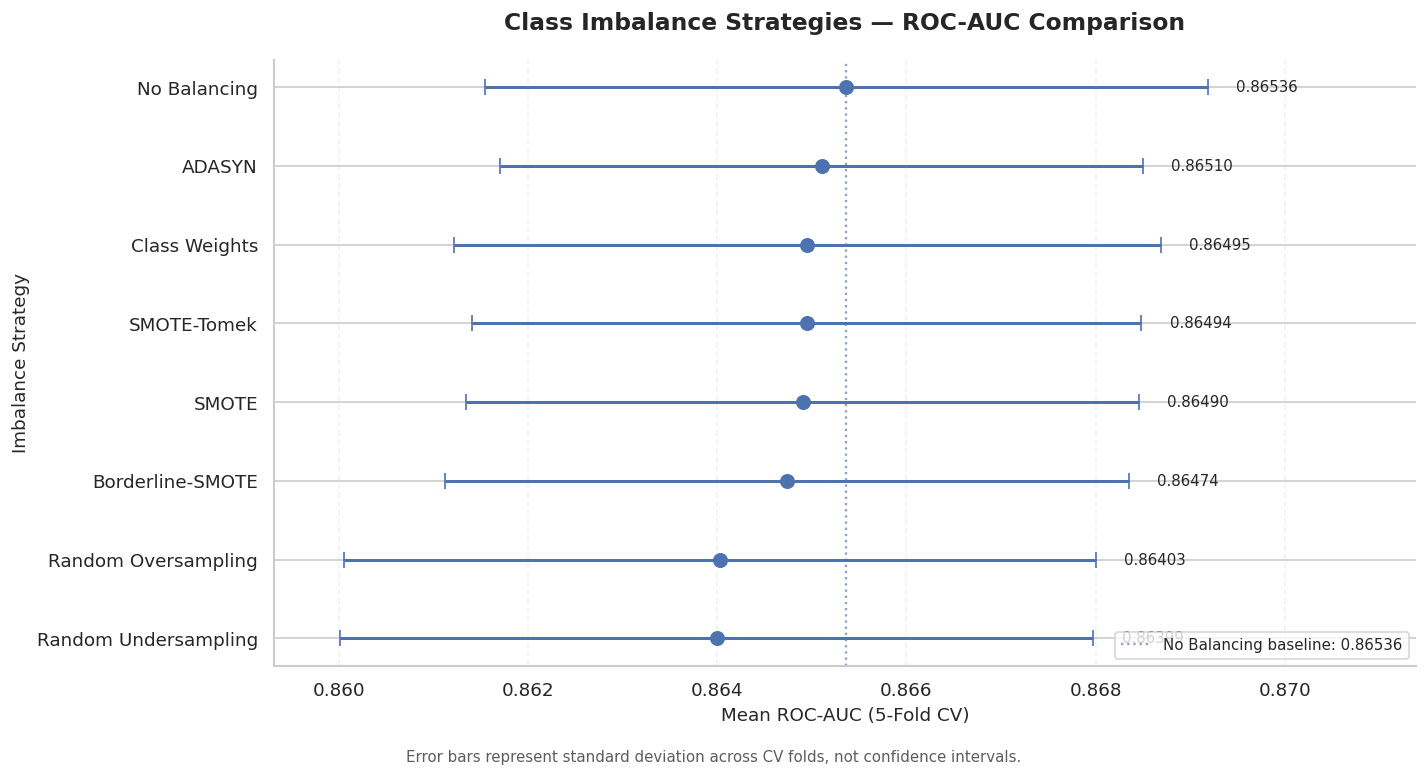

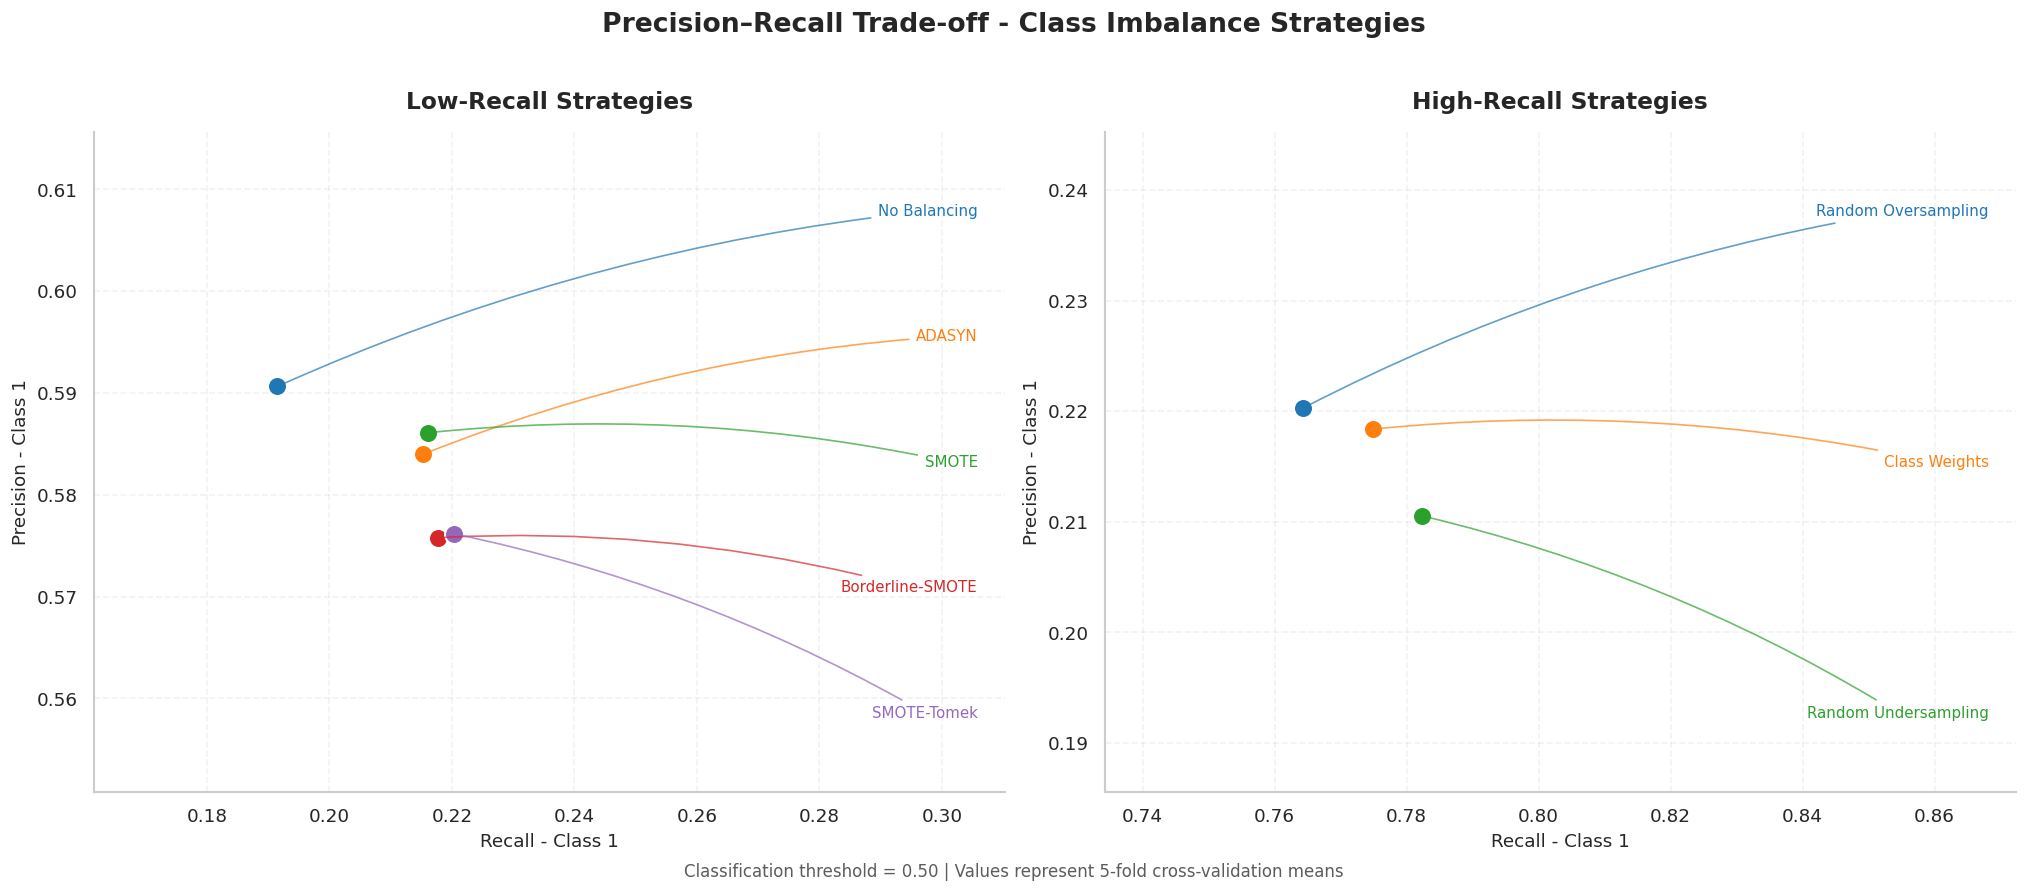


FINAL CLASS IMBALANCE PERFORMANCE SUMMARY


,Strategy,ROC-AUC,Avg Precision,Precision,Recall,F1 Macro,Balanced Acc,Time (s)
0,No Balancing,0.86536,0.40005,0.59066,0.19150,0.62810,0.59099,49.27487
1,ADASYN,0.86510,0.40077,0.58399,0.21531,0.64082,0.60215,91.39593
2,Class Weights,0.86495,0.39903,0.21838,0.77484,0.61128,0.78809,53.44104
3,SMOTE-Tomek,0.86494,0.39824,0.57618,0.22030,0.64280,0.60433,487.53345
4,SMOTE,0.86490,0.39841,0.58610,0.21606,0.64144,0.60256,71.56768
5,Borderline-SMOTE,0.86474,0.39909,0.57580,0.21768,0.64139,0.60308,91.86250
6,Random Oversampling,0.86403,0.39617,0.22027,0.76424,0.61321,0.78523,87.82764
7,Random Undersampling,0.86399,0.38908,0.21054,0.78232,0.60337,0.78608,15.70149



BEST STRATEGIES BY METRIC
Best ROC-AUC: No_Balancing (0.86536)
Best Average Precision: ADASYN (0.40077)
Best Recall: Random_Undersampling (0.78232)
Best F1 Macro: SMOTE_Tomek (0.64280)

Selected strategy for initial ensemble experiments: No_Balancing
Reference ROC-AUC: 0.86536
Holdout dataset has NOT been used.


In [16]:
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

results_df = all_imbalance_comparison.copy()

required_columns = [
    "Strategy",
    "roc_auc",
    "roc_auc_std",
    "average_precision",
    "precision",
    "recall",
    "f1_macro",
    "balanced_accuracy",
    "total_time_s"
]

missing_columns = [
    col for col in required_columns
    if col not in results_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Short labels for visualization
short_names = {
    "No_Balancing": "No Balancing",
    "Class_Weights": "Class Weights",
    "Random_Oversampling": "Random Oversampling",
    "Random_Undersampling": "Random Undersampling",
    "SMOTE": "SMOTE",
    "Borderline_SMOTE": "Borderline-SMOTE",
    "ADASYN": "ADASYN",
    "SMOTE_Tomek": "SMOTE-Tomek"
}

results_df["Display_Name"] = (
    results_df["Strategy"]
    .map(short_names)
    .fillna(results_df["Strategy"])
)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})


# ============================================================
# 2. ROC-AUC COMPARISON
# ============================================================

roc_df = (
    results_df
    .sort_values("roc_auc", ascending=True)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 6.5))

y_positions = np.arange(len(roc_df))

ax.errorbar(
    roc_df["roc_auc"],
    y_positions,
    xerr=roc_df["roc_auc_std"],
    fmt="o",
    markersize=8,
    capsize=5,
    elinewidth=1.8,
    linewidth=1.5
)

ax.set_yticks(y_positions)
ax.set_yticklabels(roc_df["Display_Name"])

ax.set_xlabel("Mean ROC-AUC (5-Fold CV)")
ax.set_ylabel("Imbalance Strategy")

ax.set_title(
    "Class Imbalance Strategies — ROC-AUC Comparison",
    fontweight="bold",
    pad=18
)

# Leave room for error bars and numerical labels
left_limit = (
    roc_df["roc_auc"] - roc_df["roc_auc_std"]
).min() - 0.0007

right_limit = (
    roc_df["roc_auc"] + roc_df["roc_auc_std"]
).max() + 0.0022

ax.set_xlim(left_limit, right_limit)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for i, row in roc_df.iterrows():

    ax.text(
        row["roc_auc"] + row["roc_auc_std"] + 0.0003,
        i,
        f"{row['roc_auc']:.5f}",
        va="center",
        fontsize=9
    )

# Mark the original baseline
baseline_auc = results_df.loc[
    results_df["Strategy"] == "No_Balancing",
    "roc_auc"
].iloc[0]

ax.axvline(
    baseline_auc,
    linestyle=":",
    linewidth=1.4,
    alpha=0.65,
    label=f"No Balancing baseline: {baseline_auc:.5f}"
)

ax.legend(loc="lower right", fontsize=9)

fig.text(
    0.5,
    0.015,
    "Error bars represent standard deviation across CV folds, "
    "not confidence intervals.",
    ha="center",
    fontsize=9,
    alpha=0.75
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


# ============================================================
# 3. PRECISION-RECALL TRADE-OFF
#    TWO ZOOMED PANELS WITH NON-OVERLAPPING LABELS
# ============================================================

low_recall_df = (
    results_df[results_df["recall"] < 0.5]
    .sort_values("recall")
    .reset_index(drop=True)
)

high_recall_df = (
    results_df[results_df["recall"] >= 0.5]
    .sort_values("recall")
    .reset_index(drop=True)
)


def plot_precision_recall_panel(
    ax,
    data,
    title,
    x_padding=0.03,
    y_padding=0.025
):
    """
    Draw a zoomed precision-recall scatterplot.

    Labels are placed at predefined vertical positions
    and connected to their actual data points.
    This prevents overlapping text.
    """

    if data.empty:
        ax.set_title(title)
        ax.text(
            0.5, 0.5, "No strategies in this group",
            ha="center", va="center",
            transform=ax.transAxes
        )
        return

    x_min = data["recall"].min()
    x_max = data["recall"].max()

    y_min = data["precision"].min()
    y_max = data["precision"].max()

    # Reserve extra space on the right for labels
    x_range = max(x_max - x_min, 0.025)
    y_range = max(y_max - y_min, 0.02)

    ax.set_xlim(
        x_min - x_padding,
        x_max + max(x_range * 2.3, 0.09)
    )

    ax.set_ylim(
        y_min - y_padding,
        y_max + y_padding
    )

    # Use distinct default Matplotlib colors
    colors = plt.get_cmap("tab10")(
        np.arange(len(data))
    )

    # Fixed label positions avoid overlap
    label_positions = np.linspace(
        0.88,
        0.12,
        len(data)
    )

    for i, (_, row) in enumerate(data.iterrows()):

        x = row["recall"]
        y = row["precision"]

        ax.scatter(
            x,
            y,
            s=130,
            color=colors[i],
            edgecolors="white",
            linewidths=1.2,
            zorder=4
        )

        # Position labels independently of data points
        ax.annotate(
            row["Display_Name"],
            xy=(x, y),
            xycoords="data",
            xytext=(0.97, label_positions[i]),
            textcoords="axes fraction",
            ha="right",
            va="center",
            fontsize=9,
            fontweight="medium",
            color=colors[i],
            arrowprops=dict(
                arrowstyle="-",
                linewidth=1,
                color=colors[i],
                alpha=0.7,
                connectionstyle="arc3,rad=0.08"
            ),
            zorder=5
        )

    ax.set_title(
        title,
        fontweight="bold",
        pad=14
    )

    ax.set_xlabel("Recall - Class 1")
    ax.set_ylabel("Precision - Class 1")

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7)
)

plot_precision_recall_panel(
    ax=axes[0],
    data=low_recall_df,
    title="Low-Recall Strategies"
)

plot_precision_recall_panel(
    ax=axes[1],
    data=high_recall_df,
    title="High-Recall Strategies"
)

fig.suptitle(
    "Precision–Recall Trade-off - Class Imbalance Strategies",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    -0.01,
    "Classification threshold = 0.50 | "
    "Values represent 5-fold cross-validation means",
    ha="center",
    fontsize=10,
    alpha=0.75
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. PERFORMANCE SUMMARY TABLE
# ============================================================

summary_columns = [
    "Display_Name",
    "roc_auc",
    "average_precision",
    "precision",
    "recall",
    "f1_macro",
    "balanced_accuracy",
    "total_time_s"
]

summary_table = (
    results_df[summary_columns]
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

summary_table = summary_table.rename(
    columns={
        "Display_Name": "Strategy",
        "roc_auc": "ROC-AUC",
        "average_precision": "Avg Precision",
        "precision": "Precision",
        "recall": "Recall",
        "f1_macro": "F1 Macro",
        "balanced_accuracy": "Balanced Acc",
        "total_time_s": "Time (s)"
    }
)

print("\n" + "=" * 65)
print("FINAL CLASS IMBALANCE PERFORMANCE SUMMARY")
print("=" * 65)

display(summary_table.round(5))


# ============================================================
# 5. BEST STRATEGIES
# ============================================================

best_auc = results_df.loc[
    results_df["roc_auc"].idxmax()
]

best_ap = results_df.loc[
    results_df["average_precision"].idxmax()
]

best_recall = results_df.loc[
    results_df["recall"].idxmax()
]

best_f1 = results_df.loc[
    results_df["f1_macro"].idxmax()
]

print("\n" + "=" * 65)
print("BEST STRATEGIES BY METRIC")
print("=" * 65)

print(
    f"Best ROC-AUC: "
    f"{best_auc['Strategy']} "
    f"({best_auc['roc_auc']:.5f})"
)

print(
    f"Best Average Precision: "
    f"{best_ap['Strategy']} "
    f"({best_ap['average_precision']:.5f})"
)

print(
    f"Best Recall: "
    f"{best_recall['Strategy']} "
    f"({best_recall['recall']:.5f})"
)

print(
    f"Best F1 Macro: "
    f"{best_f1['Strategy']} "
    f"({best_f1['f1_macro']:.5f})"
)


# ============================================================
# 6. SELECT STRATEGY FOR ENSEMBLE EXPERIMENTS
# ============================================================

SELECTED_IMBALANCE_STRATEGY = "No_Balancing"

print("\n" + "=" * 65)

print(
    "Selected strategy for initial ensemble experiments:",
    SELECTED_IMBALANCE_STRATEGY
)

print(
    "Reference ROC-AUC:",
    f"{baseline_auc:.5f}"
)

print("Holdout dataset has NOT been used.")


# Threshold Optimization


Generating OOF predictions: No_Balancing
ROC-AUC: 0.86531 | AP: 0.39894
Threshold: 0.5000 -> 0.06612
Recall: 0.1915 -> 0.7802
Precision: 0.5903 -> 0.2162

Generating OOF predictions: Class_Weights
ROC-AUC: 0.86489 | AP: 0.39798
Threshold: 0.5000 -> 0.49127
Recall: 0.7748 -> 0.7801
Precision: 0.2184 -> 0.2135

Generating OOF predictions: Random_Undersampling
ROC-AUC: 0.86389 | AP: 0.38751
Threshold: 0.5000 -> 0.50422
Recall: 0.7823 -> 0.7801
Precision: 0.2105 -> 0.2128

THRESHOLD OPTIMIZATION — RECALL >= 78%


,Strategy,ROC_AUC,Average_Precision,Optimal_Threshold,Optimized_Precision,Optimized_Recall,Optimized_F2,TP,FP,FN
0,No_Balancing,0.86531,0.39894,0.06612,0.21619,0.78020,0.51269,6258,22689,1763
1,Class_Weights,0.86489,0.39798,0.49127,0.21351,0.78008,0.50962,6257,23048,1764
2,Random_Undersampling,0.86389,0.38751,0.50422,0.21275,0.78008,0.50875,6257,23153,1764


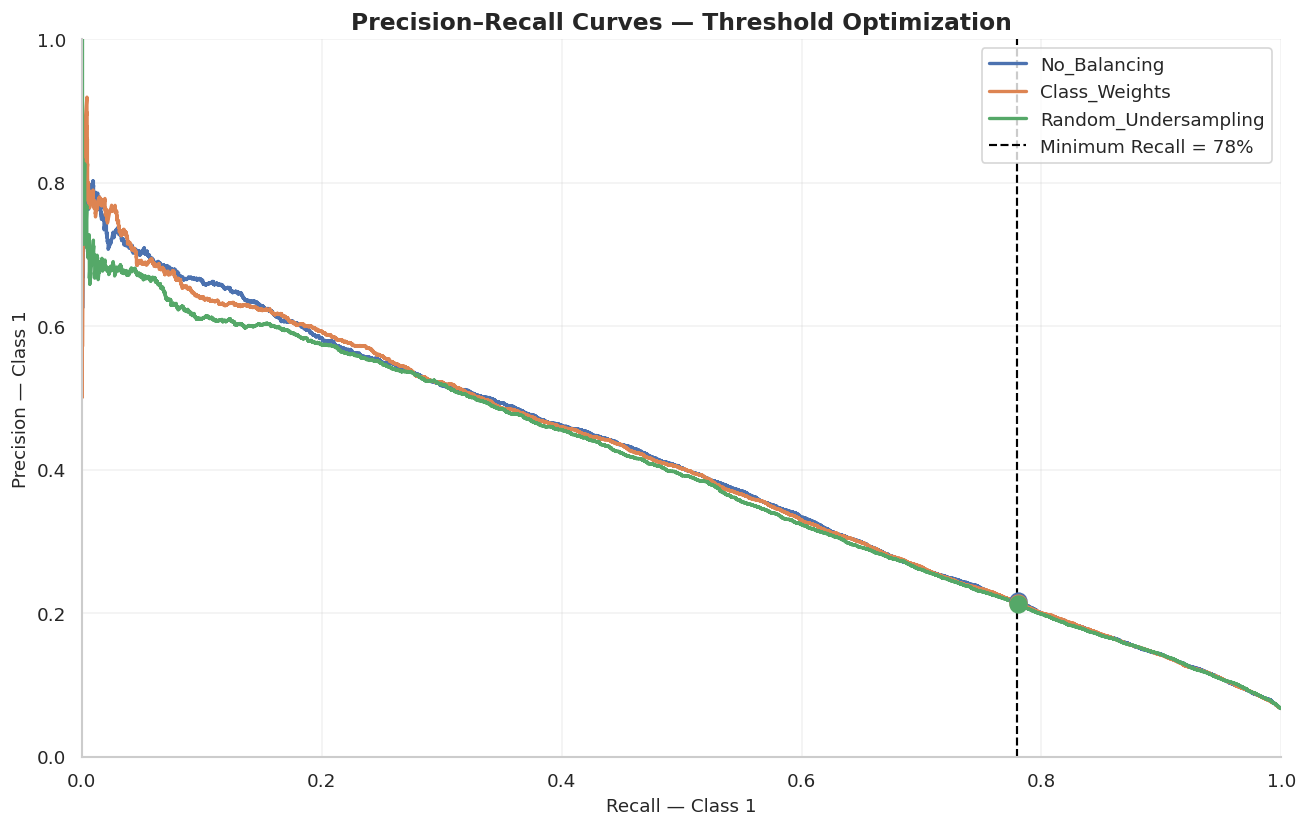


THRESHOLD COMPARISON RESULT
Recall target: 0.78
Highest OOF precision strategy: No_Balancing
Selected candidate threshold: 0.06612
OOF precision at selected threshold: 0.21619

Holdout dataset has NOT been used.


In [19]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

TARGET_RECALL = 0.78

threshold_models = {
    "No_Balancing": {
        "classifier": clone(
            baseline_models["CatBoost"]
        ),
        "sampler": "passthrough"
    },

    "Class_Weights": {
        "classifier": clone(
            baseline_models["CatBoost"]
        ).set_params(
            auto_class_weights="Balanced"
        ),
        "sampler": "passthrough"
    },

    "Random_Undersampling": {
        "classifier": clone(
            baseline_models["CatBoost"]
        ),
        "sampler": RandomUnderSampler(
            random_state=RANDOM_STATE
        )
    }
}

# ------------------------------------------------------------
# 2. Helper — Classification metrics
# ------------------------------------------------------------

def evaluate_threshold(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,
        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),
        "F2": fbeta_score(
            y_true, predictions,
            beta=2,
            zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }


# ------------------------------------------------------------
# 3. Find optimal threshold
# ------------------------------------------------------------

def find_optimal_threshold(
    y_true,
    probabilities,
    minimum_recall=0.78
):

    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probabilities
        )
    )

    # Precision and recall have one additional endpoint
    candidates = pd.DataFrame({
        "Threshold": thresholds,
        "Precision": precision[:-1],
        "Recall": recall[:-1]
    })

    # Keep thresholds satisfying the recall constraint
    feasible = candidates[
        candidates["Recall"] >= minimum_recall
    ].copy()

    if feasible.empty:
        raise ValueError(
            "No threshold satisfies the recall target."
        )

    # Maximize precision at the required recall
    feasible = feasible.sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    )

    return float(
        feasible.iloc[0]["Threshold"]
    )


# ------------------------------------------------------------
# 4. Generate out-of-fold predictions
# ------------------------------------------------------------

oof_probabilities = {}
threshold_results = []

for strategy_name, config in threshold_models.items():

    print(
        f"\nGenerating OOF predictions: {strategy_name}",
        flush=True
    )

    start_time = time.perf_counter()

    # Flatten preprocessing pipeline
    preprocessing_steps = clone(
        build_preprocessing_pipeline(
            scaler="passthrough"
        )
    ).steps


    # Build the complete pipeline
    sampler = config["sampler"]

    pipeline = ImbPipeline(
        steps=[
            *preprocessing_steps,
            ("sampler", sampler),
            ("classifier", clone(config["classifier"]))
        ]
    )


    # Each prediction comes from a model that
    # did not train on that observation.
    probabilities = cross_val_predict(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    oof_probabilities[strategy_name] = probabilities

    # Default threshold
    default_metrics = evaluate_threshold(
        y_train,
        probabilities,
        threshold=0.50
    )

    # Optimized threshold
    optimal_threshold = find_optimal_threshold(
        y_train,
        probabilities,
        minimum_recall=TARGET_RECALL
    )

    optimized_metrics = evaluate_threshold(
        y_train,
        probabilities,
        threshold=optimal_threshold
    )

    elapsed = time.perf_counter() - start_time

    # Ranking metrics do not depend on threshold
    auc = roc_auc_score(
        y_train, probabilities
    )

    ap = average_precision_score(
        y_train, probabilities
    )

    threshold_results.append({
        "Strategy": strategy_name,
        "ROC_AUC": auc,
        "Average_Precision": ap,
        "Default_Recall": default_metrics["Recall"],
        "Default_Precision": default_metrics["Precision"],
        "Optimal_Threshold": optimal_threshold,
        "Optimized_Recall": optimized_metrics["Recall"],
        "Optimized_Precision": optimized_metrics["Precision"],
        "Optimized_F1": optimized_metrics["F1"],
        "Optimized_F2": optimized_metrics["F2"],
        "TP": optimized_metrics["TP"],
        "FP": optimized_metrics["FP"],
        "FN": optimized_metrics["FN"],
        "TN": optimized_metrics["TN"],
        "Time_s": elapsed
    })

    print(
        f"ROC-AUC: {auc:.5f} | "
        f"AP: {ap:.5f}"
    )

    print(
        f"Threshold: 0.5000 -> "
        f"{optimal_threshold:.5f}"
    )

    print(
        f"Recall: "
        f"{default_metrics['Recall']:.4f} -> "
        f"{optimized_metrics['Recall']:.4f}"
    )

    print(
        f"Precision: "
        f"{default_metrics['Precision']:.4f} -> "
        f"{optimized_metrics['Precision']:.4f}"
    )


# ------------------------------------------------------------
# 5. Comparison table
# ------------------------------------------------------------

threshold_comparison = (
    pd.DataFrame(threshold_results)
    .sort_values(
        "Optimized_Precision",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("THRESHOLD OPTIMIZATION — RECALL >= 78%")
print("=" * 65)

display(
    threshold_comparison[
        [
            "Strategy",
            "ROC_AUC",
            "Average_Precision",
            "Optimal_Threshold",
            "Optimized_Precision",
            "Optimized_Recall",
            "Optimized_F2",
            "TP",
            "FP",
            "FN"
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 6. Precision-Recall curves
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for strategy_name, probabilities in oof_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_train,
        probabilities
    )

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=strategy_name
    )

    selected_row = threshold_comparison.loc[
        threshold_comparison["Strategy"] == strategy_name
    ].iloc[0]

    ax.scatter(
        selected_row["Optimized_Recall"],
        selected_row["Optimized_Precision"],
        s=100,
        zorder=5
    )

ax.axvline(
    TARGET_RECALL,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Minimum Recall = 78%"
)

ax.set_xlabel("Recall — Class 1")
ax.set_ylabel("Precision — Class 1")

ax.set_title(
    "Precision–Recall Curves — Threshold Optimization",
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Selected strategy
# ------------------------------------------------------------

best_threshold_strategy = threshold_comparison.loc[
    0, "Strategy"
]

best_threshold_value = float(
    threshold_comparison.loc[
        0, "Optimal_Threshold"
    ]
)

print("\n" + "=" * 65)
print("THRESHOLD COMPARISON RESULT")
print("=" * 65)

print("Recall target:", TARGET_RECALL)

print(
    "Highest OOF precision strategy:",
    best_threshold_strategy
)

print(
    "Selected candidate threshold:",
    round(best_threshold_value, 5)
)

print(
    "OOF precision at selected threshold:",
    round(
        threshold_comparison.loc[
            0, "Optimized_Precision"
        ],
        5
    )
)

print("\nHoldout dataset has NOT been used.")


# ENSEMBLE LEARNING: BAGGING

In [20]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import cross_validate

import numpy as np
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Define the base Decision Tree
# ------------------------------------------------------------

bagging_base_tree = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=20,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 2. Define Bagging Classifier
# ------------------------------------------------------------

bagging_model = BaggingClassifier(
    estimator=bagging_base_tree,
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    bootstrap_features=False,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 3. Build the complete model pipeline
# ------------------------------------------------------------

bagging_pipeline = Pipeline([
    (
        "preprocessing",
        build_preprocessing_pipeline(
            scaler="passthrough"
        )
    ),
    (
        "classifier",
        bagging_model
    )
])

# No resampling or class weights
# Preprocessing is fitted inside every training fold.

# ------------------------------------------------------------
# 4. Cross-validation
# ------------------------------------------------------------

print("Running Bagging Classifier — 5-Fold CV")

start_time = time.perf_counter()

bagging_scores = cross_validate(
    estimator=clone(bagging_pipeline),
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start_time

# ------------------------------------------------------------
# 5. Aggregate performance metrics
# ------------------------------------------------------------

bagging_results = {
    "Model": "Bagging_DecisionTree",

    "roc_auc": np.mean(
        bagging_scores["test_roc_auc"]
    ),

    "roc_auc_std": np.std(
        bagging_scores["test_roc_auc"],
        ddof=1
    ),

    "average_precision": np.mean(
        bagging_scores["test_average_precision"]
    ),

    "average_precision_std": np.std(
        bagging_scores["test_average_precision"],
        ddof=1
    ),

    "f1_macro": np.mean(
        bagging_scores["test_f1_macro"]
    ),

    "balanced_accuracy": np.mean(
        bagging_scores["test_balanced_accuracy"]
    ),

    "accuracy": np.mean(
        bagging_scores["test_accuracy"]
    ),

    "fit_time_s": np.mean(
        bagging_scores["fit_time"]
    ),

    "total_time_s": elapsed
}

# Store results for subsequent ensemble experiments
ensemble_results = [bagging_results]

ensemble_pipelines = {
    "Bagging_DecisionTree": bagging_pipeline
}

# ------------------------------------------------------------
# 6. Fold-level results
# ------------------------------------------------------------

bagging_folds_df = pd.DataFrame({
    "Fold": np.arange(1, CV_FOLDS + 1),

    "ROC_AUC": bagging_scores[
        "test_roc_auc"
    ],

    "Average_Precision": bagging_scores[
        "test_average_precision"
    ],

    "F1_Macro": bagging_scores[
        "test_f1_macro"
    ]
})

print("\nBagging — Fold-Level Performance")
display(bagging_folds_df.round(5))

# ------------------------------------------------------------
# 7. Compare against baseline models
# ------------------------------------------------------------

comparison_models = [
    "Decision_Tree",
    "Random_Forest",
    "XGBoost",
    "CatBoost"
]

baseline_subset = baseline_comparison[
    baseline_comparison["Model"].isin(
        comparison_models
    )
].copy()

ensemble_comparison = pd.concat(
    [
        baseline_subset,
        pd.DataFrame(ensemble_results)
    ],
    ignore_index=True
)

ensemble_comparison = (
    ensemble_comparison
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("BAGGING VS BASELINE MODELS")
print("=" * 65)

display(
    ensemble_comparison[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 8. Improvement over a single Decision Tree
# ------------------------------------------------------------

single_tree_auc = float(
    baseline_comparison.loc[
        baseline_comparison["Model"] == "Decision_Tree",
        "roc_auc"
    ].iloc[0]
)

bagging_auc = bagging_results["roc_auc"]

print("\nSingle Decision Tree ROC-AUC:",
      round(single_tree_auc, 5))

print("Bagging ROC-AUC:",
      round(bagging_auc, 5))

print(
    "Bagging ROC-AUC difference:",
    round(bagging_auc - single_tree_auc, 5)
)

print("\nHoldout dataset has NOT been used.")

Running Bagging Classifier — 5-Fold CV

Bagging — Fold-Level Performance


,Fold,ROC_AUC,Average_Precision,F1_Macro
0,1,0.86602,0.39770,0.62309
1,2,0.85872,0.39366,0.62116
2,3,0.85846,0.38576,0.60776
3,4,0.85923,0.39959,0.63691
4,5,0.86086,0.39770,0.61918



BAGGING VS BASELINE MODELS


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,balanced_accuracy,total_time_s
0,CatBoost,0.86536,0.00383,0.40005,0.62810,0.59099,47.89821
1,XGBoost,0.86441,0.00402,0.39878,0.62882,0.59189,21.70042
2,Random_Forest,0.86288,0.00311,0.39630,0.61774,0.58262,228.87051
3,Bagging_DecisionTree,0.86066,0.00314,0.39488,0.62162,0.58575,287.69250
4,Decision_Tree,0.84716,0.00263,0.35075,0.61573,0.58253,8.37045



Single Decision Tree ROC-AUC: 0.84716
Bagging ROC-AUC: 0.86066
Bagging ROC-AUC difference: 0.0135

Holdout dataset has NOT been used.


# Soft Voting & Weighted Soft Voting

In [21]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_validate

import numpy as np
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Verify existing baseline pipelines
# ------------------------------------------------------------

required_models = [
    "CatBoost",
    "XGBoost",
    "LightGBM"
]

for name in required_models:
    if name not in baseline_pipelines:
        raise ValueError(
            f"Missing baseline pipeline: {name}"
        )

print("All required baseline pipelines are available.")


# ------------------------------------------------------------
# 2. Create base estimators
# ------------------------------------------------------------

def get_voting_estimators():

    return [
        (
            "catboost",
            clone(baseline_pipelines["CatBoost"])
        ),
        (
            "xgboost",
            clone(baseline_pipelines["XGBoost"])
        ),
        (
            "lightgbm",
            clone(baseline_pipelines["LightGBM"])
        )
    ]


# ------------------------------------------------------------
# 3. Define ensemble models
# ------------------------------------------------------------

voting_models = {

    # Equal contribution from all three models
    "Soft_Voting_Equal": VotingClassifier(
        estimators=get_voting_estimators(),
        voting="soft",
        weights=[1, 1, 1],
        n_jobs=1
    ),

    # Fixed initial weights (not optimized yet)
    "Soft_Voting_Weighted": VotingClassifier(
        estimators=get_voting_estimators(),
        voting="soft",
        weights=[0.40, 0.35, 0.25],
        n_jobs=1
    )
}

# Save pipelines for later experiments
ensemble_pipelines.update(voting_models)

print("\nVoting models configured:")
for name in voting_models:
    print("-", name)


# ------------------------------------------------------------
# 4. Cross-validation evaluation
# ------------------------------------------------------------

voting_results = []
voting_fold_results = []

for model_name, model in voting_models.items():

    print(
        f"\nRunning 5-Fold CV: {model_name}",
        flush=True
    )

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=clone(model),
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "Model": model_name,

        "roc_auc": np.mean(
            scores["test_roc_auc"]
        ),

        "roc_auc_std": np.std(
            scores["test_roc_auc"],
            ddof=1
        ),

        "average_precision": np.mean(
            scores["test_average_precision"]
        ),

        "average_precision_std": np.std(
            scores["test_average_precision"],
            ddof=1
        ),

        "f1_macro": np.mean(
            scores["test_f1_macro"]
        ),

        "balanced_accuracy": np.mean(
            scores["test_balanced_accuracy"]
        ),

        "accuracy": np.mean(
            scores["test_accuracy"]
        ),

        "fit_time_s": np.mean(
            scores["fit_time"]
        ),

        "total_time_s": elapsed
    }

    voting_results.append(result)

    for fold_idx in range(CV_FOLDS):

        voting_fold_results.append({
            "Model": model_name,
            "Fold": fold_idx + 1,
            "roc_auc": scores[
                "test_roc_auc"
            ][fold_idx],
            "average_precision": scores[
                "test_average_precision"
            ][fold_idx]
        })

    print(
        f"ROC-AUC: {result['roc_auc']:.5f} "
        f"± {result['roc_auc_std']:.5f}"
    )

    print(
        "Average Precision:",
        round(result["average_precision"], 5)
    )

    print(
        "Total CV time:",
        round(elapsed, 2),
        "seconds"
    )


# ------------------------------------------------------------
# 5. Store ensemble results without duplicates
# ------------------------------------------------------------

voting_names = set(voting_models)

ensemble_results = [
    result for result in ensemble_results
    if result["Model"] not in voting_names
]

ensemble_results.extend(voting_results)

voting_comparison = (
    pd.DataFrame(voting_results)
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

voting_folds_df = pd.DataFrame(
    voting_fold_results
)

print("\n" + "=" * 65)
print("VOTING ENSEMBLE RESULTS")
print("=" * 65)

display(
    voting_comparison.round(5)
)

print("\nFOLD-LEVEL RESULTS")

display(
    voting_folds_df.round(5)
)


# ------------------------------------------------------------
# 6. Compare with best baseline models
# ------------------------------------------------------------

selected_baselines = baseline_comparison[
    baseline_comparison["Model"].isin([
        "CatBoost",
        "XGBoost",
        "LightGBM"
    ])
].copy()

final_voting_comparison = (
    pd.concat(
        [
            selected_baselines,
            voting_comparison
        ],
        ignore_index=True
    )
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("BASELINE VS SOFT VOTING")
print("=" * 65)

display(
    final_voting_comparison[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 7. Compare against CatBoost baseline
# ------------------------------------------------------------

catboost_auc = float(
    baseline_comparison.loc[
        baseline_comparison["Model"] == "CatBoost",
        "roc_auc"
    ].iloc[0]
)

print("\nCatBoost baseline ROC-AUC:", catboost_auc)

for _, row in voting_comparison.iterrows():

    improvement = row["roc_auc"] - catboost_auc

    print(
        f"{row['Model']} improvement: "
        f"{improvement:+.5f}"
    )


# ------------------------------------------------------------
# 8. Best voting model
# ------------------------------------------------------------

best_voting_name = voting_comparison.loc[
    0, "Model"
]

print("\nBest voting ensemble:", best_voting_name)

print(
    "Best voting ROC-AUC:",
    round(
        voting_comparison.loc[0, "roc_auc"],
        5
    )
)

print("\nHoldout dataset has NOT been used.")

All required baseline pipelines are available.

Voting models configured:
- Soft_Voting_Equal
- Soft_Voting_Weighted

Running 5-Fold CV: Soft_Voting_Equal
ROC-AUC: 0.86536 ± 0.00388
Average Precision: 0.40162
Total CV time: 98.56 seconds

Running 5-Fold CV: Soft_Voting_Weighted
ROC-AUC: 0.86555 ± 0.00385
Average Precision: 0.40189
Total CV time: 99.82 seconds

VOTING ENSEMBLE RESULTS


,Model,roc_auc,roc_auc_std,average_precision,average_precision_std,f1_macro,balanced_accuracy,accuracy,fit_time_s,total_time_s
0,Soft_Voting_Weighted,0.86555,0.00385,0.40189,0.00626,0.62781,0.59071,0.93709,18.84001,99.81753
1,Soft_Voting_Equal,0.86536,0.00388,0.40162,0.00638,0.62714,0.59025,0.93699,18.56184,98.55501



FOLD-LEVEL RESULTS


,Model,Fold,roc_auc,average_precision
0,Soft_Voting_Equal,1,0.87043,0.39394
1,Soft_Voting_Equal,2,0.86351,0.40723
2,Soft_Voting_Equal,3,0.86195,0.39897
3,Soft_Voting_Equal,4,0.86235,0.39877
4,Soft_Voting_Equal,5,0.86855,0.40919
5,Soft_Voting_Weighted,1,0.87060,0.39445
6,Soft_Voting_Weighted,2,0.86360,0.40728
7,Soft_Voting_Weighted,3,0.86227,0.39916
8,Soft_Voting_Weighted,4,0.86255,0.39908
9,Soft_Voting_Weighted,5,0.86873,0.40945



BASELINE VS SOFT VOTING


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,balanced_accuracy,total_time_s
0,Soft_Voting_Weighted,0.86555,0.00385,0.40189,0.62781,0.59071,99.81753
1,CatBoost,0.86536,0.00383,0.40005,0.62810,0.59099,47.89821
2,Soft_Voting_Equal,0.86536,0.00388,0.40162,0.62714,0.59025,98.55501
3,XGBoost,0.86441,0.00402,0.39878,0.62882,0.59189,21.70042
4,LightGBM,0.86268,0.00415,0.39602,0.62817,0.59117,25.07700



CatBoost baseline ROC-AUC: 0.8653638672217541
Soft_Voting_Weighted improvement: +0.00018
Soft_Voting_Equal improvement: -0.00001

Best voting ensemble: Soft_Voting_Weighted
Best voting ROC-AUC: 0.86555

Holdout dataset has NOT been used.


# STACKING ENSEMBLE LEARNING

In [22]:
import time
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# ------------------------------------------------------------
# 1. Verify prerequisites
# ------------------------------------------------------------

required_models = [
    "CatBoost",
    "XGBoost",
    "LightGBM"
]

for name in required_models:
    assert name in baseline_pipelines, (
        f"Missing baseline pipeline: {name}"
    )

assert "Soft_Voting_Weighted" in ensemble_pipelines

print("All required models are available.")


# ------------------------------------------------------------
# 2. Define base learners
# ------------------------------------------------------------

stacking_estimators = [
    (
        "catboost",
        clone(baseline_pipelines["CatBoost"])
    ),
    (
        "xgboost",
        clone(baseline_pipelines["XGBoost"])
    ),
    (
        "lightgbm",
        clone(baseline_pipelines["LightGBM"])
    )
]


# ------------------------------------------------------------
# 3. Define meta learner
# ------------------------------------------------------------

meta_learner = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 4. Configure inner CV for stacking
# ------------------------------------------------------------

stacking_inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 5. Define stacking classifier
# ------------------------------------------------------------

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=meta_learner,
    stack_method="predict_proba",
    cv=stacking_inner_cv,
    passthrough=False,
    n_jobs=1
)

ensemble_pipelines["Stacking_Logistic"] = stacking_model

print("\nStacking model configured.")
print("Base learners: CatBoost, XGBoost, LightGBM")
print("Meta learner: Logistic Regression")
print("Inner CV folds: 3")
print("Outer CV folds:", CV_FOLDS)


# ------------------------------------------------------------
# 6. Evaluate stacking with outer CV
# ------------------------------------------------------------

print("\nRunning Stacking — 5-Fold Outer CV")

start_time = time.perf_counter()

stacking_scores = cross_validate(
    estimator=clone(stacking_model),
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start_time


# ------------------------------------------------------------
# 7. Aggregate performance
# ------------------------------------------------------------

stacking_result = {
    "Model": "Stacking_Logistic",

    "roc_auc": np.mean(
        stacking_scores["test_roc_auc"]
    ),

    "roc_auc_std": np.std(
        stacking_scores["test_roc_auc"],
        ddof=1
    ),

    "average_precision": np.mean(
        stacking_scores["test_average_precision"]
    ),

    "average_precision_std": np.std(
        stacking_scores["test_average_precision"],
        ddof=1
    ),

    "f1_macro": np.mean(
        stacking_scores["test_f1_macro"]
    ),

    "balanced_accuracy": np.mean(
        stacking_scores["test_balanced_accuracy"]
    ),

    "accuracy": np.mean(
        stacking_scores["test_accuracy"]
    ),

    "fit_time_s": np.mean(
        stacking_scores["fit_time"]
    ),

    "total_time_s": elapsed
}


# ------------------------------------------------------------
# 8. Store results
# ------------------------------------------------------------

ensemble_results = [
    result for result in ensemble_results
    if result["Model"] != "Stacking_Logistic"
]

ensemble_results.append(stacking_result)


# ------------------------------------------------------------
# 9. Fold-level performance
# ------------------------------------------------------------

stacking_folds_df = pd.DataFrame({
    "Fold": np.arange(1, CV_FOLDS + 1),

    "ROC_AUC": stacking_scores["test_roc_auc"],

    "Average_Precision":
        stacking_scores["test_average_precision"],

    "F1_Macro": stacking_scores["test_f1_macro"],

    "Balanced_Accuracy":
        stacking_scores["test_balanced_accuracy"]
})

print("\nSTACKING — FOLD-LEVEL PERFORMANCE")

display(
    stacking_folds_df.round(5)
)


# ------------------------------------------------------------
# 10. Compare all evaluated ensemble models
# ------------------------------------------------------------

ensemble_comparison = (
    pd.concat(
        [
            baseline_comparison,
            pd.DataFrame(ensemble_results)
        ],
        ignore_index=True
    )
    .drop_duplicates(
        subset=["Model"],
        keep="last"
    )
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("BASELINE VS ENSEMBLE — FINAL COMPARISON")
print("=" * 65)

display(
    ensemble_comparison[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 11. Stacking vs CatBoost and Weighted Voting
# ------------------------------------------------------------

catboost_auc = float(
    baseline_comparison.loc[
        baseline_comparison["Model"] == "CatBoost",
        "roc_auc"
    ].iloc[0]
)

weighted_auc = float(
    voting_comparison.loc[
        voting_comparison["Model"] == "Soft_Voting_Weighted",
        "roc_auc"
    ].iloc[0]
)

stacking_auc = stacking_result["roc_auc"]

print("\n" + "=" * 65)
print("STACKING PERFORMANCE SUMMARY")
print("=" * 65)

print(
    f"CatBoost ROC-AUC:        {catboost_auc:.5f}"
)

print(
    f"Weighted Voting ROC-AUC: {weighted_auc:.5f}"
)

print(
    f"Stacking ROC-AUC:        {stacking_auc:.5f}"
)

print(
    f"\nStacking vs CatBoost: "
    f"{stacking_auc - catboost_auc:+.5f}"
)

print(
    f"Stacking vs Weighted Voting: "
    f"{stacking_auc - weighted_auc:+.5f}"
)

print(
    f"\nStacking Average Precision: "
    f"{stacking_result['average_precision']:.5f}"
)

print(
    f"Total CV time: "
    f"{elapsed:.2f} seconds"
)

print("\nHoldout dataset has NOT been used.")

All required models are available.

Stacking model configured.
Base learners: CatBoost, XGBoost, LightGBM
Meta learner: Logistic Regression
Inner CV folds: 3
Outer CV folds: 5

Running Stacking — 5-Fold Outer CV

STACKING — FOLD-LEVEL PERFORMANCE


,Fold,ROC_AUC,Average_Precision,F1_Macro,Balanced_Accuracy
0,1,0.87063,0.39429,0.63500,0.59884
1,2,0.86338,0.40663,0.63840,0.59978
2,3,0.86263,0.39838,0.63759,0.59936
3,4,0.86281,0.40034,0.64992,0.61160
4,5,0.86904,0.40889,0.64333,0.60414



BASELINE VS ENSEMBLE — FINAL COMPARISON


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,balanced_accuracy,total_time_s
0,Stacking_Logistic,0.86570,0.00383,0.40171,0.64085,0.60275,324.66006
1,Soft_Voting_Weighted,0.86555,0.00385,0.40189,0.62781,0.59071,99.81753
2,CatBoost,0.86536,0.00383,0.40005,0.62810,0.59099,47.89821
3,Soft_Voting_Equal,0.86536,0.00388,0.40162,0.62714,0.59025,98.55501
4,XGBoost,0.86441,0.00402,0.39878,0.62882,0.59189,21.70042
5,Random_Forest,0.86288,0.00311,0.39630,0.61774,0.58262,228.87051
6,LightGBM,0.86268,0.00415,0.39602,0.62817,0.59117,25.07700
7,Bagging_DecisionTree,0.86066,0.00314,0.39488,0.62162,0.58575,287.69250
8,Logistic_Regression,0.85697,0.00401,0.37412,0.62480,0.58897,14.35368
9,Extra_Trees,0.85239,0.00468,0.38304,0.58469,0.55783,71.17800



STACKING PERFORMANCE SUMMARY
CatBoost ROC-AUC:        0.86536
Weighted Voting ROC-AUC: 0.86555
Stacking ROC-AUC:        0.86570

Stacking vs CatBoost: +0.00034
Stacking vs Weighted Voting: +0.00015

Stacking Average Precision: 0.40171
Total CV time: 324.66 seconds

Holdout dataset has NOT been used.


# CatBoost Hyperparameter Optimization with Optuna

CatBoost Optuna optimization
Training samples: 120000
CV folds: 3
Number of trials: 20
Primary metric: ROC-AUC

Evaluating original CatBoost on tuning CV...


[I 2026-11-05 16:13:36,139] A new study created in memory with name: catboost_roc_auc_optimization


Original CatBoost (3-fold) ROC-AUC: 0.865078

Starting Optuna optimization...


  0%|          | 0/20 [00:00<?, ?it/s]


CATBOOST OPTUNA — BEST PARAMETERS
iterations: 700
depth: 5
learning_rate: 0.040689339589210324
l2_leaf_reg: 10.077599957824793
random_strength: 0.0429412547285145

Original CatBoost 3-Fold ROC-AUC: 0.865078
Best Optuna 3-Fold ROC-AUC: 0.864797
Development CV improvement: -0.000281
Total optimization time: 753.93 seconds

Tuned CatBoost pipeline configured.
The pipeline has NOT been fitted on the holdout.

Completed trials: 19
Total trials: 20


,number,value,params_iterations,params_depth,params_learning_rate,params_l2_leaf_reg,params_random_strength
15,15,0.864797,700,5,0.040689,10.077600,0.042941
9,9,0.864795,550,5,0.049677,4.395226,0.031544
16,16,0.864600,650,5,0.056464,3.406962,0.112447
17,17,0.864571,650,5,0.073344,12.775996,0.017104
13,13,0.864490,600,4,0.050766,7.991250,0.036159
5,5,0.864470,600,4,0.049015,4.974319,0.013347
12,12,0.864410,700,4,0.042297,5.332007,0.016610
3,3,0.864350,300,5,0.050217,3.221119,0.061097
1,1,0.864305,250,4,0.110222,5.092911,0.814829
14,14,0.864039,450,4,0.053388,13.589886,0.091885


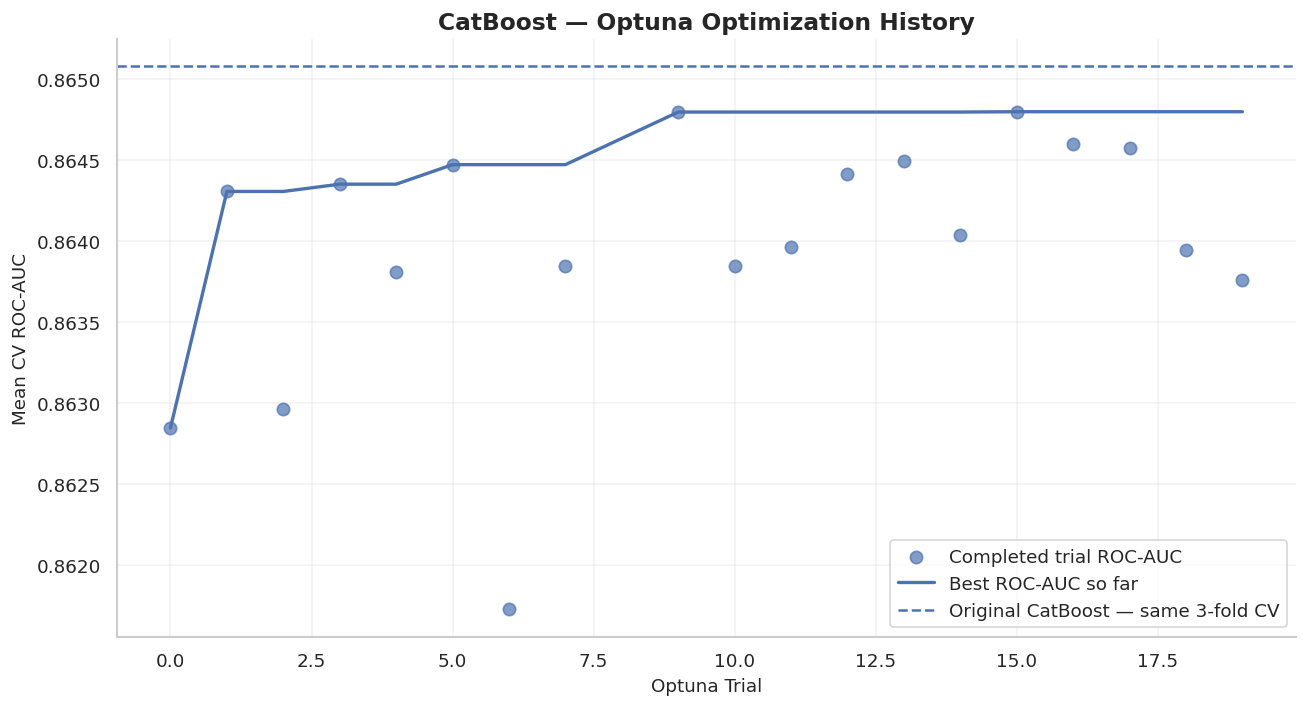


Holdout dataset has NOT been used.


In [23]:
import optuna
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

N_TRIALS_CATBOOST = 20
OPTUNA_CV_FOLDS = 3

optuna_cv = StratifiedKFold(
    n_splits=OPTUNA_CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 101
)

# Use original raw training data.
# Feature engineering must remain inside the pipeline.
X_opt = X_train
y_opt = np.asarray(y_train).ravel()

print("CatBoost Optuna optimization")
print("Training samples:", len(X_opt))
print("CV folds:", OPTUNA_CV_FOLDS)
print("Number of trials:", N_TRIALS_CATBOOST)
print("Primary metric: ROC-AUC")


# ------------------------------------------------------------
# 2. Baseline on the same tuning folds
# ------------------------------------------------------------

print("\nEvaluating original CatBoost on tuning CV...")

baseline_optuna_scores = cross_validate(
    estimator=clone(
        baseline_pipelines["CatBoost"]
    ),
    X=X_opt,
    y=y_opt,
    cv=optuna_cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

catboost_tuning_baseline_auc = np.mean(
    baseline_optuna_scores["test_score"]
)

print(
    "Original CatBoost (3-fold) ROC-AUC:",
    round(catboost_tuning_baseline_auc, 6)
)


# ------------------------------------------------------------
# 3. Define Optuna objective
# ------------------------------------------------------------

def catboost_objective(trial):

    params = {
        "iterations": trial.suggest_int(
            "iterations",
            200,
            700,
            step=50
        ),

        "depth": trial.suggest_int(
            "depth",
            4,
            8
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.015,
            0.15,
            log=True
        ),

        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg",
            1.0,
            15.0,
            log=True
        ),

        "random_strength": trial.suggest_float(
            "random_strength",
            0.01,
            5.0,
            log=True
        )
    }

    fold_scores = []

    # --------------------------------------------------------
    # Train each fold independently
    # --------------------------------------------------------

    for fold_idx, (train_idx, valid_idx) in enumerate(
        optuna_cv.split(X_opt, y_opt),
        start=1
    ):

        X_fold_train = X_opt.iloc[train_idx]
        X_fold_valid = X_opt.iloc[valid_idx]

        y_fold_train = y_opt[train_idx]
        y_fold_valid = y_opt[valid_idx]

        # Clone entire original pipeline
        pipeline = clone(
            baseline_pipelines["CatBoost"]
        )

        # Update CatBoost parameters only
        pipeline.set_params(
            **{
                f"classifier__{key}": value
                for key, value in params.items()
            }
        )

        pipeline.fit(
            X_fold_train,
            y_fold_train
        )

        probabilities = pipeline.predict_proba(
            X_fold_valid
        )[:, 1]

        fold_auc = roc_auc_score(
            y_fold_valid,
            probabilities
        )

        fold_scores.append(fold_auc)

        # Report intermediate performance
        trial.report(
            float(np.mean(fold_scores)),
            step=fold_idx
        )

        # Prune clearly underperforming trials
        if fold_idx >= 2 and trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_scores))


# ------------------------------------------------------------
# 4. Configure Optuna study
# ------------------------------------------------------------

sampler = optuna.samplers.TPESampler(
    seed=RANDOM_STATE
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=8,
    n_warmup_steps=1
)

catboost_study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
    study_name="catboost_roc_auc_optimization"
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ------------------------------------------------------------
# 5. Run optimization
# ------------------------------------------------------------

print("\nStarting Optuna optimization...")

start_time = time.perf_counter()

catboost_study.optimize(
    catboost_objective,
    n_trials=N_TRIALS_CATBOOST,
    n_jobs=1,
    show_progress_bar=True
)

optimization_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 6. Best hyperparameters
# ------------------------------------------------------------

best_catboost_params = (
    catboost_study.best_params.copy()
)

best_catboost_cv_auc = (
    catboost_study.best_value
)

print("\n" + "=" * 65)
print("CATBOOST OPTUNA — BEST PARAMETERS")
print("=" * 65)

for name, value in best_catboost_params.items():
    print(f"{name}: {value}")

print(
    "\nOriginal CatBoost 3-Fold ROC-AUC:",
    round(catboost_tuning_baseline_auc, 6)
)

print(
    "Best Optuna 3-Fold ROC-AUC:",
    round(best_catboost_cv_auc, 6)
)

print(
    "Development CV improvement:",
    round(
        best_catboost_cv_auc
        - catboost_tuning_baseline_auc,
        6
    )
)

print(
    "Total optimization time:",
    round(optimization_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# 7. Create tuned CatBoost pipeline
# ------------------------------------------------------------

tuned_catboost_pipeline = clone(
    baseline_pipelines["CatBoost"]
)

tuned_catboost_pipeline.set_params(
    **{
        f"classifier__{key}": value
        for key, value in best_catboost_params.items()
    }
)

# Save tuned model definition
tuned_pipelines = {
    "CatBoost_Optuna": tuned_catboost_pipeline
}

# Save study for later analysis
optuna_studies = {
    "CatBoost": catboost_study
}

print("\nTuned CatBoost pipeline configured.")
print("The pipeline has NOT been fitted on the holdout.")


# ------------------------------------------------------------
# 8. Trial history
# ------------------------------------------------------------

catboost_trials_df = (
    catboost_study.trials_dataframe()
)

completed_trials = catboost_trials_df[
    catboost_trials_df["state"] == "COMPLETE"
].copy()

print("\nCompleted trials:", len(completed_trials))
print("Total trials:", len(catboost_trials_df))

display(
    completed_trials[
        [
            "number",
            "value",
            "params_iterations",
            "params_depth",
            "params_learning_rate",
            "params_l2_leaf_reg",
            "params_random_strength"
        ]
    ]
    .sort_values("value", ascending=False)
    .head(10)
    .round(6)
)


# ------------------------------------------------------------
# 9. Optimization history visualization
# ------------------------------------------------------------

history_df = completed_trials.sort_values(
    "number"
).copy()

history_df["best_so_far"] = (
    history_df["value"].cummax()
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    history_df["number"],
    history_df["value"],
    s=55,
    alpha=0.7,
    label="Completed trial ROC-AUC"
)

ax.plot(
    history_df["number"],
    history_df["best_so_far"],
    linewidth=2,
    label="Best ROC-AUC so far"
)

ax.axhline(
    catboost_tuning_baseline_auc,
    linestyle="--",
    linewidth=1.5,
    label="Original CatBoost — same 3-fold CV"
)

ax.set_xlabel("Optuna Trial")
ax.set_ylabel("Mean CV ROC-AUC")

ax.set_title(
    "CatBoost — Optuna Optimization History",
    fontweight="bold"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

print("\nHoldout dataset has NOT been used.")

# XGBoost Hyperparameter Optimization with Optuna

XGBOOST — OPTUNA HYPERPARAMETER OPTIMIZATION
Training samples: 120000
Number of trials: 20
CV folds: 3
Primary metric: ROC-AUC

Evaluating original XGBoost...
Original XGBoost 3-Fold ROC-AUC: 0.863211

Starting XGBoost optimization...


  0%|          | 0/20 [00:00<?, ?it/s]


XGBOOST OPTUNA — BEST PARAMETERS
n_estimators: 350
max_depth: 5
learning_rate: 0.020749874962829932
min_child_weight: 10
subsample: 0.6760927252879199
colsample_bytree: 0.9954104278101811
reg_lambda: 4.84382786427857
gamma: 0.5961470446025172

Original XGBoost 3-Fold ROC-AUC: 0.863211
Best Optuna 3-Fold ROC-AUC: 0.865263
Development CV improvement: 0.002052
Total optimization time: 300.77 seconds

Tuned XGBoost pipeline configured.
Holdout has NOT been used.

Completed trials: 20


,number,value,params_n_estimators,params_max_depth,params_learning_rate,params_min_child_weight,params_subsample,params_colsample_bytree,params_reg_lambda,params_gamma
9,9,0.865263,350,5,0.020750,10,0.676093,0.995410,4.843828,0.596147
12,12,0.864985,350,6,0.020862,12,0.876900,0.984583,0.109198,0.492377
14,14,0.864930,400,6,0.015201,11,0.913547,0.986964,2.361858,0.718179
2,2,0.864829,500,6,0.015728,12,0.941355,0.724319,0.042877,0.550214
15,15,0.864787,350,4,0.035024,10,0.655509,0.946244,0.480934,0.877943
19,19,0.864557,250,7,0.018716,12,0.788923,0.928606,0.694751,0.663582
10,10,0.864481,700,5,0.029318,6,0.699054,0.989685,18.869640,0.122724
13,13,0.864378,350,6,0.031319,11,0.744830,0.991099,1.510003,0.388955
16,16,0.864271,250,5,0.019438,7,0.887199,0.984924,0.680239,1.165136
11,11,0.864257,450,6,0.026538,10,0.898300,0.794938,0.632958,1.042680


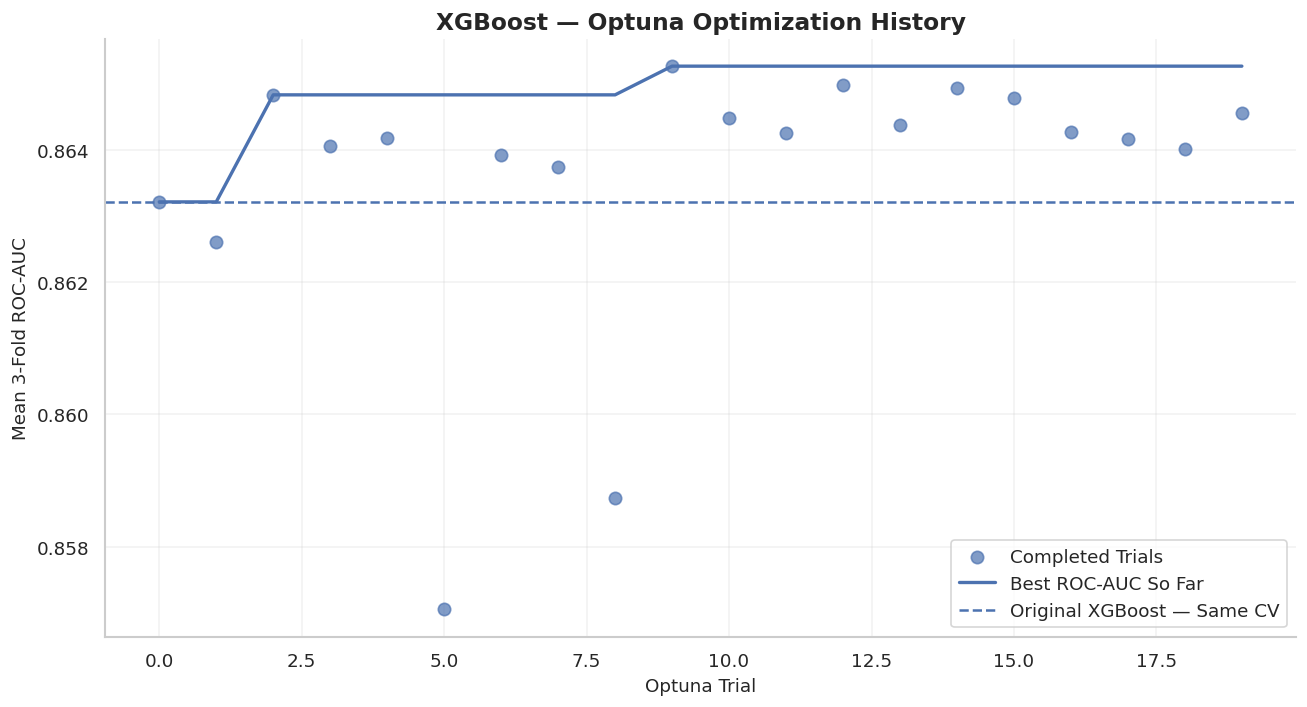


Holdout dataset has NOT been used.


In [24]:
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

N_TRIALS_XGBOOST = 20
OPTUNA_CV_FOLDS = 3

xgb_cv = StratifiedKFold(
    n_splits=OPTUNA_CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 101
)

X_opt = X_train
y_opt = np.asarray(y_train).ravel()

print("=" * 65)
print("XGBOOST — OPTUNA HYPERPARAMETER OPTIMIZATION")
print("=" * 65)

print("Training samples:", len(X_opt))
print("Number of trials:", N_TRIALS_XGBOOST)
print("CV folds:", OPTUNA_CV_FOLDS)
print("Primary metric: ROC-AUC")


# ------------------------------------------------------------
# 2. Evaluate original XGBoost on tuning CV
# ------------------------------------------------------------

print("\nEvaluating original XGBoost...")

xgb_baseline_scores = cross_validate(
    estimator=clone(
        baseline_pipelines["XGBoost"]
    ),
    X=X_opt,
    y=y_opt,
    cv=xgb_cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

xgb_tuning_baseline_auc = float(
    np.mean(xgb_baseline_scores["test_score"])
)

print(
    "Original XGBoost 3-Fold ROC-AUC:",
    round(xgb_tuning_baseline_auc, 6)
)


# ------------------------------------------------------------
# 3. Define Optuna objective
# ------------------------------------------------------------

def xgboost_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 700, step=50
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 7
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.15, log=True
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 12
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.65, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.65, 1.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.01, 30.0, log=True
        ),

        "gamma": trial.suggest_float(
            "gamma", 0.0, 3.0
        )
    }

    pipeline = clone(
        baseline_pipelines["XGBoost"]
    )

    pipeline.set_params(
        **{
            f"classifier__{key}": value
            for key, value in params.items()
        }
    )

    scores = cross_validate(
        estimator=pipeline,
        X=X_opt,
        y=y_opt,
        cv=xgb_cv,
        scoring="roc_auc",
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    return float(np.mean(scores["test_score"]))


# ------------------------------------------------------------
# 4. Create Optuna study
# ------------------------------------------------------------

xgboost_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    ),
    study_name="xgboost_roc_auc_optimization"
)

# Guarantee that the original configuration is evaluated
# as the first trial.

original_xgb_params = {
    "n_estimators": 300,
    "max_depth": 5,
    "learning_rate": 0.05,
    "min_child_weight": 1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "gamma": 0.0
}

xgboost_study.enqueue_trial(
    original_xgb_params
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ------------------------------------------------------------
# 5. Run optimization
# ------------------------------------------------------------

print("\nStarting XGBoost optimization...")

start_time = time.perf_counter()

xgboost_study.optimize(
    xgboost_objective,
    n_trials=N_TRIALS_XGBOOST,
    n_jobs=1,
    show_progress_bar=True
)

optimization_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 6. Best parameters
# ------------------------------------------------------------

best_xgb_params = (
    xgboost_study.best_params.copy()
)

best_xgb_cv_auc = float(
    xgboost_study.best_value
)

print("\n" + "=" * 65)
print("XGBOOST OPTUNA — BEST PARAMETERS")
print("=" * 65)

for name, value in best_xgb_params.items():
    print(f"{name}: {value}")

print(
    "\nOriginal XGBoost 3-Fold ROC-AUC:",
    round(xgb_tuning_baseline_auc, 6)
)

print(
    "Best Optuna 3-Fold ROC-AUC:",
    round(best_xgb_cv_auc, 6)
)

print(
    "Development CV improvement:",
    round(
        best_xgb_cv_auc - xgb_tuning_baseline_auc,
        6
    )
)

print(
    "Total optimization time:",
    round(optimization_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# 7. Create tuned XGBoost pipeline
# ------------------------------------------------------------

tuned_xgboost_pipeline = clone(
    baseline_pipelines["XGBoost"]
)

tuned_xgboost_pipeline.set_params(
    **{
        f"classifier__{key}": value
        for key, value in best_xgb_params.items()
    }
)

# Preserve previous tuned models
tuned_pipelines["XGBoost_Optuna"] = (
    tuned_xgboost_pipeline
)

optuna_studies["XGBoost"] = xgboost_study

print("\nTuned XGBoost pipeline configured.")
print("Holdout has NOT been used.")


# ------------------------------------------------------------
# 8. Trial results
# ------------------------------------------------------------

xgb_trials_df = (
    xgboost_study.trials_dataframe()
)

completed_xgb_trials = (
    xgb_trials_df[
        xgb_trials_df["state"] == "COMPLETE"
    ]
    .copy()
)

print("\nCompleted trials:", len(completed_xgb_trials))

display(
    completed_xgb_trials[
        [
            "number",
            "value",
            "params_n_estimators",
            "params_max_depth",
            "params_learning_rate",
            "params_min_child_weight",
            "params_subsample",
            "params_colsample_bytree",
            "params_reg_lambda",
            "params_gamma"
        ]
    ]
    .sort_values(
        "value",
        ascending=False
    )
    .head(10)
    .round(6)
)


# ------------------------------------------------------------
# 9. Optimization history
# ------------------------------------------------------------

history_df = (
    completed_xgb_trials
    .sort_values("number")
    .copy()
)

history_df["best_so_far"] = (
    history_df["value"].cummax()
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    history_df["number"],
    history_df["value"],
    s=55,
    alpha=0.7,
    label="Completed Trials"
)

ax.plot(
    history_df["number"],
    history_df["best_so_far"],
    linewidth=2,
    label="Best ROC-AUC So Far"
)

ax.axhline(
    xgb_tuning_baseline_auc,
    linestyle="--",
    linewidth=1.5,
    label="Original XGBoost — Same CV"
)

ax.set_xlabel("Optuna Trial")
ax.set_ylabel("Mean 3-Fold ROC-AUC")

ax.set_title(
    "XGBoost — Optuna Optimization History",
    fontweight="bold"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

print("\nHoldout dataset has NOT been used.")

# LightGBM Hyperparameter Optimization with Optuna

LIGHTGBM — OPTUNA HYPERPARAMETER OPTIMIZATION
Training samples: 120000
Number of trials: 20
CV folds: 3
Primary metric: ROC-AUC

Evaluating original LightGBM...
Original LightGBM 3-Fold ROC-AUC: 0.861666

Starting LightGBM optimization...


  0%|          | 0/20 [00:00<?, ?it/s]


LIGHTGBM OPTUNA — BEST PARAMETERS
n_estimators: 350
learning_rate: 0.022778366782639572
num_leaves: 17
min_child_samples: 76
subsample: 0.7186153430227671
colsample_bytree: 0.941667991444762
reg_alpha: 2.8904965794422948
reg_lambda: 13.131318222551288

Original LightGBM 3-Fold ROC-AUC: 0.861666
Best Optuna 3-Fold ROC-AUC: 0.865327
Development CV improvement: 0.003661
Optimization time: 370.57 seconds

Tuned LightGBM pipeline configured.

Completed trials: 20


,number,value,params_n_estimators,params_learning_rate,params_num_leaves,params_min_child_samples,params_subsample,params_colsample_bytree,params_reg_alpha,params_reg_lambda
18,18,0.865327,350,0.022778,17,76,0.718615,0.941668,2.890497,13.131318
17,17,0.865304,350,0.033890,18,76,0.745373,0.895105,3.652123,14.667530
6,6,0.865297,250,0.046910,16,92,0.777634,0.898757,3.117111,10.401360
11,11,0.865283,250,0.038627,16,67,0.782300,0.892519,7.297375,10.409655
19,19,0.865246,400,0.020710,18,68,0.754473,0.879386,3.710865,16.291775
15,15,0.865040,200,0.045188,22,79,0.702832,0.899712,5.088652,11.339224
12,12,0.865029,250,0.022285,20,74,0.763161,0.965347,2.882134,7.529192
14,14,0.865008,250,0.043011,22,83,0.813246,0.956805,9.661238,12.780100
16,16,0.864873,250,0.055915,20,97,0.813276,0.840011,5.299774,8.185986
8,8,0.864085,200,0.023555,17,39,0.816603,0.781405,8.287375,7.135067


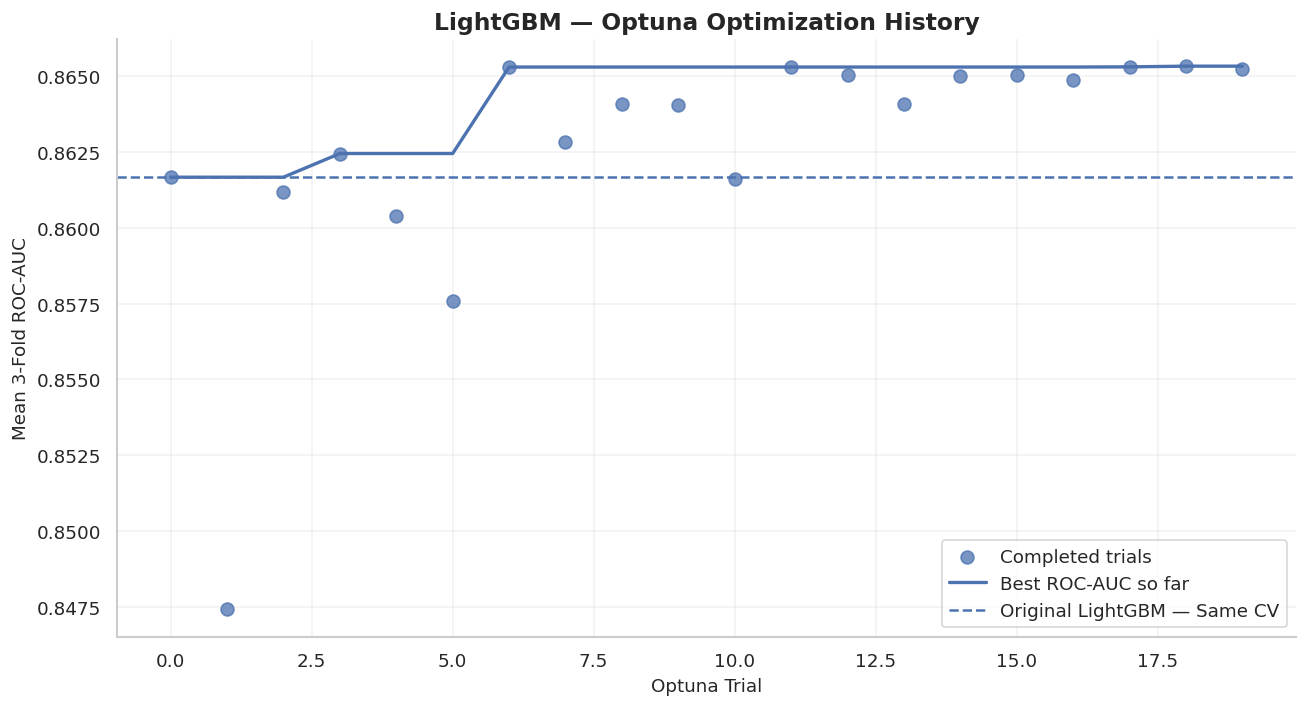


Holdout dataset has NOT been used.


In [26]:
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

N_TRIALS_LIGHTGBM = 20

lgbm_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE + 101
)

X_opt = X_train
y_opt = np.asarray(y_train).ravel()

print("=" * 65)
print("LIGHTGBM — OPTUNA HYPERPARAMETER OPTIMIZATION")
print("=" * 65)

print("Training samples:", len(X_opt))
print("Number of trials:", N_TRIALS_LIGHTGBM)
print("CV folds:", lgbm_cv.n_splits)
print("Primary metric: ROC-AUC")


# ------------------------------------------------------------
# 2. Original LightGBM — Same 3-Fold CV
# ------------------------------------------------------------

print("\nEvaluating original LightGBM...")

lgbm_baseline_scores = cross_validate(
    estimator=clone(
        baseline_pipelines["LightGBM"]
    ),
    X=X_opt,
    y=y_opt,
    cv=lgbm_cv,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise"
)

lgbm_tuning_baseline_auc = float(
    np.mean(lgbm_baseline_scores["test_score"])
)

print(
    "Original LightGBM 3-Fold ROC-AUC:",
    round(lgbm_tuning_baseline_auc, 6)
)


# ------------------------------------------------------------
# 3. Define Optuna objective
# ------------------------------------------------------------

def lightgbm_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            200, 700, step=50
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.015, 0.15,
            log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves",
            15, 63
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            10, 100
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.70, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.70, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            0.0, 10.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            0.0, 20.0
        )
    }

    pipeline = clone(
        baseline_pipelines["LightGBM"]
    )

    pipeline.set_params(
        classifier__subsample_freq=1,
        **{
            f"classifier__{key}": value
            for key, value in params.items()
        }
    )

    scores = cross_validate(
        estimator=pipeline,
        X=X_opt,
        y=y_opt,
        cv=lgbm_cv,
        scoring="roc_auc",
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    return float(
        np.mean(scores["test_score"])
    )


# ------------------------------------------------------------
# 4. Create Optuna study
# ------------------------------------------------------------

lightgbm_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    ),
    study_name="lightgbm_roc_auc_optimization"
)

# Evaluate original hyperparameter configuration
# as the first Optuna trial.

original_lgbm_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 20,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0
}

lightgbm_study.enqueue_trial(
    original_lgbm_params
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ------------------------------------------------------------
# 5. Run optimization
# ------------------------------------------------------------

print("\nStarting LightGBM optimization...")

start_time = time.perf_counter()

lightgbm_study.optimize(
    lightgbm_objective,
    n_trials=N_TRIALS_LIGHTGBM,
    n_jobs=1,
    show_progress_bar=True
)

optimization_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 6. Best parameters and performance
# ------------------------------------------------------------

best_lgbm_params = (
    lightgbm_study.best_params.copy()
)

best_lgbm_cv_auc = float(
    lightgbm_study.best_value
)

print("\n" + "=" * 65)
print("LIGHTGBM OPTUNA — BEST PARAMETERS")
print("=" * 65)

for name, value in best_lgbm_params.items():
    print(f"{name}: {value}")

print(
    "\nOriginal LightGBM 3-Fold ROC-AUC:",
    round(lgbm_tuning_baseline_auc, 6)
)

print(
    "Best Optuna 3-Fold ROC-AUC:",
    round(best_lgbm_cv_auc, 6)
)

print(
    "Development CV improvement:",
    round(
        best_lgbm_cv_auc -
        lgbm_tuning_baseline_auc,
        6
    )
)

print(
    "Optimization time:",
    round(optimization_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# 7. Create tuned pipeline
# ------------------------------------------------------------

tuned_lightgbm_pipeline = clone(
    baseline_pipelines["LightGBM"]
)

tuned_lightgbm_pipeline.set_params(
    classifier__subsample_freq=1,
    **{
        f"classifier__{key}": value
        for key, value in best_lgbm_params.items()
    }
)

# Preserve previous tuned models
tuned_pipelines["LightGBM_Optuna"] = (
    tuned_lightgbm_pipeline
)

optuna_studies["LightGBM"] = (
    lightgbm_study
)

print("\nTuned LightGBM pipeline configured.")


# ------------------------------------------------------------
# 8. Top 10 trials
# ------------------------------------------------------------

lgbm_trials_df = (
    lightgbm_study.trials_dataframe()
)

completed_lgbm_trials = (
    lgbm_trials_df[
        lgbm_trials_df["state"] == "COMPLETE"
    ]
    .copy()
)

print(
    "\nCompleted trials:",
    len(completed_lgbm_trials)
)

display(
    completed_lgbm_trials[
        [
            "number",
            "value",
            "params_n_estimators",
            "params_learning_rate",
            "params_num_leaves",
            "params_min_child_samples",
            "params_subsample",
            "params_colsample_bytree",
            "params_reg_alpha",
            "params_reg_lambda"
        ]
    ]
    .sort_values(
        "value",
        ascending=False
    )
    .head(10)
    .round(6)
)


# ------------------------------------------------------------
# 9. Optimization history
# ------------------------------------------------------------

history_df = (
    completed_lgbm_trials
    .sort_values("number")
    .copy()
)

history_df["best_so_far"] = (
    history_df["value"].cummax()
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    history_df["number"],
    history_df["value"],
    s=60,
    alpha=0.75,
    label="Completed trials"
)

ax.plot(
    history_df["number"],
    history_df["best_so_far"],
    linewidth=2,
    label="Best ROC-AUC so far"
)

ax.axhline(
    lgbm_tuning_baseline_auc,
    linestyle="--",
    linewidth=1.5,
    label="Original LightGBM — Same CV"
)

ax.set_xlabel("Optuna Trial")
ax.set_ylabel("Mean 3-Fold ROC-AUC")

ax.set_title(
    "LightGBM — Optuna Optimization History",
    fontweight="bold"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

print("\nHoldout dataset has NOT been used.")

# Original vs Tuned Models: 5-Fold Comparison

All tuned models are available.
CV folds: 5
Training samples: 120000
Primary metric: ROC-AUC

Evaluating: CatBoost_Optuna
ROC-AUC: 0.865253 ± 0.003874
Average Precision: 0.399474
Total CV time: 111.52 seconds

Evaluating: XGBoost_Optuna
ROC-AUC: 0.865416 ± 0.003458
Average Precision: 0.402377
Total CV time: 32.39 seconds

Evaluating: LightGBM_Optuna
ROC-AUC: 0.865608 ± 0.003586
Average Precision: 0.403156
Total CV time: 35.09 seconds

ORIGINAL VS TUNED — 5-FOLD CV


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,balanced_accuracy,total_time_s
0,LightGBM_Optuna,0.865608,0.003586,0.403156,0.626202,0.588973,35.092742
1,XGBoost_Optuna,0.865416,0.003458,0.402377,0.626675,0.589493,32.394304
2,CatBoost,0.865364,0.003825,0.400050,0.628098,0.590989,47.898209
3,CatBoost_Optuna,0.865253,0.003874,0.399474,0.629790,0.592280,111.518470
4,XGBoost,0.864415,0.004023,0.398780,0.628819,0.591892,21.700420
5,LightGBM,0.862676,0.004151,0.396016,0.628168,0.591166,25.077003



PAIRED ORIGINAL VS TUNED COMPARISON


,Family,Original_ROC_AUC,Tuned_ROC_AUC,Mean_Difference,Winning_Folds,Total_Folds
0,CatBoost,0.865364,0.865253,-0.000111,2,5
1,XGBoost,0.864415,0.865416,0.001001,5,5
2,LightGBM,0.862676,0.865608,0.002932,5,5


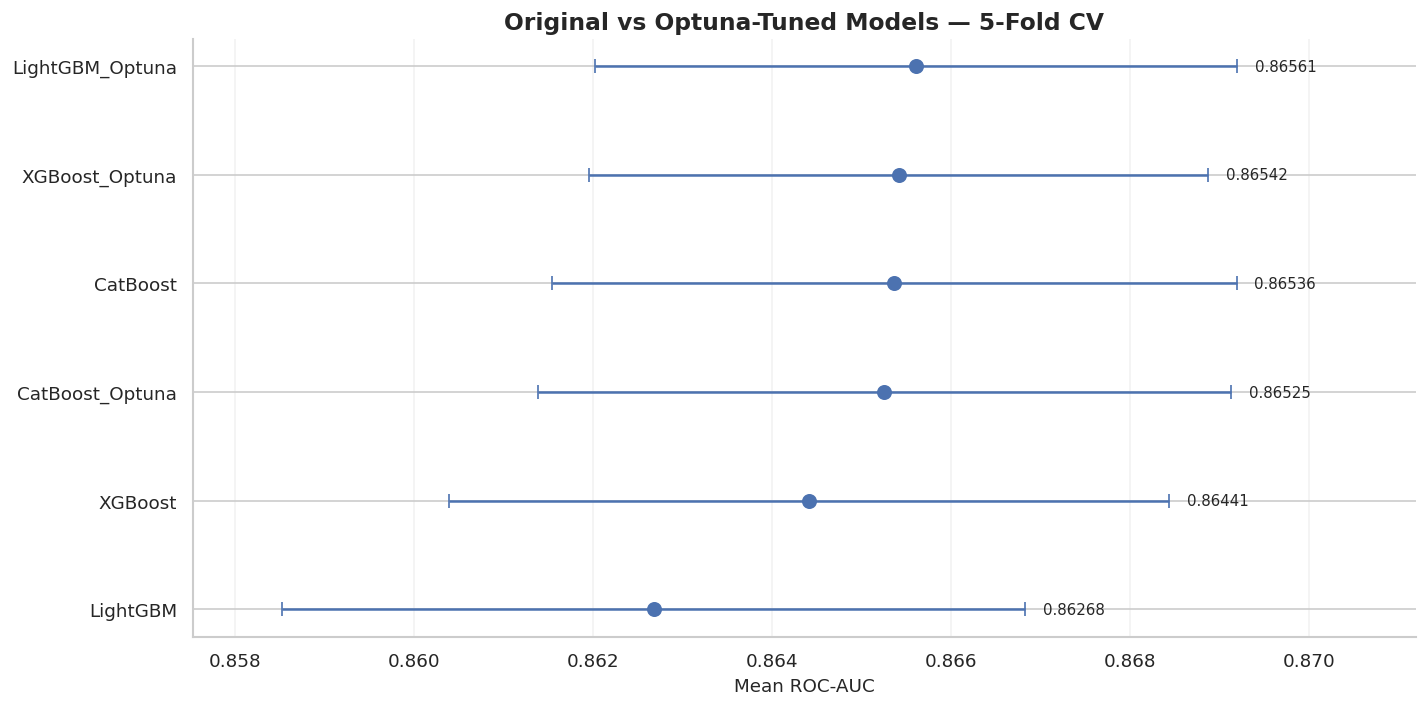


MODEL DEVELOPMENT LEADERBOARD


,Model,roc_auc,average_precision,f1_macro,total_time_s
0,Stacking_Logistic,0.865699,0.401706,0.640848,324.660061
1,LightGBM_Optuna,0.865608,0.403156,0.626202,35.092742
2,Soft_Voting_Weighted,0.865549,0.401886,0.627808,99.817528
3,XGBoost_Optuna,0.865416,0.402377,0.626675,32.394304
4,CatBoost,0.865364,0.400050,0.628098,47.898209
5,Soft_Voting_Equal,0.865358,0.401619,0.627143,98.555011
6,CatBoost_Optuna,0.865253,0.399474,0.629790,111.518470
7,XGBoost,0.864415,0.398780,0.628819,21.700420
8,LightGBM,0.862676,0.396016,0.628168,25.077003
9,Bagging_DecisionTree,0.860659,0.394880,0.621621,287.692500



Holdout dataset has NOT been used.
These are development CV results, not independent test results.


In [27]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# ------------------------------------------------------------
# 1. Verify tuned models
# ------------------------------------------------------------

required_tuned_models = [
    "CatBoost_Optuna",
    "XGBoost_Optuna",
    "LightGBM_Optuna"
]

for name in required_tuned_models:
    if name not in tuned_pipelines:
        raise ValueError(f"Missing tuned pipeline: {name}")

print("All tuned models are available.")
print("CV folds:", CV_FOLDS)
print("Training samples:", len(X_train))
print("Primary metric: ROC-AUC")


# ------------------------------------------------------------
# 2. Evaluate tuned models
# ------------------------------------------------------------

tuned_cv_results = []
tuned_fold_results = []

for model_name in required_tuned_models:

    print(f"\nEvaluating: {model_name}", flush=True)

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=clone(tuned_pipelines[model_name]),
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "Model": model_name,
        "roc_auc": np.mean(scores["test_roc_auc"]),
        "roc_auc_std": np.std(
            scores["test_roc_auc"], ddof=1
        ),
        "average_precision": np.mean(
            scores["test_average_precision"]
        ),
        "average_precision_std": np.std(
            scores["test_average_precision"], ddof=1
        ),
        "f1_macro": np.mean(scores["test_f1_macro"]),
        "balanced_accuracy": np.mean(
            scores["test_balanced_accuracy"]
        ),
        "accuracy": np.mean(scores["test_accuracy"]),
        "fit_time_s": np.mean(scores["fit_time"]),
        "total_time_s": elapsed
    }

    tuned_cv_results.append(result)

    for fold_idx in range(CV_FOLDS):
        tuned_fold_results.append({
            "Model": model_name,
            "Fold": fold_idx + 1,
            "roc_auc": scores["test_roc_auc"][fold_idx],
            "average_precision": scores[
                "test_average_precision"
            ][fold_idx]
        })

    print(
        f"ROC-AUC: {result['roc_auc']:.6f} "
        f"± {result['roc_auc_std']:.6f}"
    )

    print(
        "Average Precision:",
        round(result["average_precision"], 6)
    )

    print(
        "Total CV time:",
        round(elapsed, 2),
        "seconds"
    )


# ------------------------------------------------------------
# 3. Results DataFrames
# ------------------------------------------------------------

tuned_comparison = pd.DataFrame(
    tuned_cv_results
)

tuned_folds_df = pd.DataFrame(
    tuned_fold_results
)

original_models = [
    "CatBoost",
    "XGBoost",
    "LightGBM"
]

original_comparison = baseline_comparison[
    baseline_comparison["Model"].isin(original_models)
].copy()

all_tuned_comparison = (
    pd.concat(
        [original_comparison, tuned_comparison],
        ignore_index=True
    )
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("ORIGINAL VS TUNED — 5-FOLD CV")
print("=" * 65)

display(
    all_tuned_comparison[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 4. Paired fold-level comparison
# ------------------------------------------------------------

comparison_pairs = {
    "CatBoost": "CatBoost_Optuna",
    "XGBoost": "XGBoost_Optuna",
    "LightGBM": "LightGBM_Optuna"
}

paired_results = []

for original_name, tuned_name in comparison_pairs.items():

    original_fold = (
        baseline_folds_df[
            baseline_folds_df["Model"] == original_name
        ][["Fold", "roc_auc"]]
        .rename(columns={"roc_auc": "Original_AUC"})
    )

    tuned_fold = (
        tuned_folds_df[
            tuned_folds_df["Model"] == tuned_name
        ][["Fold", "roc_auc"]]
        .rename(columns={"roc_auc": "Tuned_AUC"})
    )

    merged = original_fold.merge(
        tuned_fold,
        on="Fold",
        validate="one_to_one"
    )

    merged["Difference"] = (
        merged["Tuned_AUC"] - merged["Original_AUC"]
    )

    paired_results.append({
        "Family": original_name,
        "Original_ROC_AUC": merged["Original_AUC"].mean(),
        "Tuned_ROC_AUC": merged["Tuned_AUC"].mean(),
        "Mean_Difference": merged["Difference"].mean(),
        "Winning_Folds": int(
            (merged["Difference"] > 0).sum()
        ),
        "Total_Folds": len(merged)
    })

paired_comparison = pd.DataFrame(paired_results)

print("\n" + "=" * 65)
print("PAIRED ORIGINAL VS TUNED COMPARISON")
print("=" * 65)

display(paired_comparison.round(6))


# ------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------

plot_df = (
    all_tuned_comparison
    .sort_values("roc_auc")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 6))

positions = np.arange(len(plot_df))

ax.errorbar(
    plot_df["roc_auc"],
    positions,
    xerr=plot_df["roc_auc_std"],
    fmt="o",
    capsize=4,
    markersize=8
)

ax.set_yticks(positions)
ax.set_yticklabels(plot_df["Model"])

ax.set_xlabel("Mean ROC-AUC")
ax.set_title(
    "Original vs Optuna-Tuned Models — 5-Fold CV",
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)

x_min = (
    plot_df["roc_auc"] - plot_df["roc_auc_std"]
).min() - 0.001

x_max = (
    plot_df["roc_auc"] + plot_df["roc_auc_std"]
).max() + 0.002

ax.set_xlim(x_min, x_max)

for i, row in plot_df.iterrows():
    ax.text(
        row["roc_auc"] + row["roc_auc_std"] + 0.0002,
        i,
        f"{row['roc_auc']:.5f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Candidate leaderboard
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL DEVELOPMENT LEADERBOARD")
print("=" * 65)

development_leaderboard = (
    pd.concat(
        [
            all_tuned_comparison,
            pd.DataFrame(ensemble_results)
        ],
        ignore_index=True
    )
    .drop_duplicates("Model", keep="last")
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(
    development_leaderboard[
        [
            "Model",
            "roc_auc",
            "average_precision",
            "f1_macro",
            "total_time_s"
        ]
    ].round(6)
)

print("\nHoldout dataset has NOT been used.")
print("These are development CV results, not independent test results.")

# Optuna-Optimized Weighted Soft Voting

In [28]:
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

N_VOTING_TRIALS = 30
INNER_FOLDS = 3

voting_base_models = {
    "CatBoost": clone(
        baseline_pipelines["CatBoost"]
    ),
    "XGBoost": clone(
        tuned_pipelines["XGBoost_Optuna"]
    ),
    "LightGBM": clone(
        tuned_pipelines["LightGBM_Optuna"]
    )
}

model_names = list(voting_base_models.keys())

X_data = X_train
y_data = np.asarray(y_train).ravel()

assert list(np.unique(y_data)) == [0, 1]

print("=" * 65)
print("OPTIMIZED WEIGHTED SOFT VOTING")
print("=" * 65)

print("Base models:", model_names)
print("Outer CV folds:", CV_FOLDS)
print("Inner CV folds:", INNER_FOLDS)
print("Optuna trials per outer fold:", N_VOTING_TRIALS)


# ------------------------------------------------------------
# 2. Weight normalization
# ------------------------------------------------------------

def normalize_voting_weights(params):

    weights = np.array([
        params["w_catboost"],
        params["w_xgboost"],
        params["w_lightgbm"]
    ], dtype=float)

    total = weights.sum()

    if total <= 1e-12:
        return np.ones(3) / 3

    return weights / total


# ------------------------------------------------------------
# 3. Store experiment results
# ------------------------------------------------------------

optimized_voting_fold_results = []
optimized_voting_weights = []
optimized_voting_fold_studies = {}

start_total = time.perf_counter()


# ------------------------------------------------------------
# 4. Nested cross-validation
# ------------------------------------------------------------

for outer_fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_data, y_data),
    start=1
):

    print(
        f"\n{'=' * 55}\n"
        f"OUTER FOLD {outer_fold}/{CV_FOLDS}\n"
        f"{'=' * 55}",
        flush=True
    )

    X_outer_train = X_data.iloc[train_idx]
    X_outer_valid = X_data.iloc[valid_idx]

    y_outer_train = y_data[train_idx]
    y_outer_valid = y_data[valid_idx]

    inner_cv = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + 300 + outer_fold
    )

    # --------------------------------------------------------
    # 4.1 Generate inner OOF probabilities
    # --------------------------------------------------------

    inner_oof_predictions = []

    for model_name, pipeline in voting_base_models.items():

        print(
            f"Generating inner OOF: {model_name}",
            flush=True
        )

        probabilities = cross_val_predict(
            estimator=clone(pipeline),
            X=X_outer_train,
            y=y_outer_train,
            cv=inner_cv,
            method="predict_proba",
            n_jobs=1
        )[:, 1]

        inner_oof_predictions.append(probabilities)

    # Matrix shape:
    # (number of outer-training observations, 3)
    inner_oof_matrix = np.column_stack(
        inner_oof_predictions
    )

    # --------------------------------------------------------
    # 4.2 Optuna objective — weights only
    # --------------------------------------------------------

    def voting_objective(trial):

        params = {
            "w_catboost": trial.suggest_float(
                "w_catboost", 0.0, 1.0
            ),
            "w_xgboost": trial.suggest_float(
                "w_xgboost", 0.0, 1.0
            ),
            "w_lightgbm": trial.suggest_float(
                "w_lightgbm", 0.0, 1.0
            )
        }

        weights = normalize_voting_weights(params)

        blended_predictions = (
            inner_oof_matrix @ weights
        )

        return float(
            roc_auc_score(
                y_outer_train,
                blended_predictions
            )
        )

    # --------------------------------------------------------
    # 4.3 Optimize weights
    # --------------------------------------------------------

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE + outer_fold
        )
    )

    # Evaluate equal voting first
    study.enqueue_trial({
        "w_catboost": 1.0,
        "w_xgboost": 1.0,
        "w_lightgbm": 1.0
    })

    # Evaluate our previous fixed weights
    study.enqueue_trial({
        "w_catboost": 0.40,
        "w_xgboost": 0.35,
        "w_lightgbm": 0.25
    })

    # Evaluate single-model weighting
    study.enqueue_trial({
        "w_catboost": 1.0,
        "w_xgboost": 0.0,
        "w_lightgbm": 0.0
    })

    study.enqueue_trial({
        "w_catboost": 0.0,
        "w_xgboost": 1.0,
        "w_lightgbm": 0.0
    })

    study.enqueue_trial({
        "w_catboost": 0.0,
        "w_xgboost": 0.0,
        "w_lightgbm": 1.0
    })

    optuna.logging.set_verbosity(
        optuna.logging.WARNING
    )

    study.optimize(
        voting_objective,
        n_trials=N_VOTING_TRIALS,
        n_jobs=1,
        show_progress_bar=False
    )

    optimized_voting_fold_studies[
        outer_fold
    ] = study

    best_weights = normalize_voting_weights(
        study.best_params
    )

    print(
        "\nOptimal weights:",
        dict(zip(model_names, best_weights.round(4)))
    )

    print(
        "Inner OOF ROC-AUC:",
        round(study.best_value, 6)
    )

    # --------------------------------------------------------
    # 4.4 Train models on full outer-training data
    # --------------------------------------------------------

    outer_valid_predictions = []

    for model_name, pipeline in voting_base_models.items():

        fitted_model = clone(pipeline)

        fitted_model.fit(
            X_outer_train,
            y_outer_train
        )

        probabilities = fitted_model.predict_proba(
            X_outer_valid
        )[:, 1]

        outer_valid_predictions.append(probabilities)

    outer_valid_matrix = np.column_stack(
        outer_valid_predictions
    )

    # --------------------------------------------------------
    # 4.5 Evaluate on untouched outer validation fold
    # --------------------------------------------------------

    ensemble_probabilities = (
        outer_valid_matrix @ best_weights
    )

    predictions = (
        ensemble_probabilities >= 0.50
    ).astype(int)

    fold_auc = roc_auc_score(
        y_outer_valid,
        ensemble_probabilities
    )

    fold_ap = average_precision_score(
        y_outer_valid,
        ensemble_probabilities
    )

    optimized_voting_fold_results.append({
        "Fold": outer_fold,
        "roc_auc": fold_auc,
        "average_precision": fold_ap,
        "f1_macro": f1_score(
            y_outer_valid,
            predictions,
            average="macro"
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_outer_valid,
            predictions
        ),
        "accuracy": accuracy_score(
            y_outer_valid,
            predictions
        )
    })

    optimized_voting_weights.append({
        "Fold": outer_fold,
        "CatBoost": best_weights[0],
        "XGBoost": best_weights[1],
        "LightGBM": best_weights[2],
        "Inner_OOF_AUC": study.best_value,
        "Outer_Validation_AUC": fold_auc
    })

    print(
        f"Outer validation ROC-AUC: {fold_auc:.6f}"
    )

    print(
        f"Outer validation AP: {fold_ap:.6f}"
    )


# ------------------------------------------------------------
# 5. Aggregate results
# ------------------------------------------------------------

optimized_voting_folds_df = pd.DataFrame(
    optimized_voting_fold_results
)

optimized_voting_weights_df = pd.DataFrame(
    optimized_voting_weights
)

total_elapsed = (
    time.perf_counter() - start_total
)

optimized_voting_result = {
    "Model": "Soft_Voting_Tuned_Optuna",

    "roc_auc": optimized_voting_folds_df[
        "roc_auc"
    ].mean(),

    "roc_auc_std": optimized_voting_folds_df[
        "roc_auc"
    ].std(ddof=1),

    "average_precision": optimized_voting_folds_df[
        "average_precision"
    ].mean(),

    "average_precision_std": optimized_voting_folds_df[
        "average_precision"
    ].std(ddof=1),

    "f1_macro": optimized_voting_folds_df[
        "f1_macro"
    ].mean(),

    "balanced_accuracy": optimized_voting_folds_df[
        "balanced_accuracy"
    ].mean(),

    "accuracy": optimized_voting_folds_df[
        "accuracy"
    ].mean(),

    "fit_time_s": np.nan,

    "total_time_s": total_elapsed
}


# ------------------------------------------------------------
# 6. Update ensemble leaderboard
# ------------------------------------------------------------

ensemble_results = [
    item for item in ensemble_results
    if item["Model"] != "Soft_Voting_Tuned_Optuna"
]

ensemble_results.append(
    optimized_voting_result
)

print("\n" + "=" * 65)
print("OPTIMIZED VOTING — FOLD RESULTS")
print("=" * 65)

display(
    optimized_voting_folds_df.round(6)
)

print("\nOPTIMAL WEIGHTS BY OUTER FOLD")

display(
    optimized_voting_weights_df.round(6)
)

print("\nOPTIMIZED VOTING SUMMARY")

display(
    pd.DataFrame([
        optimized_voting_result
    ]).round(6)
)


# ------------------------------------------------------------
# 7. Compare against best existing models
# ------------------------------------------------------------

candidate_names = [
    "CatBoost",
    "XGBoost_Optuna",
    "LightGBM_Optuna",
    "Soft_Voting_Weighted",
    "Stacking_Logistic",
    "Soft_Voting_Tuned_Optuna"
]

candidate_comparison = (
    pd.concat([
        all_tuned_comparison,
        pd.DataFrame(ensemble_results)
    ], ignore_index=True)
    .drop_duplicates("Model", keep="last")
)

candidate_comparison = (
    candidate_comparison[
        candidate_comparison["Model"].isin(
            candidate_names
        )
    ]
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("ENSEMBLE DEVELOPMENT LEADERBOARD")
print("=" * 65)

display(
    candidate_comparison[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "total_time_s"
        ]
    ].round(6)
)

print("\nHoldout dataset has NOT been used.")
print("Voting weights were optimized inside outer CV.")

# Final production weights have not been selected yet.
# They will be fitted on all development data
# after choosing the final model.

OPTIMIZED WEIGHTED SOFT VOTING
Base models: ['CatBoost', 'XGBoost', 'LightGBM']
Outer CV folds: 5
Inner CV folds: 3
Optuna trials per outer fold: 30

OUTER FOLD 1/5
Generating inner OOF: CatBoost
Generating inner OOF: XGBoost
Generating inner OOF: LightGBM

Optimal weights: {'CatBoost': np.float64(0.4106), 'XGBoost': np.float64(0.0543), 'LightGBM': np.float64(0.5351)}
Inner OOF ROC-AUC: 0.864342
Outer validation ROC-AUC: 0.870695
Outer validation AP: 0.397429

OUTER FOLD 2/5
Generating inner OOF: CatBoost
Generating inner OOF: XGBoost
Generating inner OOF: LightGBM

Optimal weights: {'CatBoost': np.float64(0.5915), 'XGBoost': np.float64(0.0281), 'LightGBM': np.float64(0.3804)}
Inner OOF ROC-AUC: 0.865098
Outer validation ROC-AUC: 0.863388
Outer validation AP: 0.405579

OUTER FOLD 3/5
Generating inner OOF: CatBoost
Generating inner OOF: XGBoost
Generating inner OOF: LightGBM

Optimal weights: {'CatBoost': np.float64(0.4774), 'XGBoost': np.float64(0.0236), 'LightGBM': np.float64(0.499)}


,Fold,roc_auc,average_precision,f1_macro,balanced_accuracy,accuracy
0,1,0.870695,0.397429,0.622708,0.587091,0.936375
1,2,0.863388,0.405579,0.627195,0.589719,0.937500
2,3,0.863274,0.398939,0.623968,0.587070,0.937417
3,4,0.863140,0.403406,0.634402,0.595663,0.937792
4,5,0.869020,0.411607,0.629425,0.591085,0.937958



OPTIMAL WEIGHTS BY OUTER FOLD


,Fold,CatBoost,XGBoost,LightGBM,Inner_OOF_AUC,Outer_Validation_AUC
0,1,0.410565,0.054299,0.535136,0.864342,0.870695
1,2,0.591512,0.028133,0.380355,0.865098,0.863388
2,3,0.477367,0.023611,0.499022,0.865950,0.863274
3,4,0.542817,0.075868,0.381315,0.866006,0.863140
4,5,0.378789,0.054048,0.567163,0.864685,0.869020



OPTIMIZED VOTING SUMMARY


,Model,roc_auc,roc_auc_std,average_precision,average_precision_std,f1_macro,balanced_accuracy,accuracy,fit_time_s,total_time_s
0,Soft_Voting_Tuned_Optuna,0.865904,0.003659,0.403392,0.005649,0.627539,0.590126,0.937408,NaN,384.647489



ENSEMBLE DEVELOPMENT LEADERBOARD


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,total_time_s
0,Soft_Voting_Tuned_Optuna,0.865904,0.003659,0.403392,0.627539,384.647489
1,Stacking_Logistic,0.865699,0.003829,0.401706,0.640848,324.660061
2,LightGBM_Optuna,0.865608,0.003586,0.403156,0.626202,35.092742
3,Soft_Voting_Weighted,0.865549,0.003846,0.401886,0.627808,99.817528
4,XGBoost_Optuna,0.865416,0.003458,0.402377,0.626675,32.394304
5,CatBoost,0.865364,0.003825,0.400050,0.628098,47.898209



Holdout dataset has NOT been used.
Voting weights were optimized inside outer CV.


# Tuned Stacking Ensemble

TUNED STACKING ENSEMBLE
All base learners are available.

Base learners:
 - Original CatBoost
 - Tuned XGBoost
 - Tuned LightGBM

Meta learner: Logistic Regression
Inner CV: 3 folds
Outer CV: 5

Running Tuned Stacking — 5-Fold CV

TUNED STACKING — FOLD RESULTS


,Fold,roc_auc,average_precision,f1_macro,balanced_accuracy
0,1,0.870678,0.397526,0.640135,0.603118
1,2,0.863766,0.405690,0.643024,0.603900
2,3,0.863218,0.399666,0.643780,0.604101
3,4,0.863168,0.403026,0.650305,0.611490
4,5,0.868841,0.411490,0.644476,0.605277



PAIRED ENSEMBLE COMPARISON


,Fold,Stacking_AUC,Voting_AUC,Stacking_minus_Voting
0,1,0.870678,0.870695,-0.000017
1,2,0.863766,0.863388,0.000377
2,3,0.863218,0.863274,-0.000056
3,4,0.863168,0.863140,0.000029
4,5,0.868841,0.869020,-0.000179



Mean ROC-AUC difference: 3.1e-05

FINAL DEVELOPMENT MODEL LEADERBOARD


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,balanced_accuracy,total_time_s
0,Stacking_Tuned,0.865934,0.003560,0.403480,0.644344,0.605577,369.919750
1,Soft_Voting_Tuned_Optuna,0.865904,0.003659,0.403392,0.627539,0.590126,384.647489
2,Stacking_Logistic,0.865699,0.003829,0.401706,0.640848,0.602745,324.660061
3,LightGBM_Optuna,0.865608,0.003586,0.403156,0.626202,0.588973,35.092742
4,Soft_Voting_Weighted,0.865549,0.003846,0.401886,0.627808,0.590708,99.817528
5,XGBoost_Optuna,0.865416,0.003458,0.402377,0.626675,0.589493,32.394304
6,CatBoost,0.865364,0.003825,0.400050,0.628098,0.590989,47.898209
7,Soft_Voting_Equal,0.865358,0.003876,0.401619,0.627143,0.590250,98.555011
8,CatBoost_Optuna,0.865253,0.003874,0.399474,0.629790,0.592280,111.518470
9,XGBoost,0.864415,0.004023,0.398780,0.628819,0.591892,21.700420


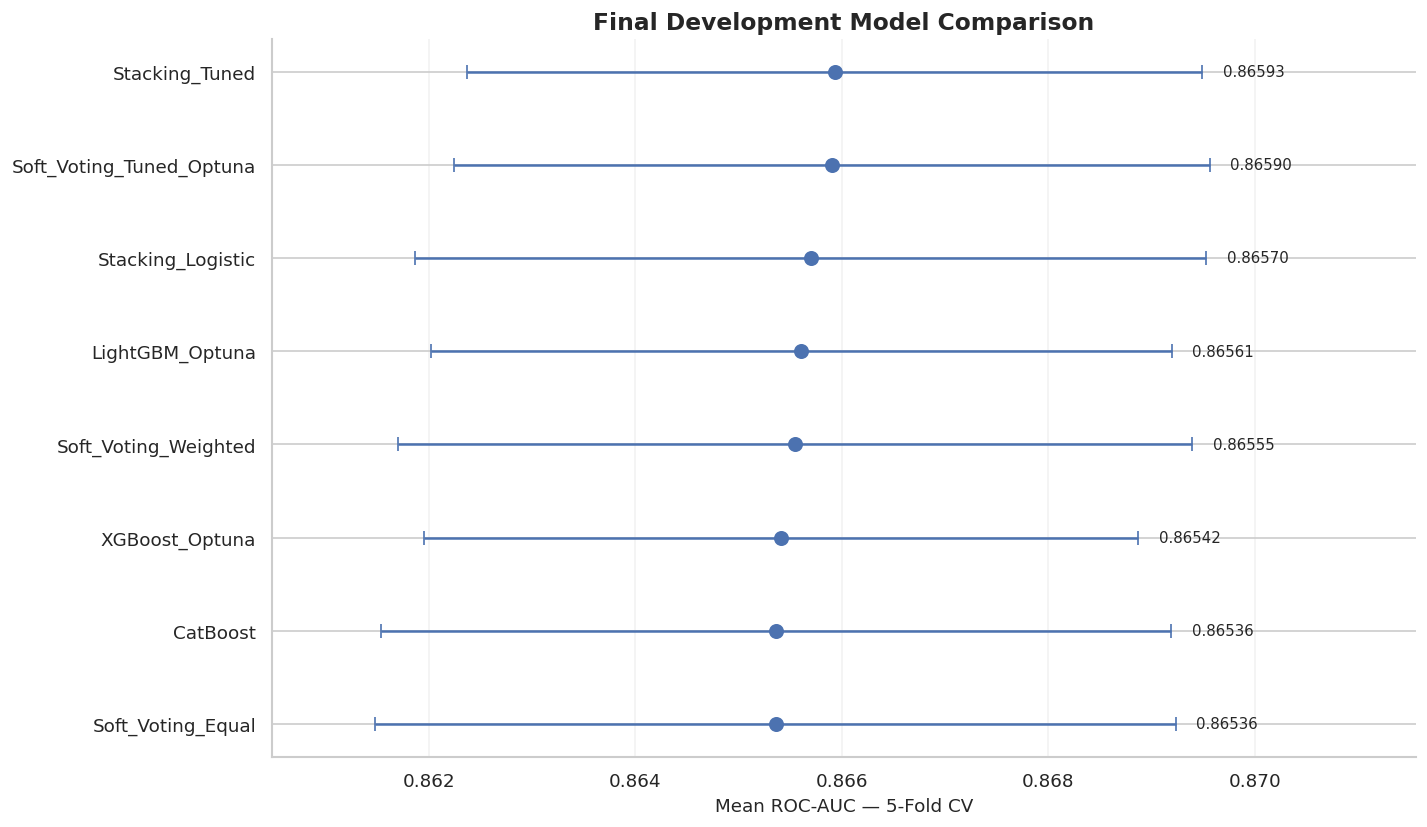


TUNED STACKING SUMMARY
Tuned Stacking ROC-AUC: 0.865934
Tuned Stacking Average Precision: 0.40348
Optimized Voting ROC-AUC: 0.865904

Highest development CV model: Stacking_Tuned
Total Tuned Stacking CV time: 369.92 seconds

Holdout dataset has NOT been used.


In [29]:
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# ------------------------------------------------------------
# 1. Verify model availability
# ------------------------------------------------------------

assert "CatBoost" in baseline_pipelines
assert "XGBoost_Optuna" in tuned_pipelines
assert "LightGBM_Optuna" in tuned_pipelines

print("=" * 65)
print("TUNED STACKING ENSEMBLE")
print("=" * 65)

print("All base learners are available.")


# ------------------------------------------------------------
# 2. Define tuned base learners
# ------------------------------------------------------------

tuned_stacking_estimators = [
    (
        "catboost",
        clone(baseline_pipelines["CatBoost"])
    ),
    (
        "xgboost",
        clone(tuned_pipelines["XGBoost_Optuna"])
    ),
    (
        "lightgbm",
        clone(tuned_pipelines["LightGBM_Optuna"])
    )
]


# ------------------------------------------------------------
# 3. Define meta learner
# ------------------------------------------------------------

tuned_meta_learner = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 4. Inner stacking CV
# ------------------------------------------------------------

tuned_stacking_inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 5. Build tuned StackingClassifier
# ------------------------------------------------------------

tuned_stacking_pipeline = StackingClassifier(
    estimators=tuned_stacking_estimators,
    final_estimator=tuned_meta_learner,
    stack_method="predict_proba",
    cv=tuned_stacking_inner_cv,
    passthrough=False,
    n_jobs=1
)

ensemble_pipelines["Stacking_Tuned"] = (
    tuned_stacking_pipeline
)

print("\nBase learners:")
print(" - Original CatBoost")
print(" - Tuned XGBoost")
print(" - Tuned LightGBM")

print("\nMeta learner: Logistic Regression")
print("Inner CV: 3 folds")
print("Outer CV:", CV_FOLDS)


# ------------------------------------------------------------
# 6. Outer 5-Fold Cross-Validation
# ------------------------------------------------------------

print("\nRunning Tuned Stacking — 5-Fold CV")

start_time = time.perf_counter()

tuned_stacking_scores = cross_validate(
    estimator=clone(tuned_stacking_pipeline),
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start_time


# ------------------------------------------------------------
# 7. Aggregate metrics
# ------------------------------------------------------------

tuned_stacking_result = {
    "Model": "Stacking_Tuned",

    "roc_auc": np.mean(
        tuned_stacking_scores["test_roc_auc"]
    ),

    "roc_auc_std": np.std(
        tuned_stacking_scores["test_roc_auc"],
        ddof=1
    ),

    "average_precision": np.mean(
        tuned_stacking_scores["test_average_precision"]
    ),

    "average_precision_std": np.std(
        tuned_stacking_scores["test_average_precision"],
        ddof=1
    ),

    "f1_macro": np.mean(
        tuned_stacking_scores["test_f1_macro"]
    ),

    "balanced_accuracy": np.mean(
        tuned_stacking_scores["test_balanced_accuracy"]
    ),

    "accuracy": np.mean(
        tuned_stacking_scores["test_accuracy"]
    ),

    "fit_time_s": np.mean(
        tuned_stacking_scores["fit_time"]
    ),

    "total_time_s": elapsed
}


# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

ensemble_results = [
    result for result in ensemble_results
    if result["Model"] != "Stacking_Tuned"
]

ensemble_results.append(
    tuned_stacking_result
)

tuned_stacking_folds_df = pd.DataFrame({
    "Fold": np.arange(1, CV_FOLDS + 1),

    "roc_auc": tuned_stacking_scores[
        "test_roc_auc"
    ],

    "average_precision": tuned_stacking_scores[
        "test_average_precision"
    ],

    "f1_macro": tuned_stacking_scores[
        "test_f1_macro"
    ],

    "balanced_accuracy": tuned_stacking_scores[
        "test_balanced_accuracy"
    ]
})

print("\nTUNED STACKING — FOLD RESULTS")

display(
    tuned_stacking_folds_df.round(6)
)


# ------------------------------------------------------------
# 9. Compare Tuned Stacking vs Optimized Voting
# ------------------------------------------------------------

paired_ensemble_comparison = (
    tuned_stacking_folds_df[
        ["Fold", "roc_auc"]
    ]
    .rename(
        columns={"roc_auc": "Stacking_AUC"}
    )
    .merge(
        optimized_voting_folds_df[
            ["Fold", "roc_auc"]
        ].rename(
            columns={"roc_auc": "Voting_AUC"}
        ),
        on="Fold",
        validate="one_to_one"
    )
)

paired_ensemble_comparison[
    "Stacking_minus_Voting"
] = (
    paired_ensemble_comparison["Stacking_AUC"]
    - paired_ensemble_comparison["Voting_AUC"]
)

print("\nPAIRED ENSEMBLE COMPARISON")

display(
    paired_ensemble_comparison.round(6)
)

print(
    "\nMean ROC-AUC difference:",
    round(
        paired_ensemble_comparison[
            "Stacking_minus_Voting"
        ].mean(),
        6
    )
)


# ------------------------------------------------------------
# 10. Build final development leaderboard
# ------------------------------------------------------------

all_model_results = pd.concat(
    [
        baseline_comparison,
        tuned_comparison,
        pd.DataFrame(ensemble_results)
    ],
    ignore_index=True
)

all_model_results = (
    all_model_results
    .drop_duplicates(
        subset=["Model"],
        keep="last"
    )
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("FINAL DEVELOPMENT MODEL LEADERBOARD")
print("=" * 65)

display(
    all_model_results[
        [
            "Model",
            "roc_auc",
            "roc_auc_std",
            "average_precision",
            "f1_macro",
            "balanced_accuracy",
            "total_time_s"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 11. Visualize top model performance
# ------------------------------------------------------------

top_models = (
    all_model_results
    .head(8)
    .sort_values("roc_auc")
)

fig, ax = plt.subplots(figsize=(12, 7))

positions = np.arange(len(top_models))

ax.errorbar(
    top_models["roc_auc"],
    positions,
    xerr=top_models["roc_auc_std"],
    fmt="o",
    capsize=4,
    markersize=8
)

ax.set_yticks(positions)
ax.set_yticklabels(top_models["Model"])

ax.set_xlabel("Mean ROC-AUC — 5-Fold CV")
ax.set_title(
    "Final Development Model Comparison",
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)

x_min = (
    top_models["roc_auc"]
    - top_models["roc_auc_std"]
).min() - 0.001

x_max = (
    top_models["roc_auc"]
    + top_models["roc_auc_std"]
).max() + 0.002

ax.set_xlim(x_min, x_max)

for i, row in enumerate(top_models.itertuples()):

    ax.text(
        row.roc_auc + row.roc_auc_std + 0.0002,
        i,
        f"{row.roc_auc:.5f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Summary
# ------------------------------------------------------------

best_development_model = (
    all_model_results.iloc[0]["Model"]
)

print("\n" + "=" * 65)
print("TUNED STACKING SUMMARY")
print("=" * 65)

print(
    "Tuned Stacking ROC-AUC:",
    round(tuned_stacking_result["roc_auc"], 6)
)

print(
    "Tuned Stacking Average Precision:",
    round(tuned_stacking_result["average_precision"], 6)
)

print(
    "Optimized Voting ROC-AUC:",
    round(optimized_voting_result["roc_auc"], 6)
)

print(
    "\nHighest development CV model:",
    best_development_model
)

print(
    "Total Tuned Stacking CV time:",
    round(elapsed, 2),
    "seconds"
)

print("\nHoldout dataset has NOT been used.")

# Final Model Selection & Calibration Diagnostics

FINAL MODEL SELECTION
Selected model: Stacking_Tuned
Backup model: LightGBM_Optuna


,Model,roc_auc,roc_auc_std,average_precision,f1_macro,total_time_s
0,Stacking_Tuned,0.865934,0.003560,0.403480,0.644344,369.919750
1,Soft_Voting_Tuned_Optuna,0.865904,0.003659,0.403392,0.627539,384.647489
3,LightGBM_Optuna,0.865608,0.003586,0.403156,0.626202,35.092742



Generating final model OOF probabilities...
OOF predictions generated successfully.
Total observations: 120000
Elapsed seconds: 386.22

OUT-OF-FOLD PERFORMANCE DIAGNOSTICS


,Model,ROC_AUC,Average_Precision,Brier_Score,Log_Loss
0,Stacking_Tuned,0.865752,0.402386,0.050452,0.188007


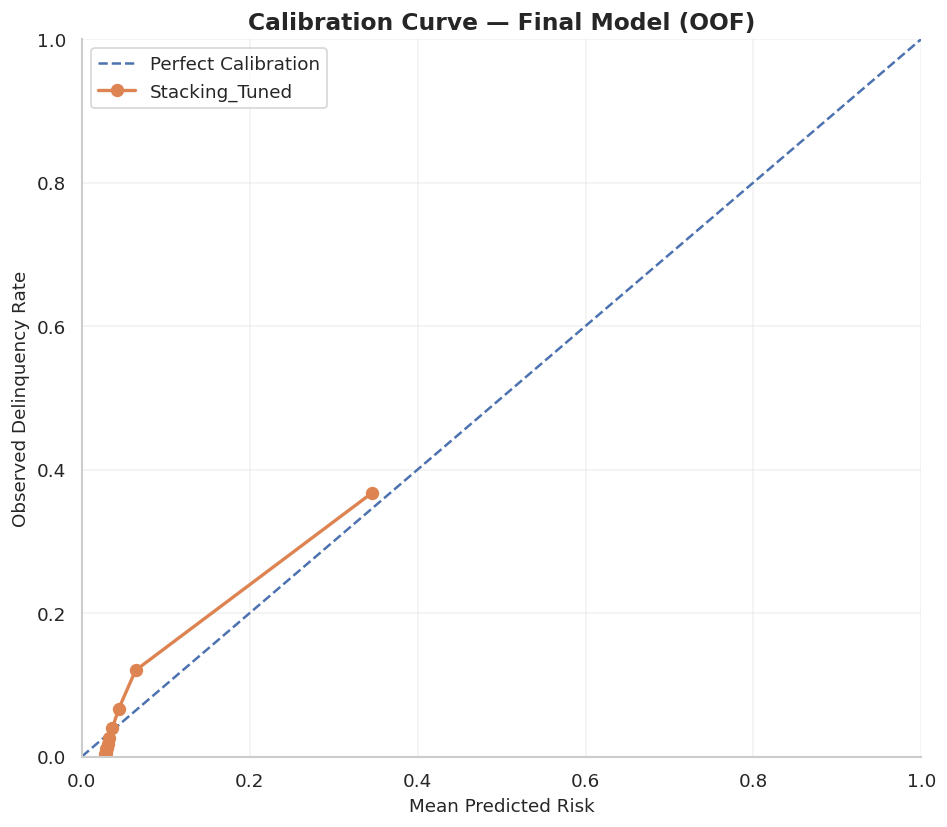

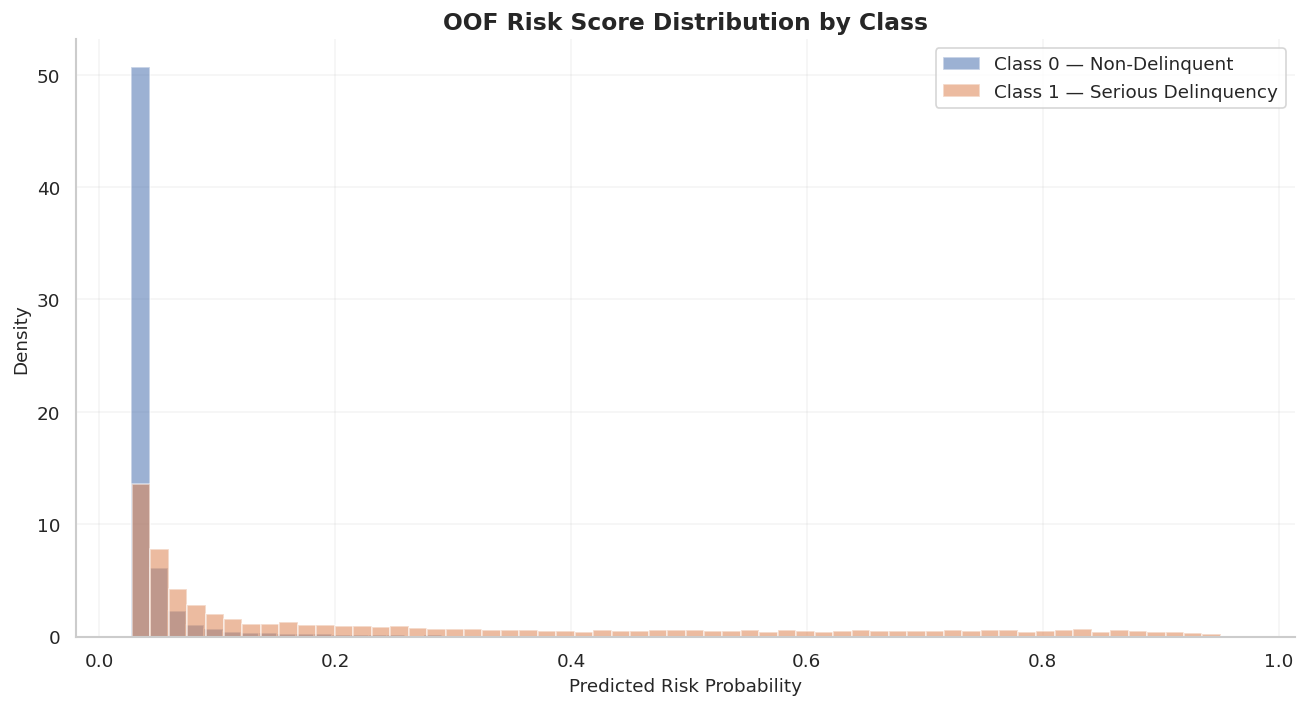


CALIBRATION TABLE


,Mean_Predicted_Probability,Observed_Event_Rate
0,0.028047,0.003333
1,0.028557,0.005333
2,0.029069,0.010750
3,0.029699,0.012000
4,0.030718,0.016917
5,0.032689,0.026333
6,0.036396,0.039750
7,0.043772,0.066250
8,0.063955,0.120083
9,0.345983,0.367667



FINAL DEVELOPMENT STATUS
Selected model: Stacking_Tuned
OOF ROC-AUC: 0.865752
OOF Average Precision: 0.402386
OOF Brier Score: 0.050452
OOF Log Loss: 0.188007

Holdout dataset has NOT been used.
Final model is selected but not yet fitted.


In [30]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# 1. Lock final model candidate
# ------------------------------------------------------------

FINAL_MODEL_NAME = "Stacking_Tuned"
BACKUP_MODEL_NAME = "LightGBM_Optuna"

final_model_pipeline = clone(
    ensemble_pipelines[FINAL_MODEL_NAME]
)

backup_model_pipeline = clone(
    tuned_pipelines[BACKUP_MODEL_NAME]
)

print("=" * 65)
print("FINAL MODEL SELECTION")
print("=" * 65)

print("Selected model:", FINAL_MODEL_NAME)
print("Backup model:", BACKUP_MODEL_NAME)

# Retrieve development results
selection_table = all_model_results[
    all_model_results["Model"].isin([
        FINAL_MODEL_NAME,
        BACKUP_MODEL_NAME,
        "Soft_Voting_Tuned_Optuna"
    ])
][[
    "Model",
    "roc_auc",
    "roc_auc_std",
    "average_precision",
    "f1_macro",
    "total_time_s"
]].copy()

display(
    selection_table
    .sort_values("roc_auc", ascending=False)
    .round(6)
)


# ------------------------------------------------------------
# 2. Generate out-of-fold predictions
# ------------------------------------------------------------

print("\nGenerating final model OOF probabilities...")

start_time = time.perf_counter()

y_development = np.asarray(
    y_train
).astype(int).ravel()

final_oof_probabilities = cross_val_predict(
    estimator=clone(final_model_pipeline),
    X=X_train,
    y=y_development,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

oof_elapsed = time.perf_counter() - start_time

assert len(final_oof_probabilities) == len(y_development)
assert np.isfinite(final_oof_probabilities).all()
assert np.all(
    (final_oof_probabilities >= 0) &
    (final_oof_probabilities <= 1)
)

print("OOF predictions generated successfully.")
print("Total observations:", len(final_oof_probabilities))
print("Elapsed seconds:", round(oof_elapsed, 2))


# ------------------------------------------------------------
# 3. OOF performance diagnostics
# ------------------------------------------------------------

final_oof_metrics = {
    "Model": FINAL_MODEL_NAME,
    "ROC_AUC": roc_auc_score(
        y_development,
        final_oof_probabilities
    ),
    "Average_Precision": average_precision_score(
        y_development,
        final_oof_probabilities
    ),
    "Brier_Score": brier_score_loss(
        y_development,
        final_oof_probabilities
    ),
    "Log_Loss": log_loss(
        y_development,
        final_oof_probabilities
    )
}

print("\n" + "=" * 65)
print("OUT-OF-FOLD PERFORMANCE DIAGNOSTICS")
print("=" * 65)

display(
    pd.DataFrame([final_oof_metrics]).round(6)
)


# ------------------------------------------------------------
# 4. Calibration curve
# ------------------------------------------------------------

fraction_positive, mean_predicted = calibration_curve(
    y_development,
    final_oof_probabilities,
    n_bins=10,
    strategy="quantile"
)

calibration_table = pd.DataFrame({
    "Mean_Predicted_Probability": mean_predicted,
    "Observed_Event_Rate": fraction_positive
})

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

ax.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    markersize=7,
    label=FINAL_MODEL_NAME
)

ax.set_xlabel("Mean Predicted Risk")
ax.set_ylabel("Observed Delinquency Rate")

ax.set_title(
    "Calibration Curve — Final Model (OOF)",
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Risk score distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    final_oof_probabilities[y_development == 0],
    bins=60,
    density=True,
    alpha=0.55,
    label="Class 0 — Non-Delinquent"
)

ax.hist(
    final_oof_probabilities[y_development == 1],
    bins=60,
    density=True,
    alpha=0.55,
    label="Class 1 — Serious Delinquency"
)

ax.set_xlabel("Predicted Risk Probability")
ax.set_ylabel("Density")

ax.set_title(
    "OOF Risk Score Distribution by Class",
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\nCALIBRATION TABLE")
display(calibration_table.round(6))

print("\n" + "=" * 65)
print("FINAL DEVELOPMENT STATUS")
print("=" * 65)

print("Selected model:", FINAL_MODEL_NAME)

print(
    "OOF ROC-AUC:",
    round(final_oof_metrics["ROC_AUC"], 6)
)

print(
    "OOF Average Precision:",
    round(final_oof_metrics["Average_Precision"], 6)
)

print(
    "OOF Brier Score:",
    round(final_oof_metrics["Brier_Score"], 6)
)

print(
    "OOF Log Loss:",
    round(final_oof_metrics["Log_Loss"], 6)
)

print("\nHoldout dataset has NOT been used.")
print("Final model is selected but not yet fitted.")

# Final Stacking Threshold Optimization

FINAL STACKING — THRESHOLD OPTIMIZATION
Model: Stacking_Tuned
Observations: 120000
Positive class rate: 0.06684
Minimum Recall target: 0.78

FINAL STACKING — THRESHOLD COMPARISON


,Strategy,Threshold,Precision,Recall,F1,F2,TP,FP,FN,TN
0,Default_0.50,0.500000,0.578317,0.222790,0.321663,0.254023,1787,1303,6234,110676
1,Maximize_F2,0.060326,0.291174,0.660142,0.404106,0.526667,5295,12890,2726,99089
2,Recall_78_Percent,0.044160,0.214631,0.780202,0.336651,0.510932,6258,22899,1763,89080


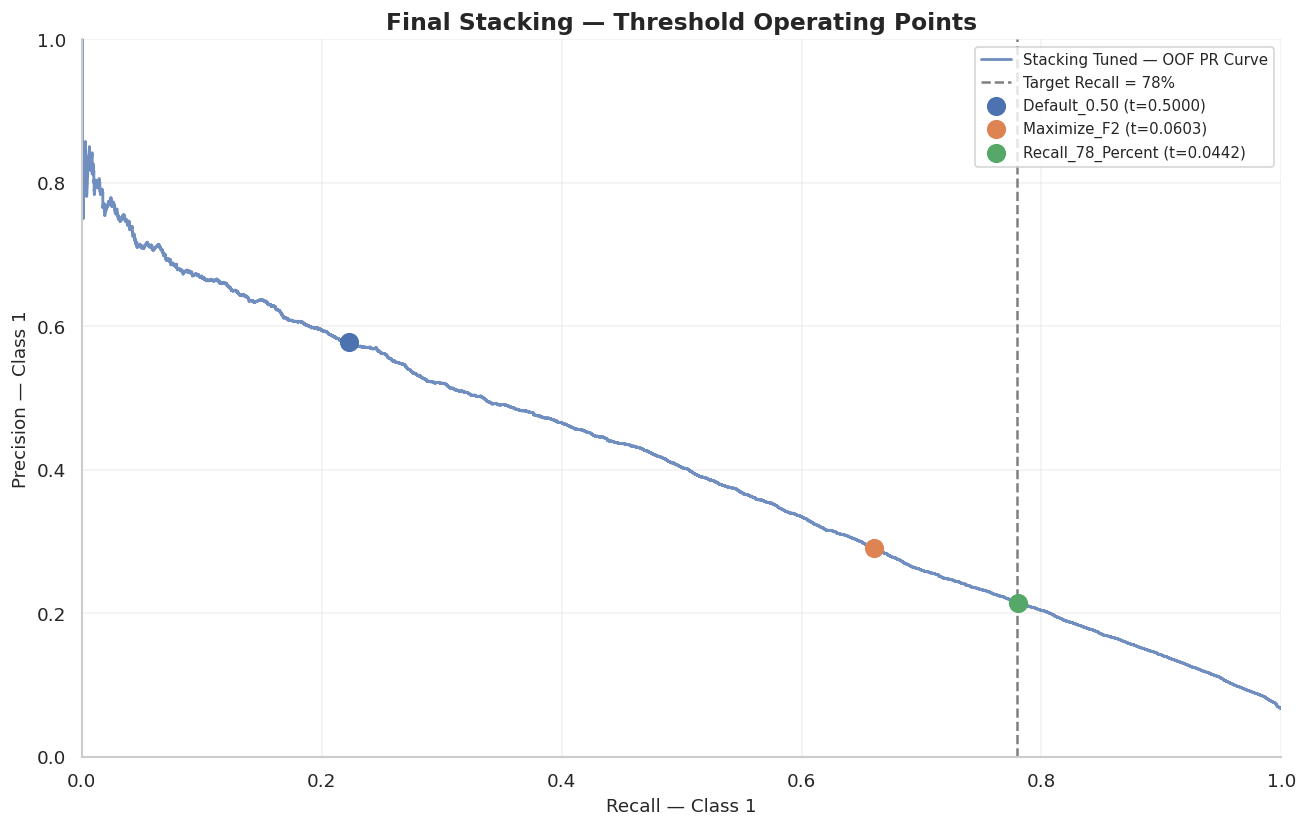

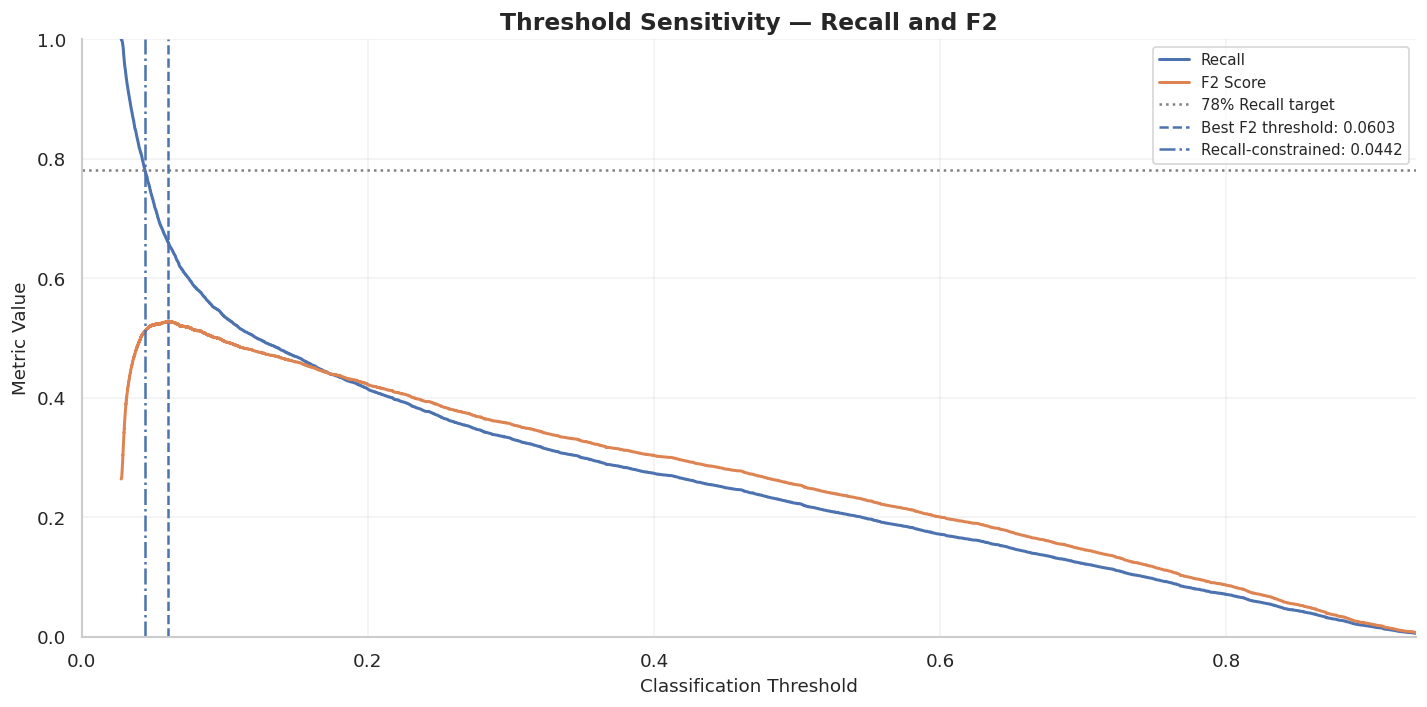

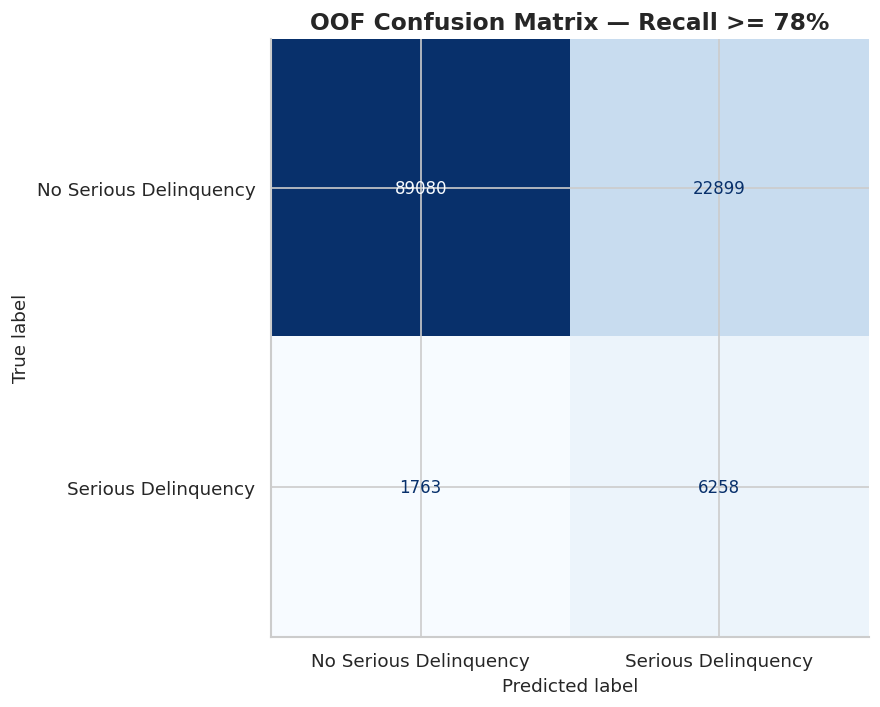


THRESHOLD OPTIMIZATION SUMMARY
Default threshold: 0.5
Maximum F2 candidate: 0.060326
Recall >= 78% candidate: 0.04416

These thresholds are development candidates.
They have not been independently validated.
Holdout dataset has NOT been used.


In [31]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Configuration and validation
# ------------------------------------------------------------

TARGET_RECALL = 0.78
DEFAULT_THRESHOLD = 0.50

y_true = np.asarray(y_development).astype(int).ravel()
y_score = np.asarray(
    final_oof_probabilities,
    dtype=float
).ravel()

assert len(y_true) == len(y_score)
assert set(np.unique(y_true)) == {0, 1}
assert np.isfinite(y_score).all()
assert np.all((y_score >= 0) & (y_score <= 1))

print("=" * 65)
print("FINAL STACKING — THRESHOLD OPTIMIZATION")
print("=" * 65)

print("Model:", FINAL_MODEL_NAME)
print("Observations:", len(y_true))
print("Positive class rate:", round(y_true.mean(), 5))
print("Minimum Recall target:", TARGET_RECALL)


# ------------------------------------------------------------
# 2. Precision-Recall curve
# ------------------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_score
)

# Last point has no corresponding threshold
precision_values = precision[:-1]
recall_values = recall[:-1]

# F2 = 5 * Precision * Recall / (4 * Precision + Recall)
f2_values = np.divide(
    5 * precision_values * recall_values,
    4 * precision_values + recall_values,
    out=np.zeros_like(precision_values),
    where=(4 * precision_values + recall_values) > 0
)

threshold_candidates = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_values,
    "Recall": recall_values,
    "F2": f2_values
})


# ------------------------------------------------------------
# 3. Optimize F2 Score
# ------------------------------------------------------------

best_f2_row = (
    threshold_candidates
    .sort_values(
        ["F2", "Threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

best_f2_threshold = float(
    best_f2_row["Threshold"]
)


# ------------------------------------------------------------
# 4. Optimize Precision subject to Recall >= 78%
# ------------------------------------------------------------

feasible_candidates = threshold_candidates.loc[
    threshold_candidates["Recall"] >= TARGET_RECALL
].copy()

if feasible_candidates.empty:
    raise ValueError(
        "No threshold satisfies the Recall constraint."
    )

best_recall_row = (
    feasible_candidates
    .sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

best_recall_threshold = float(
    best_recall_row["Threshold"]
)


# ------------------------------------------------------------
# 5. Evaluation helper
# ------------------------------------------------------------

def threshold_metrics(name, threshold):

    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Strategy": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_true, y_pred, beta=2,
            zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


# ------------------------------------------------------------
# 6. Compare operating points
# ------------------------------------------------------------

final_threshold_table = pd.DataFrame([
    threshold_metrics(
        "Default_0.50",
        DEFAULT_THRESHOLD
    ),
    threshold_metrics(
        "Maximize_F2",
        best_f2_threshold
    ),
    threshold_metrics(
        "Recall_78_Percent",
        best_recall_threshold
    )
])

print("\n" + "=" * 65)
print("FINAL STACKING — THRESHOLD COMPARISON")
print("=" * 65)

display(final_threshold_table.round(6))


# ------------------------------------------------------------
# 7. Precision-Recall visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

ax.plot(
    recall,
    precision,
    linewidth=1.7,
    alpha=0.8,
    label="Stacking Tuned — OOF PR Curve"
)

ax.axvline(
    TARGET_RECALL,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Target Recall = 78%"
)

for row in final_threshold_table.itertuples():

    ax.scatter(
        row.Recall,
        row.Precision,
        s=110,
        zorder=5,
        label=(
            f"{row.Strategy} "
            f"(t={row.Threshold:.4f})"
        )
    )

ax.set_xlabel("Recall — Class 1")
ax.set_ylabel("Precision — Class 1")

ax.set_title(
    "Final Stacking — Threshold Operating Points",
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. F2 and Recall versus threshold
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    thresholds,
    recall_values,
    label="Recall",
    linewidth=1.8
)

ax.plot(
    thresholds,
    f2_values,
    label="F2 Score",
    linewidth=1.8
)

ax.axhline(
    TARGET_RECALL,
    linestyle=":",
    color="gray",
    label="78% Recall target"
)

ax.axvline(
    best_f2_threshold,
    linestyle="--",
    label=f"Best F2 threshold: {best_f2_threshold:.4f}"
)

ax.axvline(
    best_recall_threshold,
    linestyle="-.",
    label=f"Recall-constrained: {best_recall_threshold:.4f}"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Metric Value")

ax.set_title(
    "Threshold Sensitivity — Recall and F2",
    fontweight="bold"
)

ax.set_xlim(
    0,
    min(
        1.0,
        max(
            0.55,
            np.quantile(y_score, 0.999) + 0.02
        )
    )
)

ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Confusion Matrix at Recall >= 78%
# ------------------------------------------------------------

y_pred_recall = (
    y_score >= best_recall_threshold
).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred_recall,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Serious Delinquency",
        "Serious Delinquency"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "OOF Confusion Matrix — Recall >= 78%",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Save selected candidate thresholds
# ------------------------------------------------------------

FINAL_THRESHOLD_DEFAULT = DEFAULT_THRESHOLD
FINAL_THRESHOLD_F2_CANDIDATE = best_f2_threshold

FINAL_THRESHOLD_RECALL_CANDIDATE = (
    best_recall_threshold
)

print("\n" + "=" * 65)
print("THRESHOLD OPTIMIZATION SUMMARY")
print("=" * 65)

print(
    "Default threshold:",
    round(FINAL_THRESHOLD_DEFAULT, 6)
)

print(
    "Maximum F2 candidate:",
    round(FINAL_THRESHOLD_F2_CANDIDATE, 6)
)

print(
    "Recall >= 78% candidate:",
    round(FINAL_THRESHOLD_RECALL_CANDIDATE, 6)
)

print("\nThese thresholds are development candidates.")
print("They have not been independently validated.")
print("Holdout dataset has NOT been used.")

# Model Calibration: Sigmoid vs Isotonic Regression

MODEL CALIBRATION — DATA SPLIT
Base model training: 84000
Calibration fitting: 18000
Calibration evaluation: 18000
Calibration evaluation positive rate: 0.066833

Training Stacking model for calibration study...
Base model training time: 59.79 seconds

MODEL CALIBRATION COMPARISON


,Method,ROC_AUC,Average_Precision,Brier_Score,Log_Loss,ECE,Mean_Predicted_Risk
0,Isotonic,0.860408,0.390501,0.049157,0.179235,0.003999,0.065323
1,Sigmoid,0.860929,0.403129,0.050304,0.188904,0.021407,0.065713
2,Uncalibrated,0.860929,0.403129,0.050358,0.188853,0.020330,0.065604


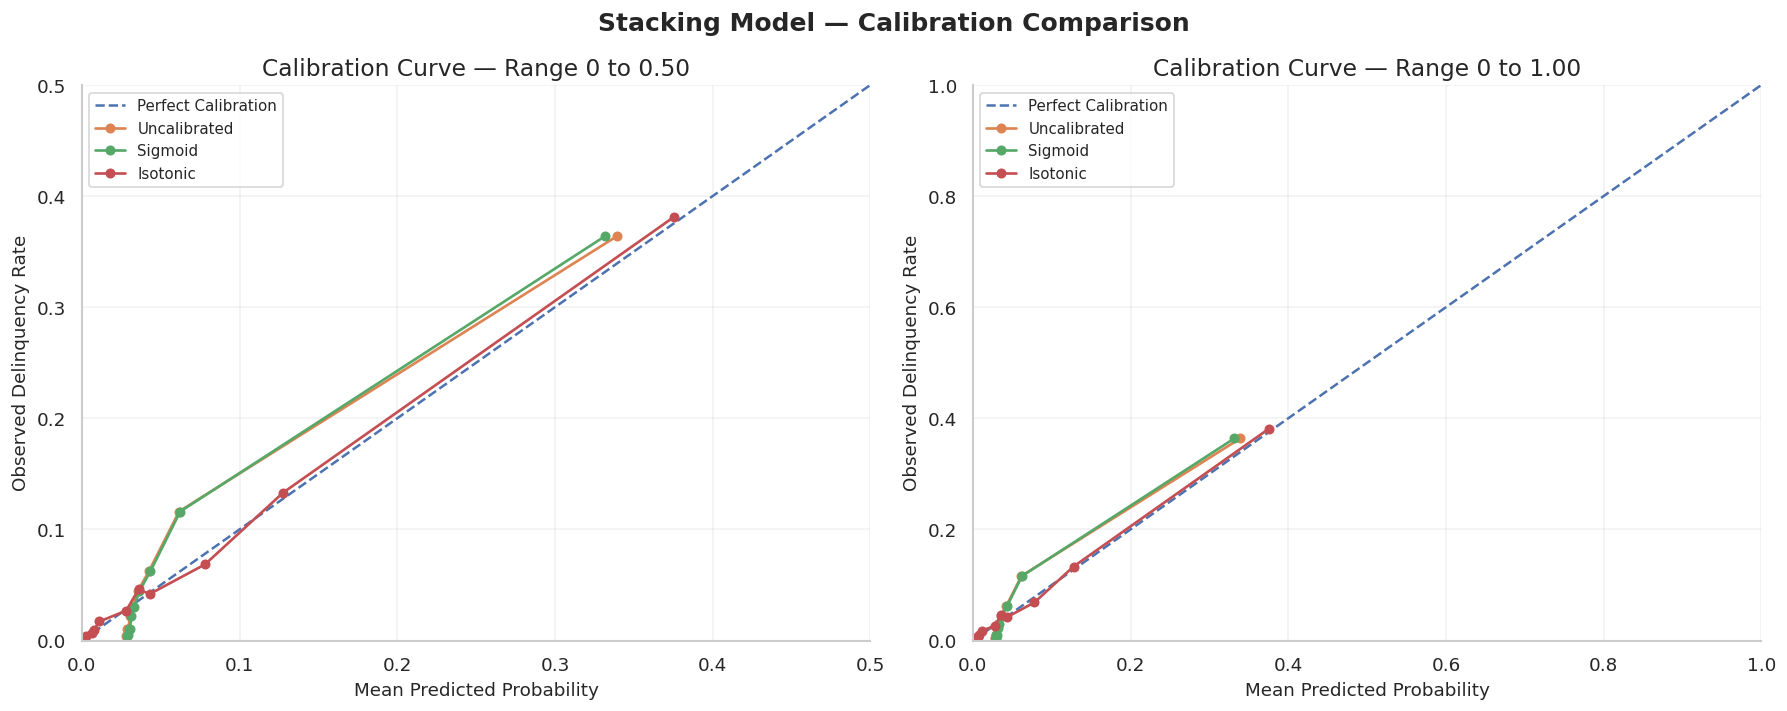

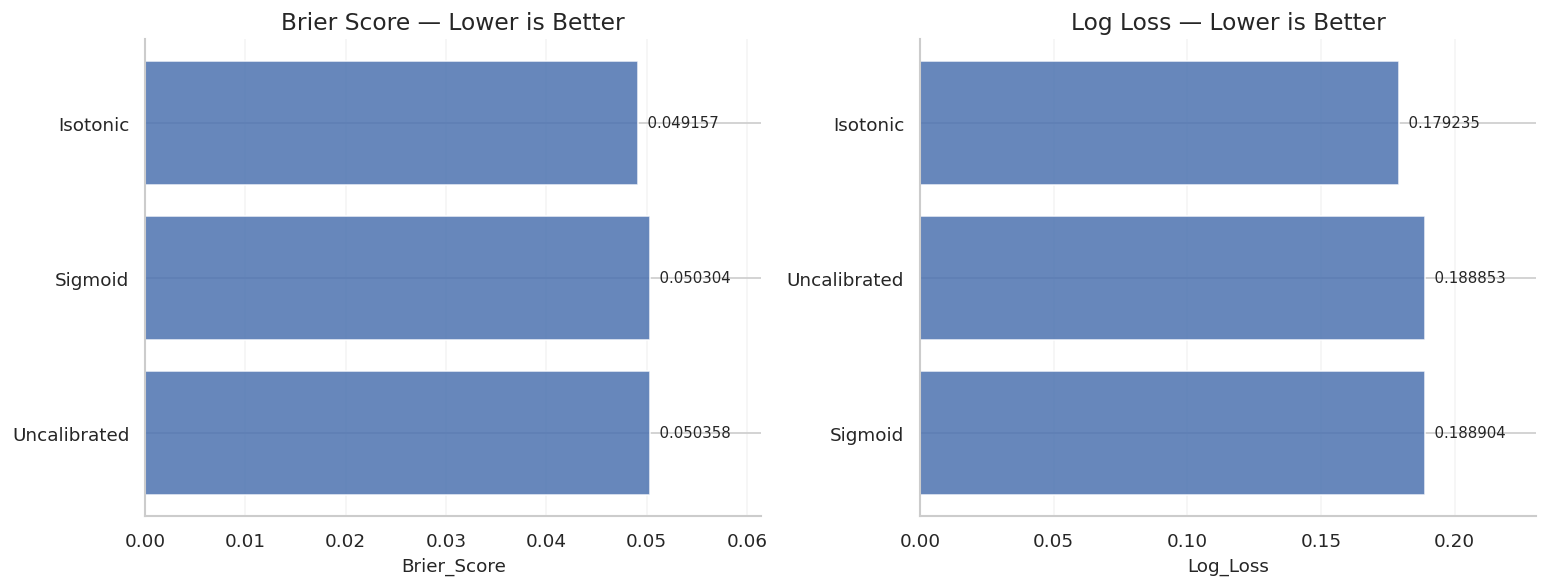


CALIBRATION SELECTION
Best calibration method by Brier Score: Isotonic
Selected validation Brier Score: 0.049157
Selected validation Log Loss: 0.179235

Observed positive class rate: 0.066833
Uncalibrated mean predicted risk: 0.065604

Calibration method is a development candidate.
Final calibration will be refitted on development data.
Holdout dataset has NOT been used.


In [32]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
from sklearn.calibration import calibration_curve
from scipy.special import logit

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CALIBRATION_RANDOM_STATE = RANDOM_STATE

X_dev = X_train.copy()
y_dev = np.asarray(y_train).astype(int).ravel()

all_indices = np.arange(len(X_dev))

# 70% base training, 30% remaining
fit_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=y_dev,
    random_state=CALIBRATION_RANDOM_STATE
)

# Split remaining 30% equally into 15% + 15%
cal_idx, eval_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    stratify=y_dev[remaining_idx],
    random_state=CALIBRATION_RANDOM_STATE
)

X_model_fit = X_dev.iloc[fit_idx]
y_model_fit = y_dev[fit_idx]

X_calibration_fit = X_dev.iloc[cal_idx]
y_calibration_fit = y_dev[cal_idx]

X_calibration_eval = X_dev.iloc[eval_idx]
y_calibration_eval = y_dev[eval_idx]

assert len(set(fit_idx) & set(cal_idx)) == 0
assert len(set(fit_idx) & set(eval_idx)) == 0
assert len(set(cal_idx) & set(eval_idx)) == 0

print("=" * 65)
print("MODEL CALIBRATION — DATA SPLIT")
print("=" * 65)

print("Base model training:", len(X_model_fit))
print("Calibration fitting:", len(X_calibration_fit))
print("Calibration evaluation:", len(X_calibration_eval))

print(
    "Calibration evaluation positive rate:",
    round(y_calibration_eval.mean(), 6)
)


# ------------------------------------------------------------
# 2. Train base Stacking model
# ------------------------------------------------------------

calibration_base_model = clone(
    final_model_pipeline
)

print("\nTraining Stacking model for calibration study...")

start_time = time.perf_counter()

calibration_base_model.fit(
    X_model_fit,
    y_model_fit
)

print(
    "Base model training time:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)


# ------------------------------------------------------------
# 3. Generate probabilities
# ------------------------------------------------------------

# Predictions for fitting the calibrators
calibration_fit_scores = (
    calibration_base_model.predict_proba(
        X_calibration_fit
    )[:, 1]
)

# Untouched calibration evaluation data
raw_eval_scores = (
    calibration_base_model.predict_proba(
        X_calibration_eval
    )[:, 1]
)

assert np.isfinite(calibration_fit_scores).all()
assert np.isfinite(raw_eval_scores).all()


# ------------------------------------------------------------
# 4. Sigmoid / Platt Scaling
# ------------------------------------------------------------

# Apply logistic calibration to log-odds scores.
# Clip scores to avoid infinite logit values.

EPS = 1e-6

calibration_fit_logits = logit(
    np.clip(
        calibration_fit_scores,
        EPS,
        1 - EPS
    )
).reshape(-1, 1)

eval_logits = logit(
    np.clip(
        raw_eval_scores,
        EPS,
        1 - EPS
    )
).reshape(-1, 1)

sigmoid_calibrator = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=RANDOM_STATE
)

sigmoid_calibrator.fit(
    calibration_fit_logits,
    y_calibration_fit
)

sigmoid_eval_scores = (
    sigmoid_calibrator.predict_proba(
        eval_logits
    )[:, 1]
)


# ------------------------------------------------------------
# 5. Isotonic Regression
# ------------------------------------------------------------

isotonic_calibrator = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    calibration_fit_scores,
    y_calibration_fit
)

isotonic_eval_scores = (
    isotonic_calibrator.predict(
        raw_eval_scores
    )
)


# ------------------------------------------------------------
# 6. Gather predictions
# ------------------------------------------------------------

calibration_predictions = {
    "Uncalibrated": raw_eval_scores,
    "Sigmoid": sigmoid_eval_scores,
    "Isotonic": isotonic_eval_scores
}


# ------------------------------------------------------------
# 7. Expected Calibration Error (ECE)
# ------------------------------------------------------------

def expected_calibration_error(
    y_true,
    y_probability,
    n_bins=10
):
    """
    Quantile-binned Expected Calibration Error.
    Lower is better.

    ECE is a diagnostic estimate and depends on
    the binning strategy.
    """

    df = pd.DataFrame({
        "label": np.asarray(y_true),
        "score": np.asarray(y_probability)
    })

    df["bin"] = pd.qcut(
        df["score"],
        q=n_bins,
        labels=False,
        duplicates="drop"
    )

    summary = df.groupby(
        "bin",
        observed=True
    ).agg(
        count=("label", "size"),
        observed_rate=("label", "mean"),
        mean_score=("score", "mean")
    )

    if summary.empty:
        return np.nan

    weighted_gap = (
        summary["count"]
        * np.abs(
            summary["observed_rate"]
            - summary["mean_score"]
        )
    ).sum()

    return float(weighted_gap / len(df))


# ------------------------------------------------------------
# 8. Compare calibration methods
# ------------------------------------------------------------

calibration_results = []

for method_name, probabilities in (
    calibration_predictions.items()
):

    calibration_results.append({
        "Method": method_name,

        "ROC_AUC": roc_auc_score(
            y_calibration_eval,
            probabilities
        ),

        "Average_Precision": average_precision_score(
            y_calibration_eval,
            probabilities
        ),

        "Brier_Score": brier_score_loss(
            y_calibration_eval,
            probabilities
        ),

        "Log_Loss": log_loss(
            y_calibration_eval,
            probabilities,
            labels=[0, 1]
        ),

        "ECE": expected_calibration_error(
            y_calibration_eval,
            probabilities,
            n_bins=10
        ),

        "Mean_Predicted_Risk": np.mean(
            probabilities
        )
    })

calibration_comparison = (
    pd.DataFrame(calibration_results)
    .sort_values(
        ["Brier_Score", "Log_Loss"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("MODEL CALIBRATION COMPARISON")
print("=" * 65)

display(
    calibration_comparison.round(6)
)


# ------------------------------------------------------------
# 9. Calibration curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

for ax, max_probability in zip(
    axes,
    [0.50, 1.00]
):

    ax.plot(
        [0, max_probability],
        [0, max_probability],
        linestyle="--",
        linewidth=1.5,
        label="Perfect Calibration"
    )

    for method_name, probabilities in (
        calibration_predictions.items()
    ):

        observed_rate, predicted_rate = (
            calibration_curve(
                y_calibration_eval,
                probabilities,
                n_bins=10,
                strategy="quantile"
            )
        )

        ax.plot(
            predicted_rate,
            observed_rate,
            marker="o",
            markersize=5,
            linewidth=1.6,
            label=method_name
        )

    ax.set_xlim(0, max_probability)
    ax.set_ylim(0, max_probability)

    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Delinquency Rate")

    ax.set_title(
        f"Calibration Curve — Range 0 to {max_probability:.2f}"
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "Stacking Model — Calibration Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Brier Score and Log Loss charts
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

metric_names = [
    ("Brier_Score", "Brier Score — Lower is Better"),
    ("Log_Loss", "Log Loss — Lower is Better")
]

for ax, (metric, title) in zip(
    axes,
    metric_names
):

    plot_df = calibration_comparison.sort_values(
        metric,
        ascending=False
    )

    ax.barh(
        plot_df["Method"],
        plot_df[metric],
        alpha=0.85
    )

    ax.set_xlabel(metric)
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)

    for i, value in enumerate(plot_df[metric]):
        ax.text(
            value,
            i,
            f"  {value:.6f}",
            va="center",
            fontsize=9
        )

    ax.set_xlim(
        0,
        max(plot_df[metric]) * 1.22
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Select calibration candidate
# ------------------------------------------------------------

# Primary selection metric: Brier Score
# Tie-breaker: Log Loss

SELECTED_CALIBRATION_METHOD = (
    calibration_comparison.iloc[0]["Method"]
)

print("\n" + "=" * 65)
print("CALIBRATION SELECTION")
print("=" * 65)

print(
    "Best calibration method by Brier Score:",
    SELECTED_CALIBRATION_METHOD
)

print(
    "Selected validation Brier Score:",
    round(
        calibration_comparison.iloc[0]["Brier_Score"],
        6
    )
)

print(
    "Selected validation Log Loss:",
    round(
        calibration_comparison.iloc[0]["Log_Loss"],
        6
    )
)

print(
    "\nObserved positive class rate:",
    round(y_calibration_eval.mean(), 6)
)

print(
    "Uncalibrated mean predicted risk:",
    round(raw_eval_scores.mean(), 6)
)

# Store fitted split-based calibrators for diagnostics.
# These are NOT the final full-development calibrators.
calibration_diagnostic_models = {
    "Sigmoid": sigmoid_calibrator,
    "Isotonic": isotonic_calibrator
}

print("\nCalibration method is a development candidate.")
print("Final calibration will be refitted on development data.")
print("Holdout dataset has NOT been used.")

# Final Calibration Refit & Threshold Update

In [33]:
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    fbeta_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

FINAL_CALIBRATION_METHOD = "Isotonic"
TARGET_RECALL = 0.78

y_dev = np.asarray(y_train).astype(int).ravel()

raw_oof = np.asarray(
    final_oof_probabilities,
    dtype=float
).ravel()

assert len(raw_oof) == len(y_dev)
assert np.isfinite(raw_oof).all()
assert np.all((raw_oof >= 0) & (raw_oof <= 1))

print("=" * 65)
print("FINAL CALIBRATION REFIT")
print("=" * 65)

print("Base model:", FINAL_MODEL_NAME)
print("Calibration method:", FINAL_CALIBRATION_METHOD)
print("Development observations:", len(y_dev))


# ------------------------------------------------------------
# 2. Cross-fitted calibration predictions
# ------------------------------------------------------------

calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 500
)

calibrated_oof = np.full(
    len(y_dev),
    np.nan,
    dtype=float
)

for fold, (fit_idx, valid_idx) in enumerate(
    calibration_cv.split(
        raw_oof.reshape(-1, 1),
        y_dev
    ),
    start=1
):

    calibrator = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        out_of_bounds="clip"
    )

    calibrator.fit(
        raw_oof[fit_idx],
        y_dev[fit_idx]
    )

    calibrated_oof[valid_idx] = (
        calibrator.predict(raw_oof[valid_idx])
    )

    print(f"Calibration fold {fold}/5 completed.")

assert np.isfinite(calibrated_oof).all()

# Cross-fitting avoids evaluating a calibrator
# directly on its own calibration-fitting labels.
# These are still development predictions, not
# a fully independent estimate of final performance.


# ------------------------------------------------------------
# 3. Recompute thresholds after calibration
# ------------------------------------------------------------

precision, recall, thresholds = (
    precision_recall_curve(
        y_dev,
        calibrated_oof
    )
)

threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

threshold_df["F2"] = np.divide(
    5 * threshold_df["Precision"]
      * threshold_df["Recall"],
    4 * threshold_df["Precision"]
      + threshold_df["Recall"],
    out=np.zeros(len(threshold_df)),
    where=(
        4 * threshold_df["Precision"]
        + threshold_df["Recall"]
    ) > 0
)

# Maximum F2
best_f2 = (
    threshold_df
    .sort_values(
        ["F2", "Threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

CALIBRATED_THRESHOLD_F2 = float(
    best_f2["Threshold"]
)

# Recall >= 78%
feasible = threshold_df[
    threshold_df["Recall"] >= TARGET_RECALL
].copy()

if feasible.empty:
    raise ValueError(
        "No threshold satisfies Recall >= 78%."
    )

best_recall = (
    feasible
    .sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

CALIBRATED_THRESHOLD_RECALL78 = float(
    best_recall["Threshold"]
)


# ------------------------------------------------------------
# 4. Evaluate candidate thresholds
# ------------------------------------------------------------

def evaluate_calibrated_threshold(name, threshold):

    pred = (
        calibrated_oof >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_dev,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Strategy": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_dev, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_dev, pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_dev, pred,
            beta=2,
            zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


calibrated_threshold_comparison = pd.DataFrame([
    evaluate_calibrated_threshold(
        "Default_0.50", 0.50
    ),
    evaluate_calibrated_threshold(
        "Maximum_F2",
        CALIBRATED_THRESHOLD_F2
    ),
    evaluate_calibrated_threshold(
        "Recall_78_Percent",
        CALIBRATED_THRESHOLD_RECALL78
    )
])

print("\nCALIBRATED THRESHOLD COMPARISON")

display(
    calibrated_threshold_comparison.round(6)
)


# ------------------------------------------------------------
# 5. Fit final Isotonic calibrator
# ------------------------------------------------------------

final_isotonic_calibrator = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

final_isotonic_calibrator.fit(
    raw_oof,
    y_dev
)

print("\nFinal Isotonic calibrator fitted.")


# ------------------------------------------------------------
# 6. Train final Stacking on all development data
# ------------------------------------------------------------

print("\nFitting final Stacking on 120,000 observations...")

start_time = time.perf_counter()

final_development_model_fitted = clone(
    final_model_pipeline
)

final_development_model_fitted.fit(
    X_train,
    y_dev
)

elapsed = time.perf_counter() - start_time

print(
    "Final Stacking training time:",
    round(elapsed, 2),
    "seconds"
)


# ------------------------------------------------------------
# 7. Reusable calibrated prediction function
# ------------------------------------------------------------

FINAL_RAW_FEATURES = list(X_train.columns)

def predict_final_risk(X, calibrated=True):
    """
    Predict serious delinquency risk.

    Input:
        Raw customer features (DataFrame)

    Output:
        One probability per customer.

    calibrated=True:
        Isotonic-calibrated probability.

    calibrated=False:
        Original Stacking probability.
    """

    X_input = X.loc[:, FINAL_RAW_FEATURES].copy()

    probabilities = (
        final_development_model_fitted
        .predict_proba(X_input)[:, 1]
    )

    if calibrated:
        probabilities = (
            final_isotonic_calibrator.predict(
                probabilities
            )
        )

    return np.clip(
        np.asarray(probabilities, dtype=float),
        0.0,
        1.0
    )


# ------------------------------------------------------------
# 8. Store final development configuration
# ------------------------------------------------------------

final_model_configuration = {
    "model": "Stacking_Tuned",
    "calibration": "Isotonic",
    "primary_metric": "ROC-AUC",
    "threshold_default": 0.50,
    "threshold_f2": CALIBRATED_THRESHOLD_F2,
    "threshold_recall78": CALIBRATED_THRESHOLD_RECALL78,
    "target_recall": TARGET_RECALL,
    "raw_features": FINAL_RAW_FEATURES,
    "training_samples": len(X_train)
}

print("\n" + "=" * 65)
print("FINAL DEVELOPMENT MODEL CONFIGURATION")
print("=" * 65)

for key, value in final_model_configuration.items():
    print(f"{key}: {value}")

print("\nFinal development model fitted successfully.")
print("Final calibrator fitted successfully.")
print("Holdout dataset has NOT been used.")

FINAL CALIBRATION REFIT
Base model: Stacking_Tuned
Calibration method: Isotonic
Development observations: 120000
Calibration fold 1/5 completed.
Calibration fold 2/5 completed.
Calibration fold 3/5 completed.
Calibration fold 4/5 completed.
Calibration fold 5/5 completed.

CALIBRATED THRESHOLD COMPARISON


,Strategy,Threshold,Precision,Recall,F2,TP,FP,FN,TN
0,Default_0.50,0.500000,0.607982,0.170926,0.199627,1371,884,6650,111095
1,Maximum_F2,0.111111,0.297655,0.650418,0.525791,5217,12310,2804,99669
2,Recall_78_Percent,0.068387,0.212832,0.780825,0.509096,6263,23164,1758,88815



Final Isotonic calibrator fitted.

Fitting final Stacking on 120,000 observations...
Final Stacking training time: 81.92 seconds

FINAL DEVELOPMENT MODEL CONFIGURATION
model: Stacking_Tuned
calibration: Isotonic
primary_metric: ROC-AUC
threshold_default: 0.5
threshold_f2: 0.1111111111111111
threshold_recall78: 0.06838709677419354
target_recall: 0.78
raw_features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
training_samples: 120000

Final development model fitted successfully.
Final calibrator fitted successfully.
Holdout dataset has NOT been used.


# Final Holdout Evaluation

FINAL HOLDOUT EVALUATION
Model: Stacking_Tuned
Calibration: Isotonic
Holdout samples: 30000
Positive class rate: 0.066833

Holdout predictions generated successfully.

HOLDOUT — PROBABILITY PERFORMANCE


,Model,ROC_AUC,Average_Precision,Brier_Score,Log_Loss,ECE,Mean_Predicted_Risk
0,Stacking_Uncalibrated,0.870111,0.413180,0.049839,0.186132,0.021756,0.066770
1,Stacking_Isotonic,0.869738,0.403677,0.048446,0.176267,0.002645,0.066371



HOLDOUT — THRESHOLD COMPARISON


,Strategy,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,F2,TP,FP,FN,TN
0,Default_0.50,0.500000,0.937500,0.575481,0.629482,0.157606,0.252094,0.185402,316,186,1689,27809
1,Maximum_F2,0.111111,0.876567,0.772265,0.303108,0.651870,0.413804,0.529922,1307,3005,698,24990
2,Recall_78_Percent,0.068387,0.783467,0.789289,0.207731,0.796010,0.329480,0.508183,1596,6087,409,21908


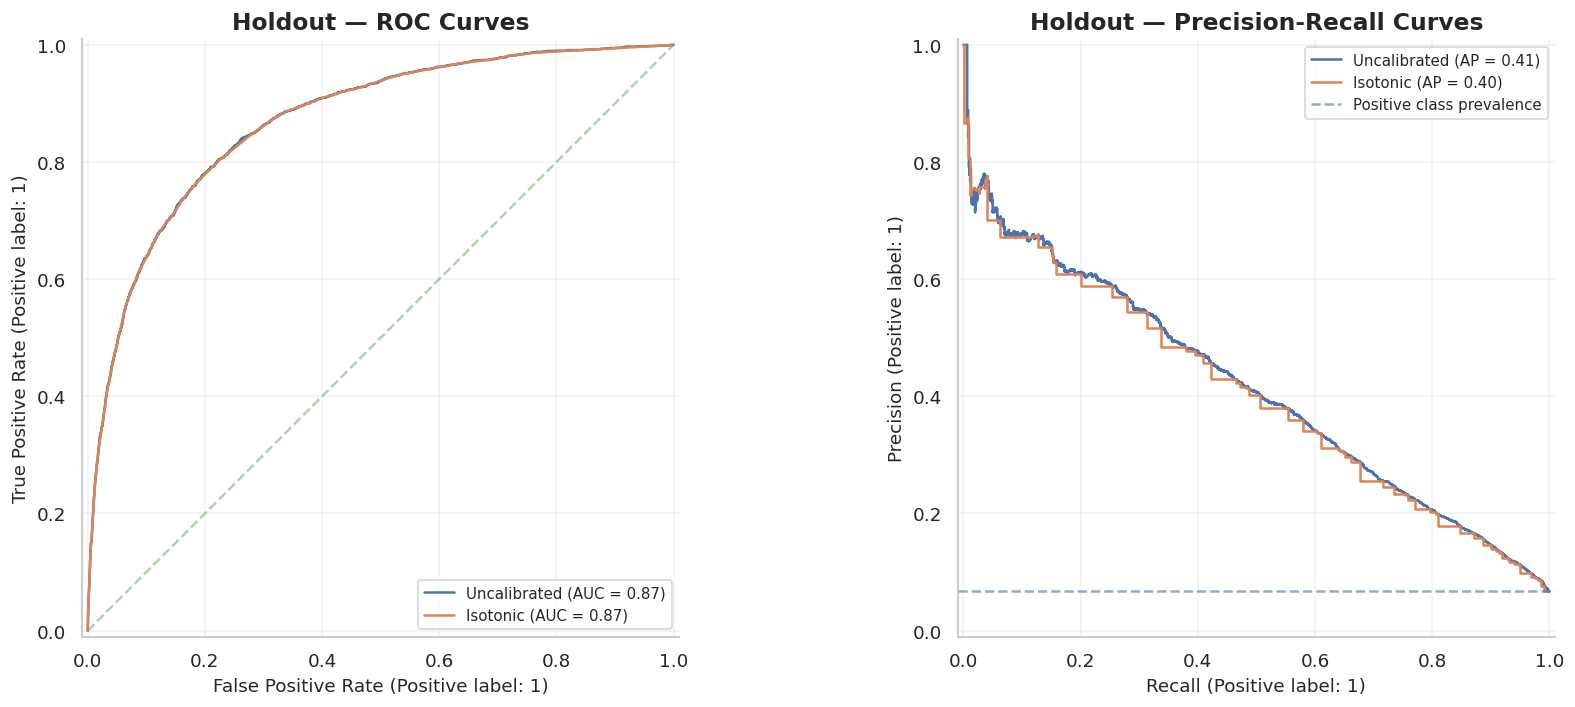

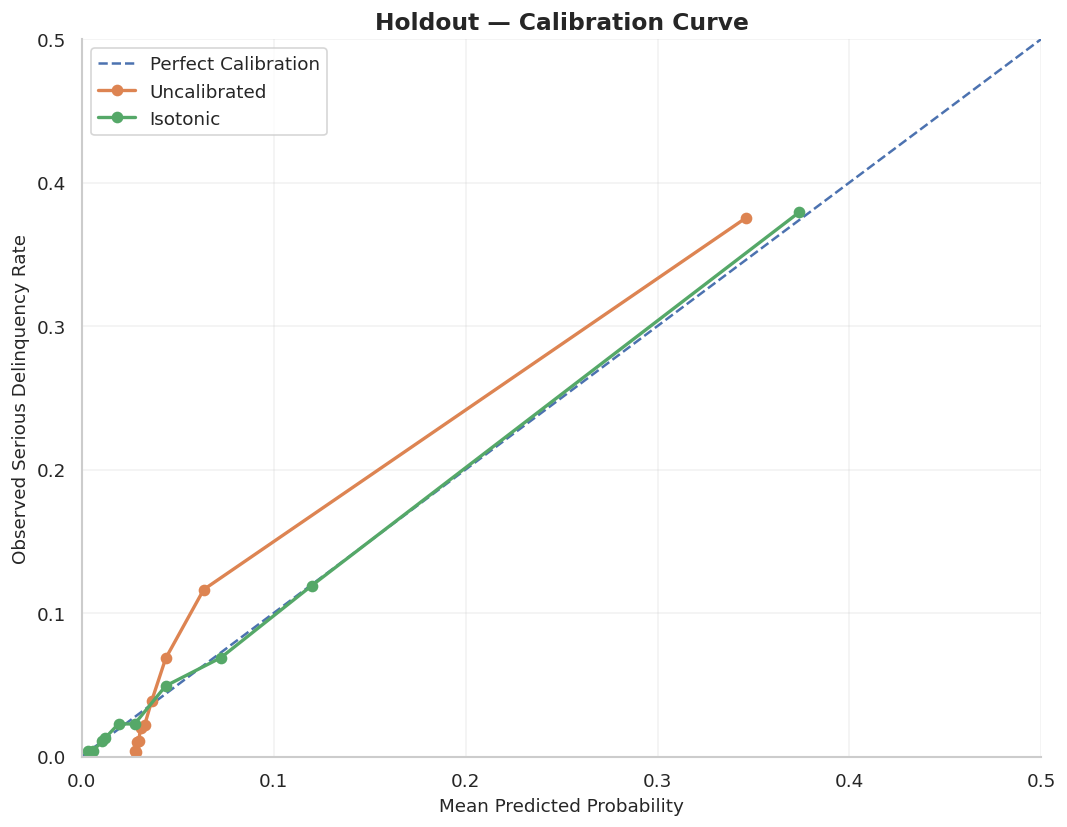

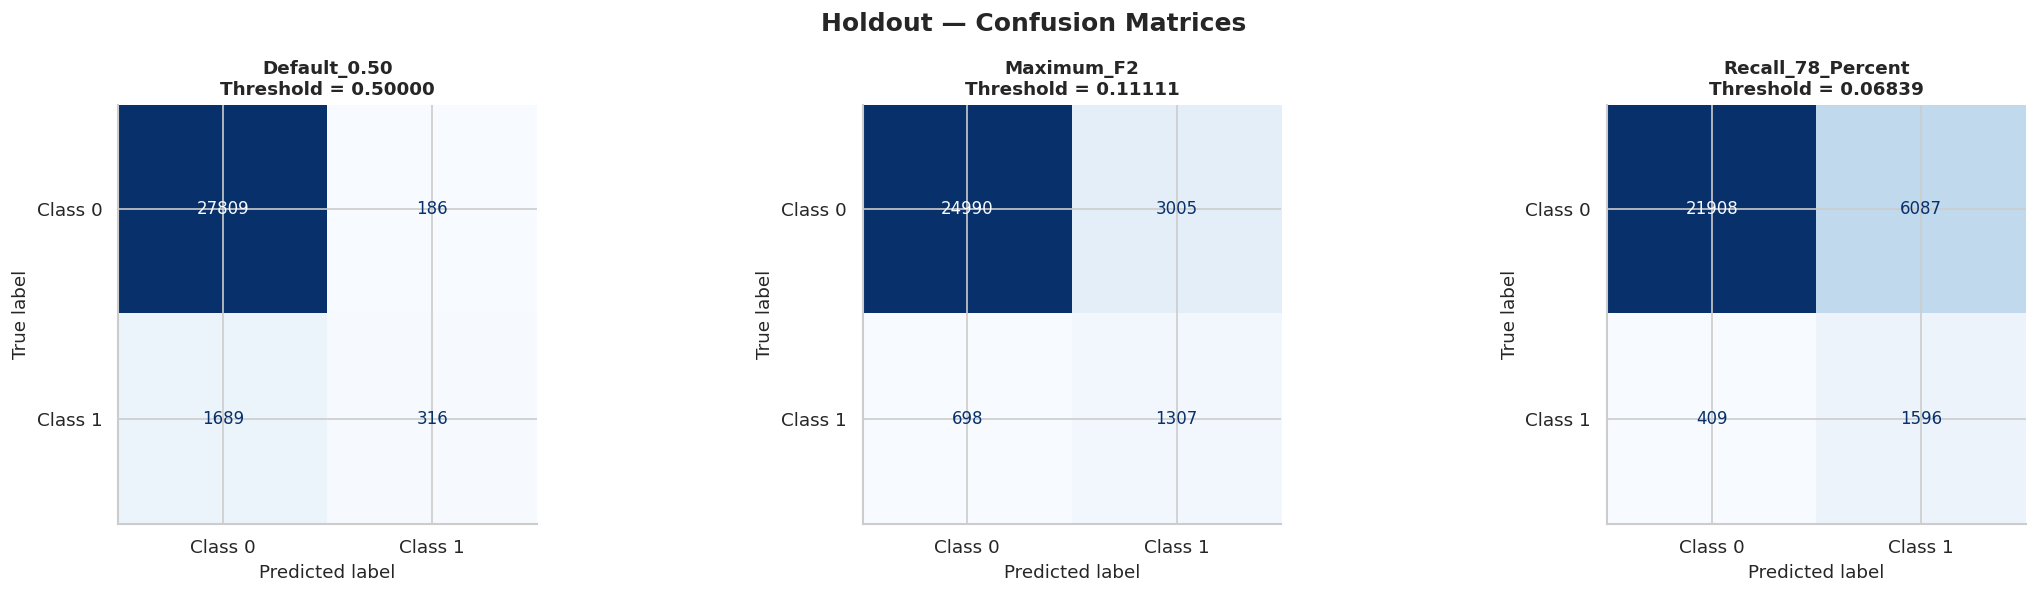


HOLDOUT — CLASSIFICATION REPORT (MAXIMUM F2)
              precision    recall  f1-score   support

           0    0.97283   0.89266   0.93102     27995
           1    0.30311   0.65187   0.41380      2005

    accuracy                        0.87657     30000
   macro avg    0.63797   0.77226   0.67241     30000
weighted avg    0.92807   0.87657   0.89645     30000


FINAL HOLDOUT SUMMARY


,Model,ROC_AUC,Average_Precision,Brier_Score,Log_Loss,ECE,Mean_Predicted_Risk
0,Stacking_Uncalibrated,0.870111,0.413180,0.049839,0.186132,0.021756,0.066770
1,Stacking_Isotonic,0.869738,0.403677,0.048446,0.176267,0.002645,0.066371


,Strategy,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,F2,TP,FP,FN,TN
0,Default_0.50,0.500000,0.937500,0.575481,0.629482,0.157606,0.252094,0.185402,316,186,1689,27809
1,Maximum_F2,0.111111,0.876567,0.772265,0.303108,0.651870,0.413804,0.529922,1307,3005,698,24990
2,Recall_78_Percent,0.068387,0.783467,0.789289,0.207731,0.796010,0.329480,0.508183,1596,6087,409,21908



Stored holdout predictions: (30000, 16)

Independent holdout evaluation completed.
No model parameters or thresholds were changed.
Kaggle test dataset has NOT been used.


In [34]:
from IPython.display import display

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report
)

from sklearn.calibration import calibration_curve


# ------------------------------------------------------------
# 1. Prepare holdout dataset
# ------------------------------------------------------------

X_holdout_final = X_holdout.loc[
    :, FINAL_RAW_FEATURES
].copy()

y_holdout_final = np.asarray(
    y_holdout
).astype(int).ravel()

assert len(X_holdout_final) == len(y_holdout_final)

assert list(X_holdout_final.columns) == FINAL_RAW_FEATURES

assert set(np.unique(y_holdout_final)) == {0, 1}

print("=" * 65)
print("FINAL HOLDOUT EVALUATION")
print("=" * 65)

print("Model:", FINAL_MODEL_NAME)
print("Calibration:", FINAL_CALIBRATION_METHOD)
print("Holdout samples:", len(X_holdout_final))

print(
    "Positive class rate:",
    round(y_holdout_final.mean(), 6)
)


# ------------------------------------------------------------
# 2. Generate holdout predictions
# ------------------------------------------------------------

holdout_raw_probabilities = (
    final_development_model_fitted
    .predict_proba(X_holdout_final)[:, 1]
)

holdout_calibrated_probabilities = (
    final_isotonic_calibrator.predict(
        holdout_raw_probabilities
    )
)

holdout_raw_probabilities = np.asarray(
    holdout_raw_probabilities,
    dtype=float
)

holdout_calibrated_probabilities = np.clip(
    np.asarray(
        holdout_calibrated_probabilities,
        dtype=float
    ),
    0.0,
    1.0
)

assert np.isfinite(holdout_raw_probabilities).all()
assert np.isfinite(holdout_calibrated_probabilities).all()

print("\nHoldout predictions generated successfully.")


# ------------------------------------------------------------
# 3. Probability performance metrics
# ------------------------------------------------------------

def evaluate_probability_scores(
    name,
    probabilities
):
    return {
        "Model": name,

        "ROC_AUC": roc_auc_score(
            y_holdout_final,
            probabilities
        ),

        "Average_Precision": average_precision_score(
            y_holdout_final,
            probabilities
        ),

        "Brier_Score": brier_score_loss(
            y_holdout_final,
            probabilities
        ),

        "Log_Loss": log_loss(
            y_holdout_final,
            probabilities,
            labels=[0, 1]
        ),

        "ECE": expected_calibration_error(
            y_holdout_final,
            probabilities,
            n_bins=10
        ),

        "Mean_Predicted_Risk": float(
            np.mean(probabilities)
        )
    }


holdout_probability_comparison = pd.DataFrame([
    evaluate_probability_scores(
        "Stacking_Uncalibrated",
        holdout_raw_probabilities
    ),

    evaluate_probability_scores(
        "Stacking_Isotonic",
        holdout_calibrated_probabilities
    )
])

print("\n" + "=" * 65)
print("HOLDOUT — PROBABILITY PERFORMANCE")
print("=" * 65)

display(
    holdout_probability_comparison.round(6)
)


# ------------------------------------------------------------
# 4. Evaluate fixed classification thresholds
# ------------------------------------------------------------

# All thresholds were selected BEFORE seeing holdout.

holdout_thresholds = {
    "Default_0.50": 0.50,
    "Maximum_F2": CALIBRATED_THRESHOLD_F2,
    "Recall_78_Percent": CALIBRATED_THRESHOLD_RECALL78
}


def evaluate_holdout_threshold(
    name,
    threshold
):
    predictions = (
        holdout_calibrated_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_holdout_final,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Strategy": name,
        "Threshold": float(threshold),

        "Accuracy": accuracy_score(
            y_holdout_final,
            predictions
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_holdout_final,
            predictions
        ),

        "Precision": precision_score(
            y_holdout_final,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_holdout_final,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_holdout_final,
            predictions,
            zero_division=0
        ),

        "F2": fbeta_score(
            y_holdout_final,
            predictions,
            beta=2,
            zero_division=0
        ),

        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


holdout_threshold_comparison = pd.DataFrame([
    evaluate_holdout_threshold(name, threshold)
    for name, threshold in holdout_thresholds.items()
])

print("\n" + "=" * 65)
print("HOLDOUT — THRESHOLD COMPARISON")
print("=" * 65)

display(
    holdout_threshold_comparison.round(6)
)


# ------------------------------------------------------------
# 5. ROC Curve & Precision-Recall Curve
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

prediction_sets = {
    "Uncalibrated": holdout_raw_probabilities,
    "Isotonic": holdout_calibrated_probabilities
}

for model_name, probabilities in prediction_sets.items():

    RocCurveDisplay.from_predictions(
        y_holdout_final,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_holdout_final,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    alpha=0.5
)

axes[0].set_title(
    "Holdout — ROC Curves",
    fontweight="bold"
)

axes[1].axhline(
    y_holdout_final.mean(),
    linestyle="--",
    alpha=0.6,
    label="Positive class prevalence"
)

axes[1].set_title(
    "Holdout — Precision-Recall Curves",
    fontweight="bold"
)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Holdout Calibration Curve
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

for model_name, probabilities in prediction_sets.items():

    observed_rate, predicted_rate = calibration_curve(
        y_holdout_final,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        predicted_rate,
        observed_rate,
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Serious Delinquency Rate")

ax.set_title(
    "Holdout — Calibration Curve",
    fontweight="bold"
)

ax.set_xlim(0, 0.50)
ax.set_ylim(0, 0.50)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Confusion matrices
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5)
)

for ax, (name, threshold) in zip(
    axes,
    holdout_thresholds.items()
):

    predictions = (
        holdout_calibrated_probabilities >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_holdout_final,
        predictions,
        labels=[0, 1],
        display_labels=["Class 0", "Class 1"],
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        f"{name}\nThreshold = {threshold:.5f}",
        fontsize=11,
        fontweight="bold"
    )

plt.suptitle(
    "Holdout — Confusion Matrices",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Classification report
# ------------------------------------------------------------

# Use the previously selected Maximum F2 threshold.
# No threshold optimization on holdout.

holdout_operating_threshold = (
    CALIBRATED_THRESHOLD_F2
)

holdout_predictions_f2 = (
    holdout_calibrated_probabilities
    >= holdout_operating_threshold
).astype(int)

print("\n" + "=" * 65)
print("HOLDOUT — CLASSIFICATION REPORT (MAXIMUM F2)")
print("=" * 65)

print(
    classification_report(
        y_holdout_final,
        holdout_predictions_f2,
        digits=5,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 9. Preserve predictions for subsequent analyses
# ------------------------------------------------------------

holdout_predictions_df = X_holdout_final.copy()

holdout_predictions_df["True_Label"] = (
    y_holdout_final
)

holdout_predictions_df["Raw_Probability"] = (
    holdout_raw_probabilities
)

holdout_predictions_df["Calibrated_Probability"] = (
    holdout_calibrated_probabilities
)

holdout_predictions_df["Predicted_Default"] = (
    holdout_calibrated_probabilities >= 0.50
).astype(int)

holdout_predictions_df["Predicted_F2"] = (
    holdout_predictions_f2
)

holdout_predictions_df["Predicted_Recall78"] = (
    holdout_calibrated_probabilities
    >= CALIBRATED_THRESHOLD_RECALL78
).astype(int)


# ------------------------------------------------------------
# 10. Final evaluation summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL HOLDOUT SUMMARY")
print("=" * 65)

display(
    holdout_probability_comparison.round(6)
)

display(
    holdout_threshold_comparison.round(6)
)

print(
    "\nStored holdout predictions:",
    holdout_predictions_df.shape
)

print("\nIndependent holdout evaluation completed.")
print("No model parameters or thresholds were changed.")
print("Kaggle test dataset has NOT been used.")

# Bootstrap Confidence Intervals (Test)

BOOTSTRAP CONFIDENCE INTERVALS — HOLDOUT
Holdout samples: 30000
Bootstrap iterations: 1000
Confidence level: 0.95
Final model: Stacking_Tuned
Bootstrap progress: 250/1000
Bootstrap progress: 500/1000
Bootstrap progress: 750/1000
Bootstrap progress: 1000/1000

Bootstrap completed.
Valid replicates: 1000
Elapsed seconds: 64.69

BOOTSTRAP — 95% CONFIDENCE INTERVALS


,Metric,Point_Estimate,CI_Lower_95,CI_Upper_95,Bootstrap_Std
0,ROC_AUC_Raw,0.870111,0.861350,0.878075,0.004155
1,ROC_AUC_Isotonic,0.869738,0.860995,0.877593,0.004165
2,AP_Raw,0.413180,0.389609,0.435762,0.011688
3,AP_Isotonic,0.403677,0.381528,0.425708,0.011383
4,Brier_Raw,0.049839,0.047831,0.051993,0.001049
5,Brier_Isotonic,0.048446,0.046672,0.050419,0.000947
6,LogLoss_Raw,0.186132,0.179877,0.192819,0.003290
7,LogLoss_Isotonic,0.176267,0.170093,0.183056,0.003337
8,Precision_F2,0.303108,0.289768,0.316271,0.006949
9,Recall_F2,0.651870,0.630155,0.671071,0.010359



RANKING METRICS — 95% CI


,Metric,Point_Estimate,CI_Lower_95,CI_Upper_95,Bootstrap_Std
0,ROC_AUC_Raw,0.870111,0.861350,0.878075,0.004155
1,ROC_AUC_Isotonic,0.869738,0.860995,0.877593,0.004165
2,AP_Raw,0.413180,0.389609,0.435762,0.011688
3,AP_Isotonic,0.403677,0.381528,0.425708,0.011383



THRESHOLD METRICS — 95% CI


,Metric,Point_Estimate,CI_Lower_95,CI_Upper_95,Bootstrap_Std
8,Precision_F2,0.303108,0.289768,0.316271,0.006949
9,Recall_F2,0.651870,0.630155,0.671071,0.010359
10,F2_at_F2,0.529922,0.512391,0.545900,0.008531
11,Precision_78,0.207731,0.199247,0.216732,0.004567
12,Recall_78,0.796010,0.778654,0.813254,0.009087
13,F2_at_78,0.508183,0.493733,0.522124,0.007178



PAIRED CALIBRATION DIFFERENCES — 95% CI


,Metric,Point_Estimate,CI_Lower_95,CI_Upper_95,Bootstrap_Std
14,AUC_Raw_minus_Isotonic,0.000373,0.000053,0.000698,0.000167
15,AP_Raw_minus_Isotonic,0.009503,0.007590,0.011226,0.000905
16,Brier_Improvement,0.001392,0.001044,0.001757,0.000184
17,LogLoss_Improvement,0.009865,0.006948,0.012139,0.001388


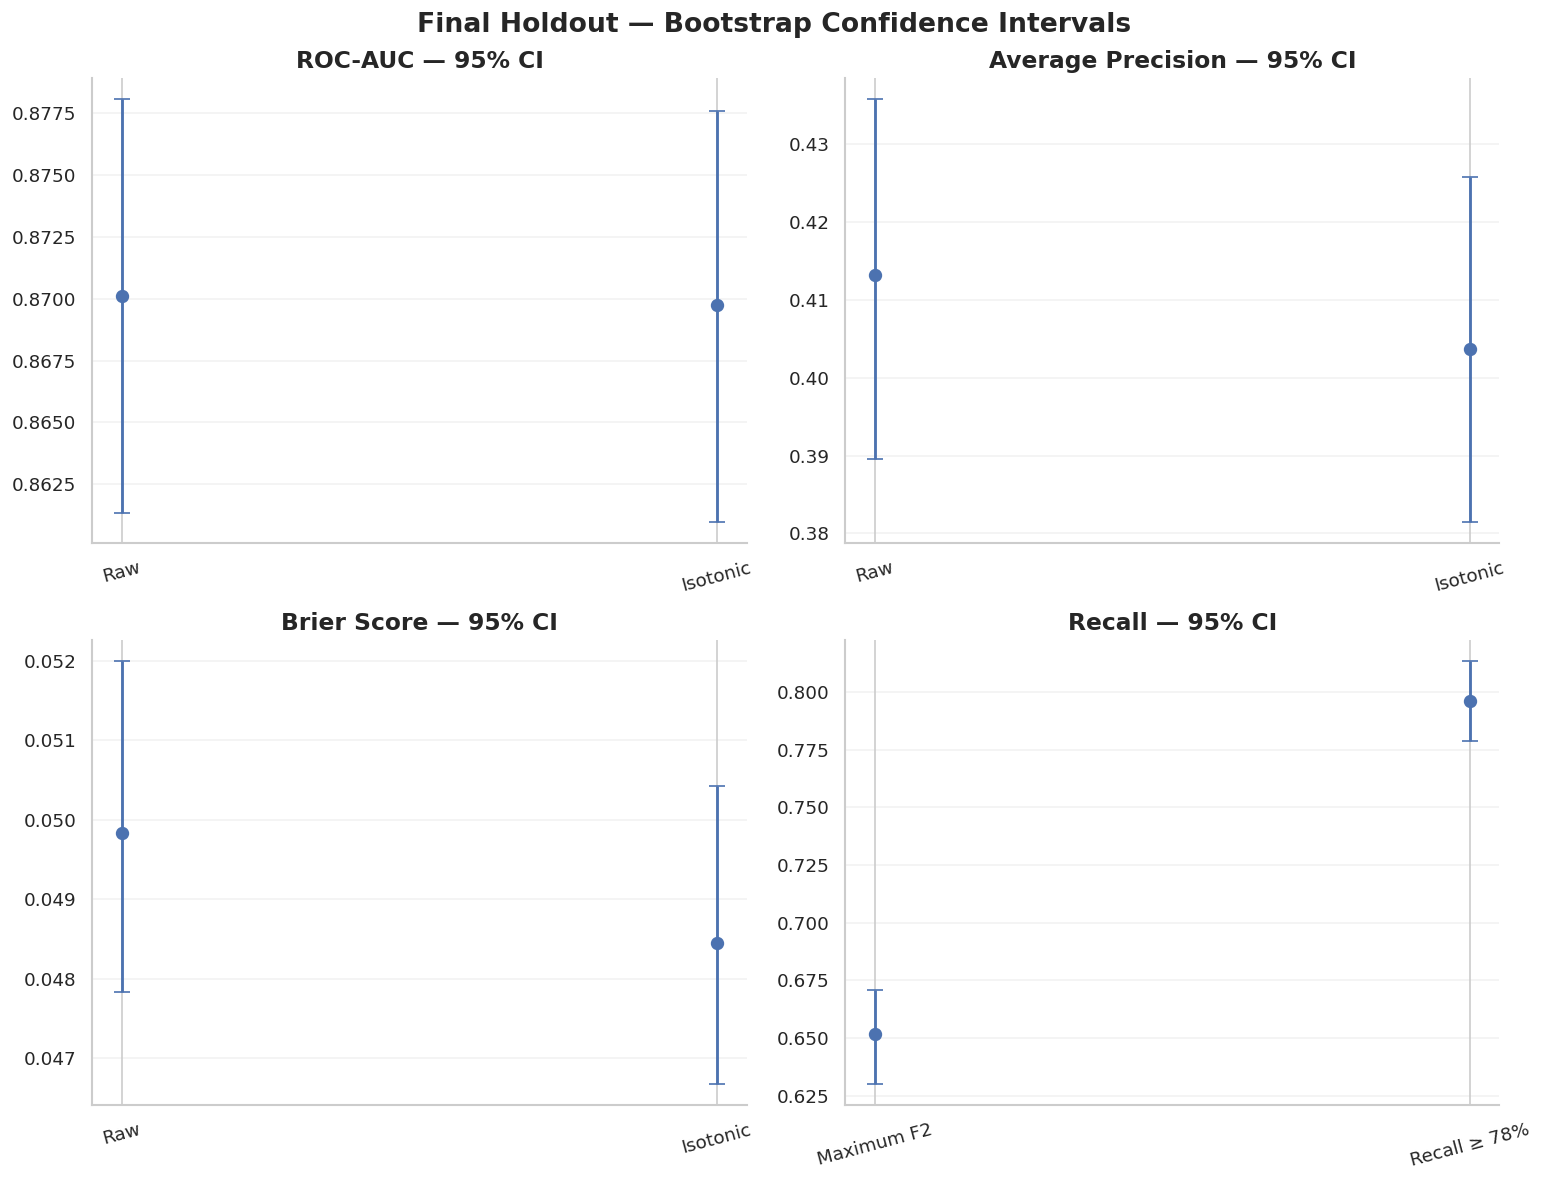


BOOTSTRAP ANALYSIS SUMMARY
ROC_AUC_Raw: 0.87011 [0.86135, 0.87807]
ROC_AUC_Isotonic: 0.86974 [0.86099, 0.87759]
AP_Raw: 0.41318 [0.38961, 0.43576]
Brier_Isotonic: 0.04845 [0.04667, 0.05042]
Recall_F2: 0.65187 [0.63015, 0.67107]
Recall_78: 0.79601 [0.77865, 0.81325]

All thresholds remained fixed.
No model retraining or hyperparameter tuning.
No Kaggle test data used.


In [35]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

BOOTSTRAP_ITERATIONS = 1000
CONFIDENCE_LEVEL = 0.95
BOOTSTRAP_RANDOM_STATE = RANDOM_STATE + 1000

rng = np.random.default_rng(
    BOOTSTRAP_RANDOM_STATE
)

y_test = np.asarray(
    y_holdout_final,
    dtype=int
).ravel()

p_raw = np.asarray(
    holdout_raw_probabilities,
    dtype=float
).ravel()

p_cal = np.asarray(
    holdout_calibrated_probabilities,
    dtype=float
).ravel()

n_test = len(y_test)

assert len(p_raw) == n_test
assert len(p_cal) == n_test
assert set(np.unique(y_test)) == {0, 1}

print("=" * 65)
print("BOOTSTRAP CONFIDENCE INTERVALS — HOLDOUT")
print("=" * 65)

print("Holdout samples:", n_test)
print("Bootstrap iterations:", BOOTSTRAP_ITERATIONS)
print("Confidence level:", CONFIDENCE_LEVEL)
print("Final model:", FINAL_MODEL_NAME)


# ------------------------------------------------------------
# 2. Fixed-threshold metric helper
# ------------------------------------------------------------

def calculate_operating_metrics(
    y_true,
    probabilities,
    threshold
):

    y_pred = probabilities >= threshold

    positive = y_true == 1
    negative = ~positive

    tp = np.sum(y_pred & positive)
    fp = np.sum(y_pred & negative)
    fn = np.sum(~y_pred & positive)

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    f2_denominator = 5 * tp + 4 * fn + fp

    f2 = (
        5 * tp / f2_denominator
        if f2_denominator > 0
        else 0.0
    )

    return {
        "Precision": float(precision),
        "Recall": float(recall),
        "F2": float(f2)
    }


# ------------------------------------------------------------
# 3. Bootstrap statistics helper
# ------------------------------------------------------------

def calculate_bootstrap_statistics(indices):

    labels = y_test[indices]
    raw = p_raw[indices]
    calibrated = p_cal[indices]

    raw_auc = roc_auc_score(labels, raw)

    calibrated_auc = roc_auc_score(
        labels,
        calibrated
    )

    raw_ap = average_precision_score(
        labels,
        raw
    )

    calibrated_ap = average_precision_score(
        labels,
        calibrated
    )

    raw_brier = np.mean(
        (labels - raw) ** 2
    )

    calibrated_brier = np.mean(
        (labels - calibrated) ** 2
    )

    raw_logloss = log_loss(
        labels,
        raw,
        labels=[0, 1]
    )

    calibrated_logloss = log_loss(
        labels,
        calibrated,
        labels=[0, 1]
    )

    f2_metrics = calculate_operating_metrics(
        labels,
        calibrated,
        CALIBRATED_THRESHOLD_F2
    )

    recall78_metrics = calculate_operating_metrics(
        labels,
        calibrated,
        CALIBRATED_THRESHOLD_RECALL78
    )

    return {
        "ROC_AUC_Raw": raw_auc,
        "ROC_AUC_Isotonic": calibrated_auc,

        "AP_Raw": raw_ap,
        "AP_Isotonic": calibrated_ap,

        "Brier_Raw": raw_brier,
        "Brier_Isotonic": calibrated_brier,

        "LogLoss_Raw": raw_logloss,
        "LogLoss_Isotonic": calibrated_logloss,

        "Precision_F2": f2_metrics["Precision"],
        "Recall_F2": f2_metrics["Recall"],
        "F2_at_F2": f2_metrics["F2"],

        "Precision_78": recall78_metrics["Precision"],
        "Recall_78": recall78_metrics["Recall"],
        "F2_at_78": recall78_metrics["F2"],

        # Positive = raw ranking performs better
        "AUC_Raw_minus_Isotonic": (
            raw_auc - calibrated_auc
        ),

        "AP_Raw_minus_Isotonic": (
            raw_ap - calibrated_ap
        ),

        # Positive = isotonic improves Brier
        "Brier_Improvement": (
            raw_brier - calibrated_brier
        ),

        # Positive = isotonic improves Log Loss
        "LogLoss_Improvement": (
            raw_logloss - calibrated_logloss
        )
    }


# ------------------------------------------------------------
# 4. Original holdout point estimates
# ------------------------------------------------------------

point_estimates = calculate_bootstrap_statistics(
    np.arange(n_test)
)


# ------------------------------------------------------------
# 5. Run paired bootstrap
# ------------------------------------------------------------

bootstrap_rows = []

start_time = time.perf_counter()

for iteration in range(BOOTSTRAP_ITERATIONS):

    # Sample holdout rows with replacement
    sample_indices = rng.integers(
        low=0,
        high=n_test,
        size=n_test
    )

    sampled_labels = y_test[sample_indices]

    # ROC-AUC requires both classes
    if sampled_labels.min() == sampled_labels.max():
        continue

    metrics = calculate_bootstrap_statistics(
        sample_indices
    )

    bootstrap_rows.append(metrics)

    if (iteration + 1) % 250 == 0:
        print(
            f"Bootstrap progress: "
            f"{iteration + 1}/{BOOTSTRAP_ITERATIONS}",
            flush=True
        )

bootstrap_elapsed = (
    time.perf_counter() - start_time
)

bootstrap_results_df = pd.DataFrame(
    bootstrap_rows
)

print("\nBootstrap completed.")
print("Valid replicates:", len(bootstrap_results_df))
print("Elapsed seconds:", round(bootstrap_elapsed, 2))


# ------------------------------------------------------------
# 6. Calculate 95% percentile confidence intervals
# ------------------------------------------------------------

alpha = 1.0 - CONFIDENCE_LEVEL

ci_rows = []

for metric_name, point_value in point_estimates.items():

    values = bootstrap_results_df[
        metric_name
    ].dropna().to_numpy()

    lower = np.quantile(
        values,
        alpha / 2
    )

    upper = np.quantile(
        values,
        1 - alpha / 2
    )

    ci_rows.append({
        "Metric": metric_name,
        "Point_Estimate": point_value,
        "CI_Lower_95": lower,
        "CI_Upper_95": upper,
        "Bootstrap_Std": np.std(
            values, ddof=1
        )
    })

bootstrap_ci_table = pd.DataFrame(ci_rows)

print("\n" + "=" * 65)
print("BOOTSTRAP — 95% CONFIDENCE INTERVALS")
print("=" * 65)

display(
    bootstrap_ci_table.round(6)
)


# ------------------------------------------------------------
# 7. Focused comparison: Ranking performance
# ------------------------------------------------------------

ranking_metrics = [
    "ROC_AUC_Raw",
    "ROC_AUC_Isotonic",
    "AP_Raw",
    "AP_Isotonic"
]

print("\nRANKING METRICS — 95% CI")

display(
    bootstrap_ci_table[
        bootstrap_ci_table["Metric"].isin(
            ranking_metrics
        )
    ].round(6)
)


# ------------------------------------------------------------
# 8. Focused comparison: Threshold metrics
# ------------------------------------------------------------

threshold_metrics = [
    "Precision_F2",
    "Recall_F2",
    "F2_at_F2",
    "Precision_78",
    "Recall_78",
    "F2_at_78"
]

print("\nTHRESHOLD METRICS — 95% CI")

display(
    bootstrap_ci_table[
        bootstrap_ci_table["Metric"].isin(
            threshold_metrics
        )
    ].round(6)
)


# ------------------------------------------------------------
# 9. Paired calibration differences
# ------------------------------------------------------------

difference_metrics = [
    "AUC_Raw_minus_Isotonic",
    "AP_Raw_minus_Isotonic",
    "Brier_Improvement",
    "LogLoss_Improvement"
]

print("\nPAIRED CALIBRATION DIFFERENCES — 95% CI")

display(
    bootstrap_ci_table[
        bootstrap_ci_table["Metric"].isin(
            difference_metrics
        )
    ].round(6)
)


# ------------------------------------------------------------
# 10. Visualization helper
# ------------------------------------------------------------

def plot_bootstrap_ci(
    ax,
    metrics,
    labels,
    title
):

    selected = (
        bootstrap_ci_table
        .set_index("Metric")
        .loc[metrics]
    )

    estimates = selected[
        "Point_Estimate"
    ].to_numpy()

    lower = selected[
        "CI_Lower_95"
    ].to_numpy()

    upper = selected[
        "CI_Upper_95"
    ].to_numpy()

    errors = np.vstack([
        estimates - lower,
        upper - estimates
    ])

    positions = np.arange(len(metrics))

    ax.errorbar(
        positions,
        estimates,
        yerr=errors,
        fmt="o",
        markersize=7,
        capsize=5,
        linewidth=1.7
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=15)

    ax.set_title(
        title,
        fontweight="bold"
    )

    ax.grid(axis="y", alpha=0.25)


# ------------------------------------------------------------
# 11. Confidence interval visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

plot_bootstrap_ci(
    axes[0, 0],
    ["ROC_AUC_Raw", "ROC_AUC_Isotonic"],
    ["Raw", "Isotonic"],
    "ROC-AUC — 95% CI"
)

plot_bootstrap_ci(
    axes[0, 1],
    ["AP_Raw", "AP_Isotonic"],
    ["Raw", "Isotonic"],
    "Average Precision — 95% CI"
)

plot_bootstrap_ci(
    axes[1, 0],
    ["Brier_Raw", "Brier_Isotonic"],
    ["Raw", "Isotonic"],
    "Brier Score — 95% CI"
)

plot_bootstrap_ci(
    axes[1, 1],
    ["Recall_F2", "Recall_78"],
    ["Maximum F2", "Recall ≥ 78%"],
    "Recall — 95% CI"
)

fig.suptitle(
    "Final Holdout — Bootstrap Confidence Intervals",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BOOTSTRAP ANALYSIS SUMMARY")
print("=" * 65)

for metric in [
    "ROC_AUC_Raw",
    "ROC_AUC_Isotonic",
    "AP_Raw",
    "Brier_Isotonic",
    "Recall_F2",
    "Recall_78"
]:

    row = bootstrap_ci_table.loc[
        bootstrap_ci_table["Metric"] == metric
    ].iloc[0]

    print(
        f"{metric}: "
        f"{row['Point_Estimate']:.5f} "
        f"[{row['CI_Lower_95']:.5f}, "
        f"{row['CI_Upper_95']:.5f}]"
    )

print("\nAll thresholds remained fixed.")
print("No model retraining or hyperparameter tuning.")
print("No Kaggle test data used.")


# Lift & Cumulative Gains Analysis

LIFT & CUMULATIVE GAINS ANALYSIS
Total customers: 30000
Serious delinquency cases: 2005
Overall delinquency rate: 6.6833%

TOP-K CUSTOMER TARGETING PERFORMANCE


,Top_Customers_Percent,Customers_Selected,Detected_Delinquencies,Event_Rate,Cumulative_Gain,Lift,Random_Expected_Cases
0,1,300,204,0.68000,0.10175,10.17456,20.05
1,5,1500,737,0.49133,0.36758,7.35162,100.25
2,10,3000,1126,0.37533,0.56160,5.61596,200.50
3,20,6000,1475,0.24583,0.73566,3.67830,401.00
4,30,9000,1680,0.18667,0.83791,2.79302,601.50
5,50,15000,1861,0.12407,0.92818,1.85636,1002.50



RISK DECILE ANALYSIS


,Risk_Decile,Customers,Delinquencies,Mean_Raw_Score,Mean_Calibrated_Risk,Event_Rate,Decile_Lift,Cumulative_Customers,Cumulative_Delinquencies,Cumulative_Gain,Cumulative_Lift
0,1,3000,1126,0.34606,0.36897,0.37533,5.61596,3000,1126,0.56160,5.61596
1,2,3000,349,0.06349,0.11822,0.11633,1.74065,6000,1475,0.73566,3.67830
2,3,3000,205,0.04366,0.06565,0.06833,1.02244,9000,1680,0.83791,2.79302
3,4,3000,116,0.03636,0.03988,0.03867,0.57855,12000,1796,0.89576,2.23940
4,5,3000,65,0.03265,0.02597,0.02167,0.32419,15000,1861,0.92818,1.85636
5,6,3000,59,0.03064,0.01659,0.01967,0.29426,18000,1920,0.95761,1.59601
6,7,3000,33,0.02958,0.01190,0.01100,0.16459,21000,1953,0.97406,1.39152
7,8,3000,31,0.02893,0.00876,0.01033,0.15461,24000,1984,0.98953,1.23691
8,9,3000,10,0.02841,0.00475,0.00333,0.04988,27000,1994,0.99451,1.10502
9,10,3000,11,0.02792,0.00302,0.00367,0.05486,30000,2005,1.00000,1.00000


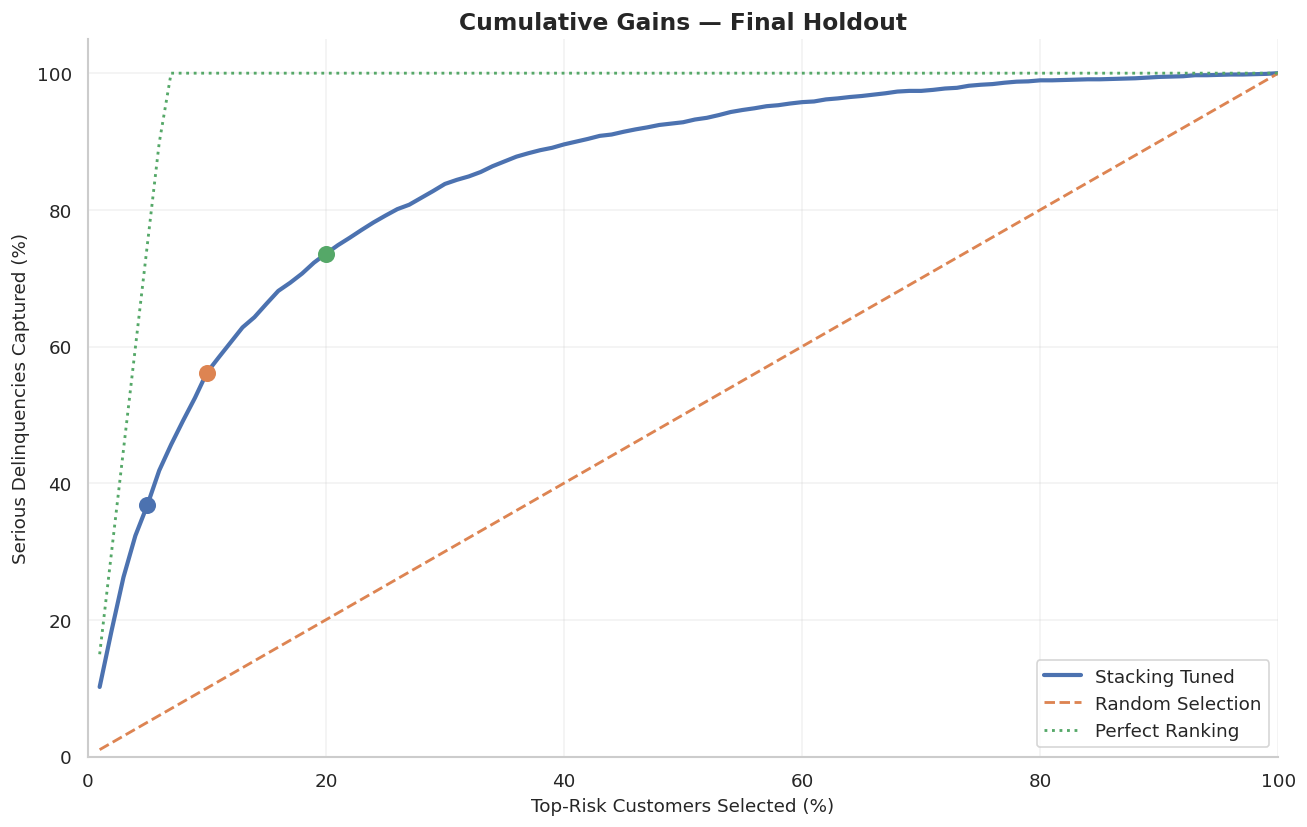

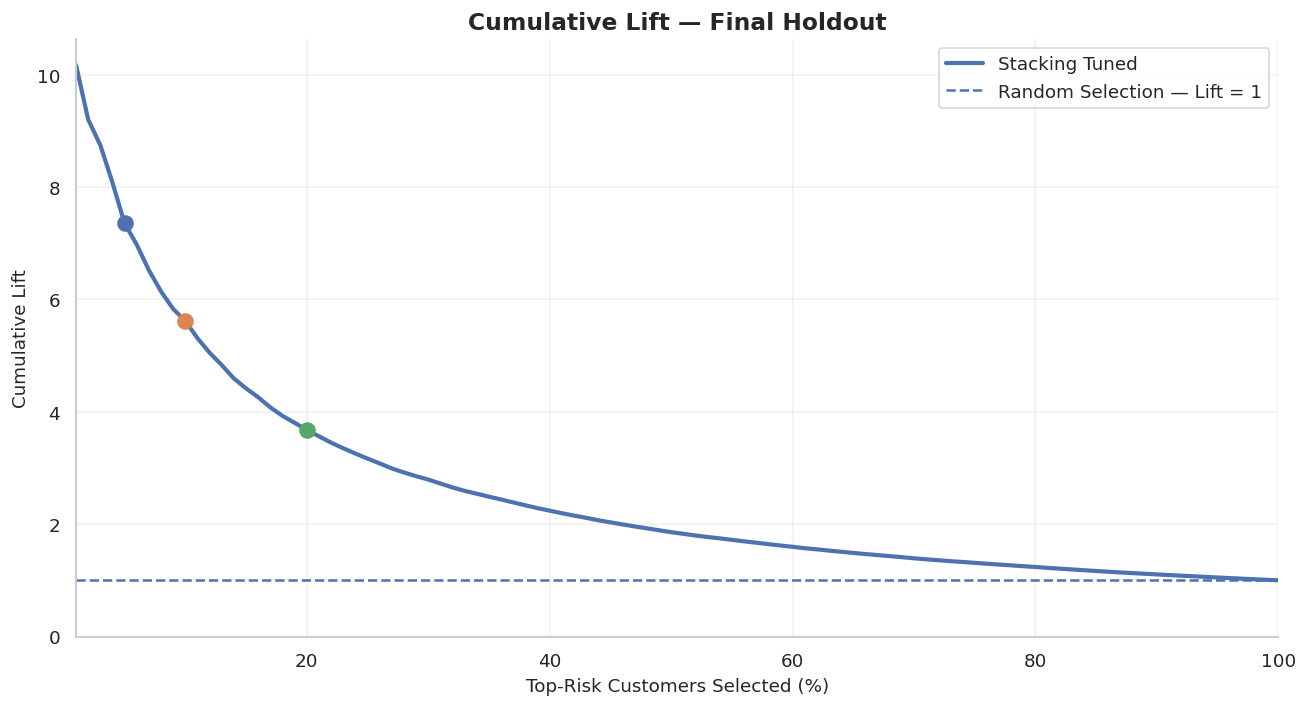

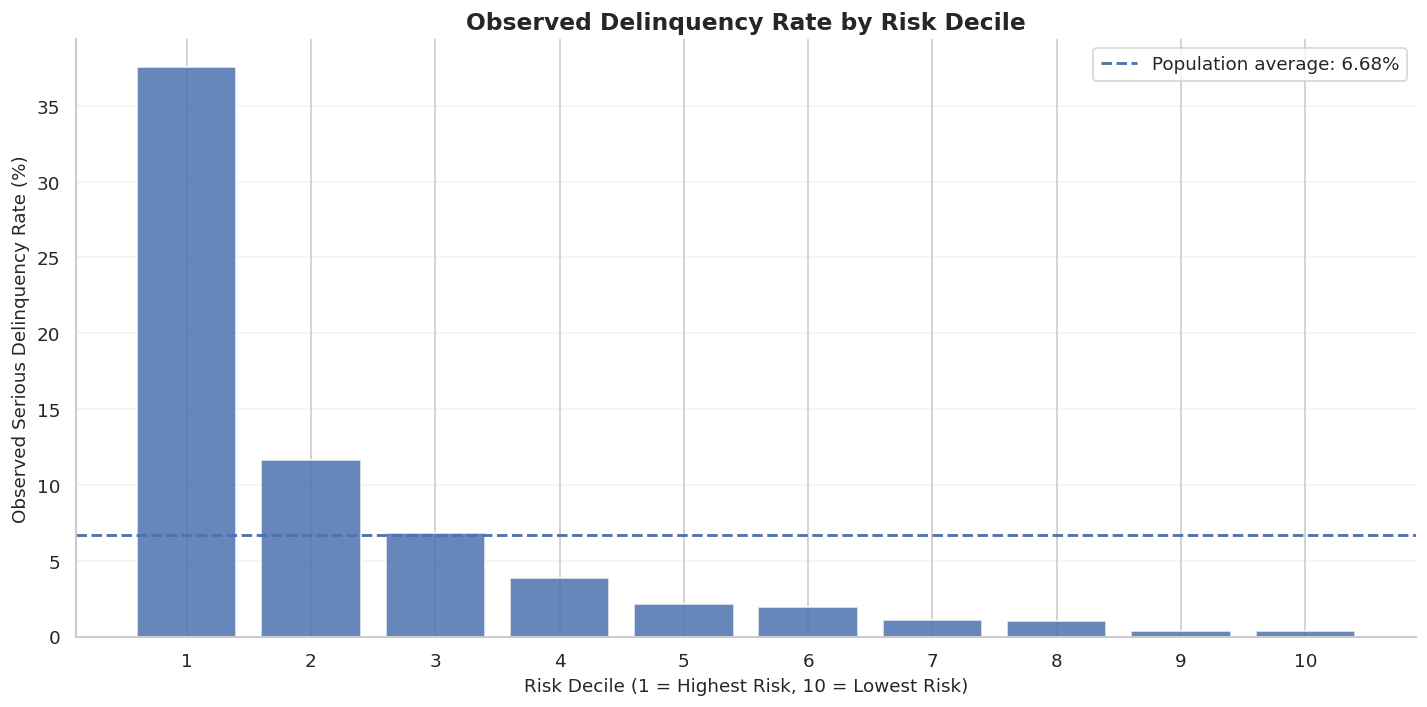


TARGETING SUMMARY

Top 5% customers:
  Selected customers: 1,500
  Delinquencies detected: 737
  Cumulative gain: 36.76%
  Lift: 7.352x

Top 10% customers:
  Selected customers: 3,000
  Delinquencies detected: 1,126
  Cumulative gain: 56.16%
  Lift: 5.616x

Top 20% customers:
  Selected customers: 6,000
  Delinquencies detected: 1,475
  Cumulative gain: 73.57%
  Lift: 3.678x

LIFT & CUMULATIVE GAINS ANALYSIS COMPLETED
No model retraining performed.
No thresholds were changed.
Holdout used for descriptive analysis only.
Kaggle test data has NOT been used.


In [36]:
# ------------------------------------------------------------
# 1. Prepare ranking dataset
# ------------------------------------------------------------

lift_data = pd.DataFrame({
    "True_Label": np.asarray(
        y_holdout_final, dtype=int
    ),
    "Risk_Score": np.asarray(
        holdout_raw_probabilities, dtype=float
    ),
    "Calibrated_Risk": np.asarray(
        holdout_calibrated_probabilities,
        dtype=float
    )
})

assert lift_data["True_Label"].isin([0, 1]).all()
assert lift_data.notna().all().all()

n_customers = len(lift_data)
total_positives = int(lift_data["True_Label"].sum())
base_rate = total_positives / n_customers

assert 0 < total_positives < n_customers

print("=" * 65)
print("LIFT & CUMULATIVE GAINS ANALYSIS")
print("=" * 65)

print("Total customers:", n_customers)
print("Serious delinquency cases:", total_positives)
print(f"Overall delinquency rate: {base_rate:.4%}")


# ------------------------------------------------------------
# 2. Rank customers by predicted risk
# ------------------------------------------------------------

holdout_ranked_df = (
    lift_data
    .sort_values(
        "Risk_Score",
        ascending=False,
        kind="mergesort"
    )
    .reset_index(drop=True)
)

holdout_ranked_df["Rank"] = (
    np.arange(1, n_customers + 1)
)

holdout_ranked_df["Population_Share"] = (
    holdout_ranked_df["Rank"] / n_customers
)

holdout_ranked_df["Cumulative_Positives"] = (
    holdout_ranked_df["True_Label"].cumsum()
)

holdout_ranked_df["Cumulative_Gain"] = (
    holdout_ranked_df["Cumulative_Positives"]
    / total_positives
)

holdout_ranked_df["Cumulative_Lift"] = (
    holdout_ranked_df["Cumulative_Gain"]
    / holdout_ranked_df["Population_Share"]
)


# ------------------------------------------------------------
# 3. Top-K targeting performance
# ------------------------------------------------------------

TOP_PERCENTAGES = [1, 5, 10, 20, 30, 50]

top_k_results = []

for percentage in TOP_PERCENTAGES:

    k = int(
        np.ceil(n_customers * percentage / 100)
    )

    top_group = holdout_ranked_df.iloc[:k]

    detected_positives = int(
        top_group["True_Label"].sum()
    )

    event_rate = detected_positives / k

    cumulative_gain = (
        detected_positives / total_positives
    )

    lift_at_k = event_rate / base_rate

    top_k_results.append({
        "Top_Customers_Percent": percentage,
        "Customers_Selected": k,
        "Detected_Delinquencies": detected_positives,
        "Event_Rate": event_rate,
        "Cumulative_Gain": cumulative_gain,
        "Lift": lift_at_k,
        "Random_Expected_Cases":
            k * base_rate
    })

lift_summary = pd.DataFrame(top_k_results)

print("\n" + "=" * 65)
print("TOP-K CUSTOMER TARGETING PERFORMANCE")
print("=" * 65)

display(lift_summary.round(5))


# ------------------------------------------------------------
# 4. Decile analysis
# ------------------------------------------------------------

# Decile 1 = highest-risk 10% of customers
# Decile 10 = lowest-risk 10%

holdout_ranked_df["Risk_Decile"] = (
    np.ceil(
        holdout_ranked_df["Rank"]
        * 10 / n_customers
    )
    .astype(int)
)

decile_analysis = (
    holdout_ranked_df
    .groupby("Risk_Decile")
    .agg(
        Customers=("True_Label", "size"),
        Delinquencies=("True_Label", "sum"),
        Mean_Raw_Score=("Risk_Score", "mean"),
        Mean_Calibrated_Risk=(
            "Calibrated_Risk", "mean"
        )
    )
    .reset_index()
)

decile_analysis["Event_Rate"] = (
    decile_analysis["Delinquencies"]
    / decile_analysis["Customers"]
)

decile_analysis["Decile_Lift"] = (
    decile_analysis["Event_Rate"]
    / base_rate
)

decile_analysis["Cumulative_Customers"] = (
    decile_analysis["Customers"].cumsum()
)

decile_analysis["Cumulative_Delinquencies"] = (
    decile_analysis["Delinquencies"].cumsum()
)

decile_analysis["Cumulative_Gain"] = (
    decile_analysis["Cumulative_Delinquencies"]
    / total_positives
)

decile_analysis["Cumulative_Lift"] = (
    decile_analysis["Cumulative_Gain"]
    / (
        decile_analysis["Cumulative_Customers"]
        / n_customers
    )
)

print("\n" + "=" * 65)
print("RISK DECILE ANALYSIS")
print("=" * 65)

display(decile_analysis.round(5))


# ------------------------------------------------------------
# 5. Compute cumulative gains and lift coordinates
# ------------------------------------------------------------

population_percentages = np.arange(1, 101)

sample_sizes = np.ceil(
    n_customers
    * population_percentages / 100
).astype(int)

cumulative_positive_counts = (
    holdout_ranked_df[
        "Cumulative_Positives"
    ].to_numpy()
)

captured_positives = (
    cumulative_positive_counts[
        sample_sizes - 1
    ]
)

cumulative_gains = (
    captured_positives / total_positives
)

population_fractions = (
    sample_sizes / n_customers
)

cumulative_lifts = (
    cumulative_gains / population_fractions
)

# Perfect ranking captures positives first.
perfect_gains = np.minimum(
    sample_sizes / total_positives,
    1.0
)

cumulative_gains_df = pd.DataFrame({
    "Population_Percent": population_percentages,
    "Cumulative_Gain": cumulative_gains,
    "Cumulative_Lift": cumulative_lifts
})


# ------------------------------------------------------------
# 6. Cumulative Gains Curve
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

ax.plot(
    population_percentages,
    cumulative_gains * 100,
    linewidth=2.5,
    label="Stacking Tuned"
)

ax.plot(
    population_percentages,
    population_fractions * 100,
    linestyle="--",
    linewidth=1.7,
    label="Random Selection"
)

ax.plot(
    population_percentages,
    perfect_gains * 100,
    linestyle=":",
    linewidth=1.7,
    label="Perfect Ranking"
)

for percentage in [5, 10, 20]:

    row = lift_summary.loc[
        lift_summary["Top_Customers_Percent"]
        == percentage
    ].iloc[0]

    ax.scatter(
        percentage,
        row["Cumulative_Gain"] * 100,
        s=85,
        zorder=5
    )

ax.set_xlabel("Top-Risk Customers Selected (%)")
ax.set_ylabel("Serious Delinquencies Captured (%)")

ax.set_title(
    "Cumulative Gains — Final Holdout",
    fontweight="bold"
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Cumulative Lift Curve
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    population_percentages,
    cumulative_lifts,
    linewidth=2.5,
    label="Stacking Tuned"
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Random Selection — Lift = 1"
)

for percentage in [5, 10, 20]:

    row = lift_summary.loc[
        lift_summary["Top_Customers_Percent"]
        == percentage
    ].iloc[0]

    ax.scatter(
        percentage,
        row["Lift"],
        s=80,
        zorder=5
    )

ax.set_xlabel("Top-Risk Customers Selected (%)")
ax.set_ylabel("Cumulative Lift")

ax.set_title(
    "Cumulative Lift — Final Holdout",
    fontweight="bold"
)

ax.set_xlim(1, 100)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Event Rate by Risk Decile
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    decile_analysis["Risk_Decile"].astype(str),
    decile_analysis["Event_Rate"] * 100,
    alpha=0.85
)

ax.axhline(
    base_rate * 100,
    linestyle="--",
    linewidth=1.7,
    label=f"Population average: {base_rate:.2%}"
)

ax.set_xlabel(
    "Risk Decile (1 = Highest Risk, 10 = Lowest Risk)"
)

ax.set_ylabel("Observed Serious Delinquency Rate (%)")

ax.set_title(
    "Observed Delinquency Rate by Risk Decile",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Business-oriented summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TARGETING SUMMARY")
print("=" * 65)

for percentage in [5, 10, 20]:

    row = lift_summary.loc[
        lift_summary["Top_Customers_Percent"]
        == percentage
    ].iloc[0]

    print(
        f"\nTop {percentage}% customers:"
    )

    print(
        f"  Selected customers: "
        f"{int(row['Customers_Selected']):,}"
    )

    print(
        f"  Delinquencies detected: "
        f"{int(row['Detected_Delinquencies']):,}"
    )

    print(
        f"  Cumulative gain: "
        f"{row['Cumulative_Gain']:.2%}"
    )

    print(
        f"  Lift: {row['Lift']:.3f}x"
    )


# ------------------------------------------------------------
# 10. Consistency checks
# ------------------------------------------------------------

assert (
    holdout_ranked_df["Cumulative_Positives"].iloc[-1]
    == total_positives
)

assert np.isclose(
    cumulative_gains[-1],
    1.0
)

assert np.isclose(
    cumulative_lifts[-1],
    1.0
)

assert (
    decile_analysis["Customers"].sum()
    == n_customers
)

print("\n" + "=" * 65)
print("LIFT & CUMULATIVE GAINS ANALYSIS COMPLETED")
print("=" * 65)

print("No model retraining performed.")
print("No thresholds were changed.")
print("Holdout used for descriptive analysis only.")
print("Kaggle test data has NOT been used.")

# Feature Importance Analysis

FINAL STACKING — FEATURE IMPORTANCE ANALYSIS
Importance samples: 10000
Raw features: 10
Positive class rate: 0.0668

Reference ROC-AUC: 0.865782
Reference Average Precision: 0.417736

Calculating permutation importance...

PERMUTATION IMPORTANCE — FULL STACKING


,Feature,ROC_AUC_Importance,ROC_AUC_Std,AP_Importance,AP_Std
0,RevolvingUtilizationOfUnsecuredLines,0.062549,0.004150,0.066711,0.005325
1,NumberOfTime30-59DaysPastDueNotWorse,0.034712,0.001238,0.041454,0.002237
2,NumberOfTimes90DaysLate,0.028775,0.002040,0.105957,0.003932
3,NumberOfTime60-89DaysPastDueNotWorse,0.017406,0.001295,0.046635,0.004170
4,age,0.008180,0.001383,0.006609,0.002098
5,NumberOfOpenCreditLinesAndLoans,0.006326,0.000713,0.007695,0.001362
6,DebtRatio,0.004208,0.000666,0.012181,0.002505
7,NumberRealEstateLoansOrLines,0.002967,0.000878,0.003808,0.002236
8,MonthlyIncome,0.002316,0.000834,0.005318,0.001276
9,NumberOfDependents,0.000532,0.000274,0.001973,0.000606



Permutation importance time: 21.06 seconds


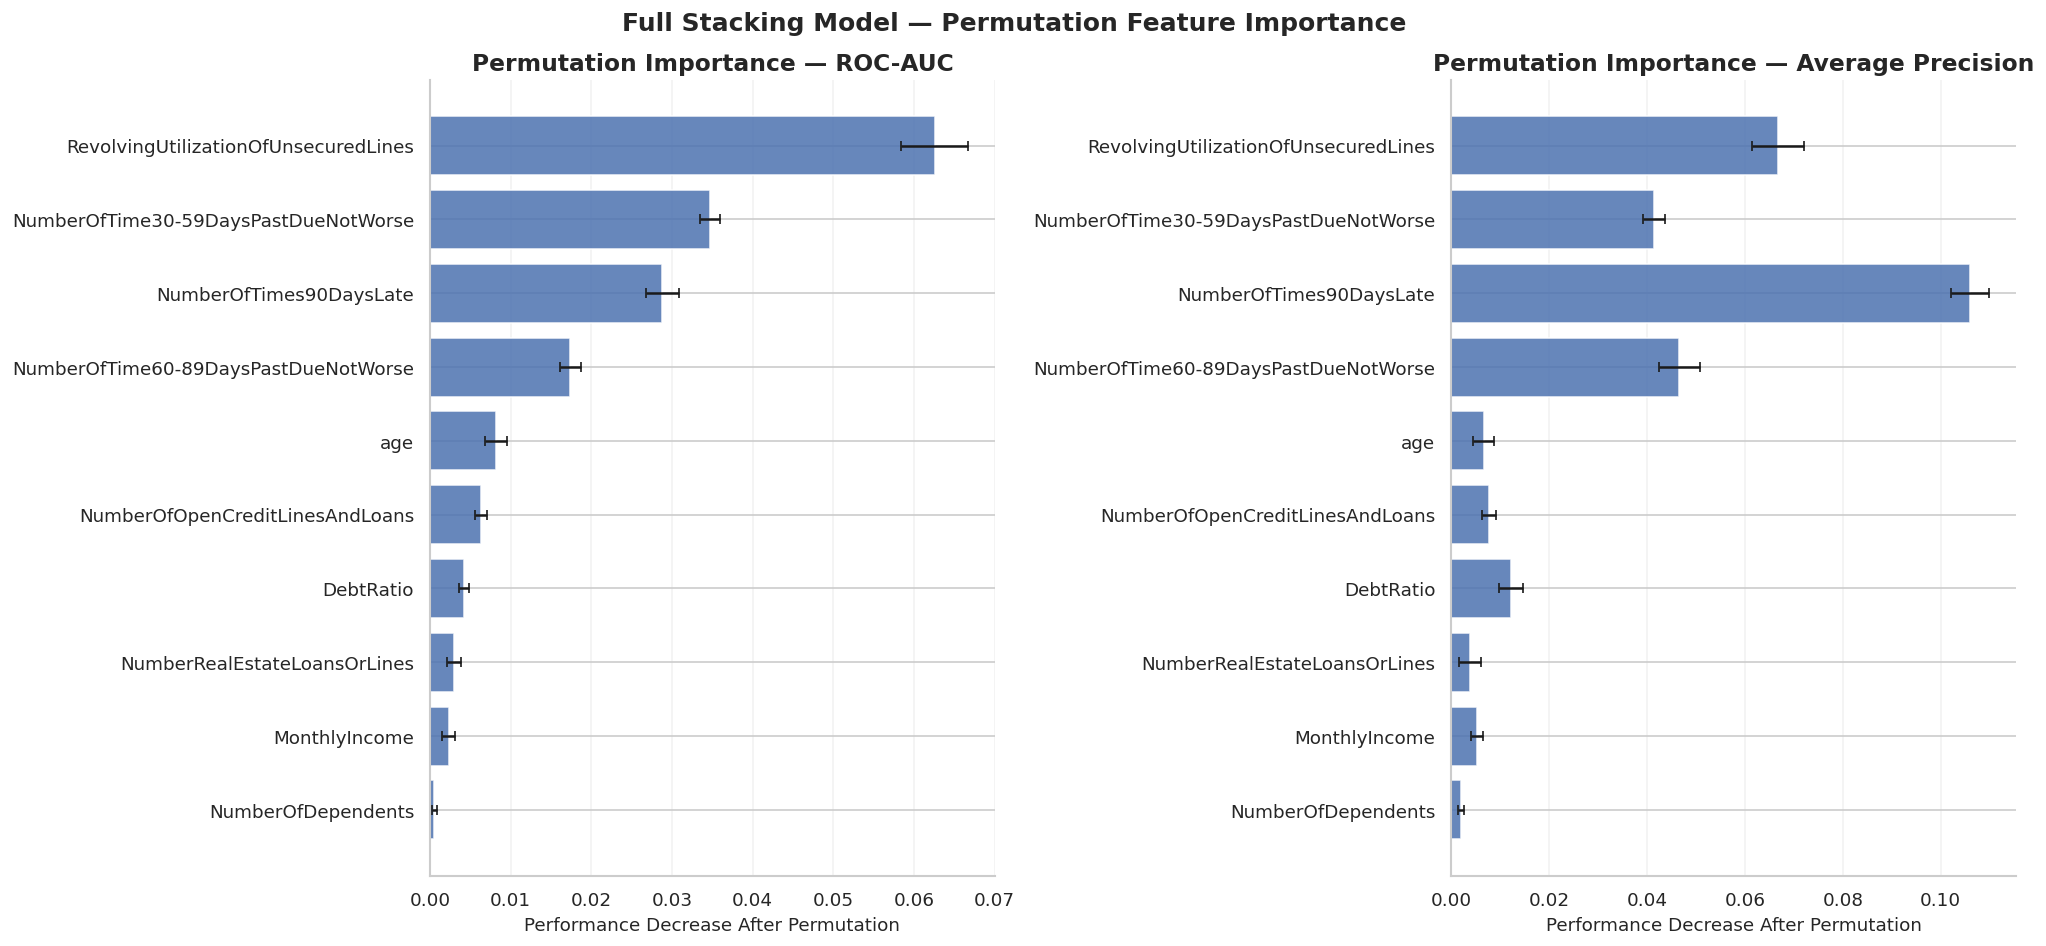


Extracting native feature importance...

NATIVE FEATURE IMPORTANCE — TOP 10 PER MODEL


,Model,Feature,Relative_Importance_Percent
0,catboost,num__log_RevolvingUtilizationOfUnsecuredLines,20.8536
1,catboost,num__RevolvingUtilizationOfUnsecuredLines,14.8154
2,catboost,num__age,8.3643
3,catboost,num__NumberOfTime30_59DaysPastDueNotWorse,7.7710
4,catboost,num__log_NumberOfTimes90DaysLate,7.6208
5,catboost,num__log_NumberOfTime30_59DaysPastDueNotWorse,6.0455
6,catboost,num__log_NumberOfTime60_89DaysPastDueNotWorse,4.2272
7,catboost,num__NumberOfTimes90DaysLate,4.1634
8,catboost,num__DebtRatio,3.8379
9,catboost,num__log_DebtRatio,2.7540


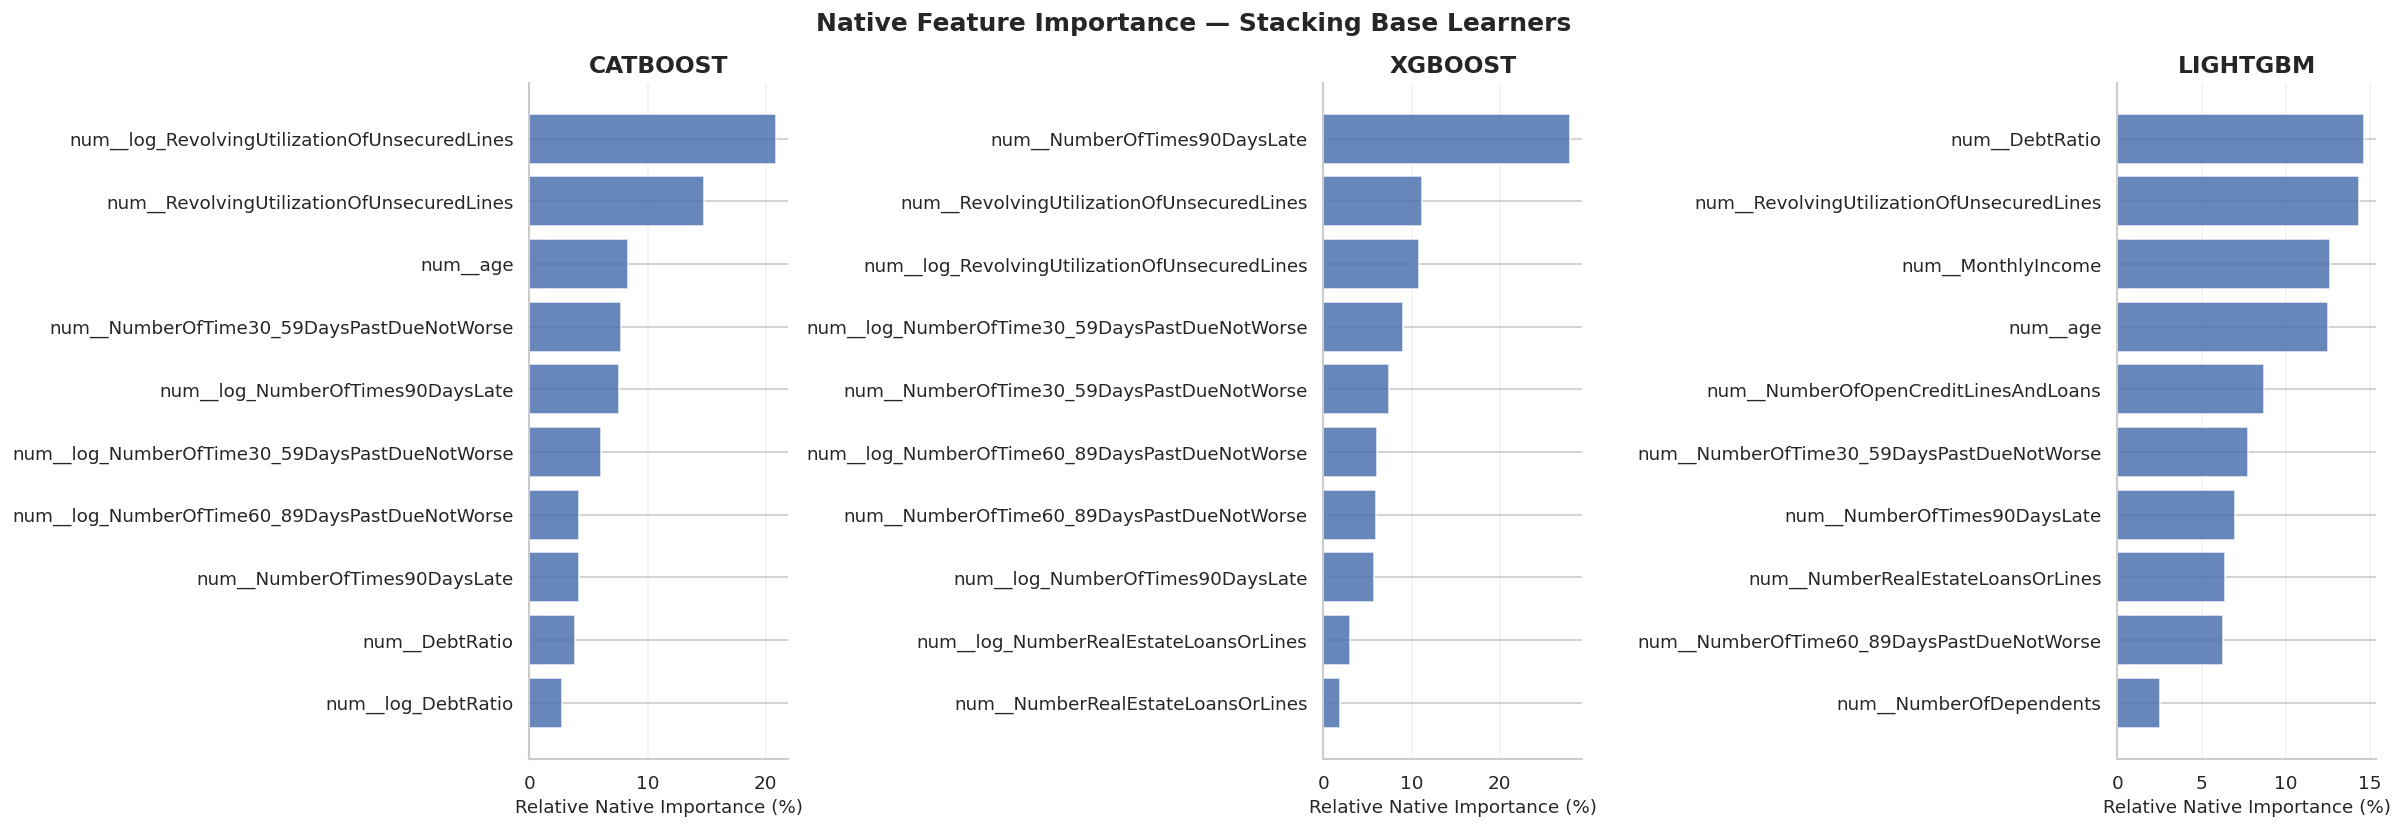


FEATURE IMPORTANCE SUMMARY

Top 5 raw features — full Stacking model:


,Feature,ROC_AUC_Importance,AP_Importance
0,RevolvingUtilizationOfUnsecuredLines,0.062549,0.066711
1,NumberOfTime30-59DaysPastDueNotWorse,0.034712,0.041454
2,NumberOfTimes90DaysLate,0.028775,0.105957
3,NumberOfTime60-89DaysPastDueNotWorse,0.017406,0.046635
4,age,0.008180,0.006609



Important interpretation notes:
- Permutation importance measures score decrease.
- Native feature importance is model-specific.
- Native importance values are not directly
  comparable across different algorithms.
- Correlated features may share importance.
- Importance does not establish causality.

No model retraining performed.
No features were removed.
Holdout used for explanation only.
Kaggle test dataset has NOT been used.


In [37]:
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

IMPORTANCE_SAMPLE_SIZE = 10000
PERMUTATION_REPEATS = 5
IMPORTANCE_RANDOM_STATE = RANDOM_STATE + 2000

print("=" * 65)
print("FINAL STACKING — FEATURE IMPORTANCE ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 2. Prepare evaluation subset
# ------------------------------------------------------------

n_holdout = len(X_holdout_final)

if IMPORTANCE_SAMPLE_SIZE < n_holdout:

    importance_indices, _ = train_test_split(
        np.arange(n_holdout),
        train_size=IMPORTANCE_SAMPLE_SIZE,
        stratify=y_holdout_final,
        random_state=IMPORTANCE_RANDOM_STATE
    )

else:
    importance_indices = np.arange(n_holdout)

X_importance = X_holdout_final.iloc[
    importance_indices
].copy()

y_importance = np.asarray(
    y_holdout_final
)[importance_indices]

assert list(X_importance.columns) == FINAL_RAW_FEATURES

print("Importance samples:", len(X_importance))
print("Raw features:", X_importance.shape[1])
print("Positive class rate:", round(y_importance.mean(), 5))


# ------------------------------------------------------------
# 3. Reference performance
# ------------------------------------------------------------

reference_probabilities = (
    final_development_model_fitted
    .predict_proba(X_importance)[:, 1]
)

reference_auc = roc_auc_score(
    y_importance,
    reference_probabilities
)

reference_ap = average_precision_score(
    y_importance,
    reference_probabilities
)

print("\nReference ROC-AUC:", round(reference_auc, 6))
print("Reference Average Precision:", round(reference_ap, 6))


# ------------------------------------------------------------
# 4. Permutation Importance — Full Stacking
# ------------------------------------------------------------

print("\nCalculating permutation importance...")

start_time = time.perf_counter()

permutation_results = permutation_importance(
    estimator=final_development_model_fitted,
    X=X_importance,
    y=y_importance,
    scoring={
        "ROC_AUC": "roc_auc",
        "Average_Precision": "average_precision"
    },
    n_repeats=PERMUTATION_REPEATS,
    random_state=IMPORTANCE_RANDOM_STATE,
    n_jobs=1
)

permutation_elapsed = time.perf_counter() - start_time

roc_importance = permutation_results["ROC_AUC"]
ap_importance = permutation_results["Average_Precision"]

permutation_importance_df = pd.DataFrame({
    "Feature": X_importance.columns,

    "ROC_AUC_Importance":
        roc_importance.importances_mean,

    "ROC_AUC_Std":
        roc_importance.importances_std,

    "AP_Importance":
        ap_importance.importances_mean,

    "AP_Std":
        ap_importance.importances_std
})

permutation_importance_df = (
    permutation_importance_df
    .sort_values(
        "ROC_AUC_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("PERMUTATION IMPORTANCE — FULL STACKING")
print("=" * 65)

display(
    permutation_importance_df.round(6)
)

print(
    "\nPermutation importance time:",
    round(permutation_elapsed, 2),
    "seconds"
)


# ------------------------------------------------------------
# 5. Plot Permutation Importance
# ------------------------------------------------------------

plot_df = (
    permutation_importance_df
    .sort_values("ROC_AUC_Importance")
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 8)
)

metrics = [
    (
        "ROC_AUC_Importance",
        "ROC_AUC_Std",
        "Permutation Importance — ROC-AUC"
    ),
    (
        "AP_Importance",
        "AP_Std",
        "Permutation Importance — Average Precision"
    )
]

for ax, (mean_col, std_col, title) in zip(
    axes,
    metrics
):

    ax.barh(
        plot_df["Feature"],
        plot_df[mean_col],
        xerr=plot_df[std_col],
        capsize=3,
        alpha=0.85
    )

    ax.axvline(
        0,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.set_xlabel("Performance Decrease After Permutation")
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Full Stacking Model — Permutation Feature Importance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Native Feature Importance — Base Learners
# ------------------------------------------------------------

print("\nExtracting native feature importance...")

base_learner_names = [
    "catboost",
    "xgboost",
    "lightgbm"
]

native_rows = []

for model_name in base_learner_names:

    # Already fitted estimators inside StackingClassifier
    base_pipeline = (
        final_development_model_fitted
        .named_estimators_[model_name]
    )

    fitted_classifier = (
        base_pipeline.named_steps["classifier"]
    )

    fitted_preprocessor = (
        base_pipeline.named_steps["preprocessing"]
    )

    # Use the fitted preprocessing pipeline to obtain
    # the actual transformed feature names.
    transformed_probe = fitted_preprocessor.transform(
        X_importance.iloc[:2]
    )

    if not isinstance(transformed_probe, pd.DataFrame):
        raise TypeError(
            f"{model_name}: expected pandas DataFrame "
            "from preprocessing."
        )

    transformed_feature_names = list(
        transformed_probe.columns
    )

    native_values = np.asarray(
        fitted_classifier.feature_importances_,
        dtype=float
    )

    assert len(native_values) == len(
        transformed_feature_names
    ), f"Feature count mismatch: {model_name}"

    native_values = np.maximum(
        native_values,
        0
    )

    importance_sum = native_values.sum()

    if importance_sum > 0:
        normalized_values = (
            native_values / importance_sum * 100
        )
    else:
        normalized_values = np.zeros_like(
            native_values
        )

    for feature_name, importance in zip(
        transformed_feature_names,
        normalized_values
    ):
        native_rows.append({
            "Model": model_name,
            "Feature": feature_name,
            "Relative_Importance_Percent": importance
        })


native_importance_df = pd.DataFrame(
    native_rows
)

native_importance_df = (
    native_importance_df
    .sort_values(
        ["Model", "Relative_Importance_Percent"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("NATIVE FEATURE IMPORTANCE — TOP 10 PER MODEL")
print("=" * 65)

native_top10 = (
    native_importance_df
    .groupby("Model", group_keys=False)
    .head(10)
)

display(
    native_top10.round(4)
)


# ------------------------------------------------------------
# 7. Native Feature Importance Plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7)
)

for ax, model_name in zip(
    axes,
    base_learner_names
):

    model_df = native_importance_df[
        native_importance_df["Model"] == model_name
    ]

    top_features = (
        model_df
        .nlargest(
            10,
            "Relative_Importance_Percent"
        )
        .sort_values(
            "Relative_Importance_Percent"
        )
    )

    ax.barh(
        top_features["Feature"],
        top_features["Relative_Importance_Percent"],
        alpha=0.85
    )

    ax.set_xlabel("Relative Native Importance (%)")
    ax.set_title(
        model_name.upper(),
        fontweight="bold"
    )
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Native Feature Importance — Stacking Base Learners",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE IMPORTANCE SUMMARY")
print("=" * 65)

print("\nTop 5 raw features — full Stacking model:")

display(
    permutation_importance_df[
        [
            "Feature",
            "ROC_AUC_Importance",
            "AP_Importance"
        ]
    ].head(5).round(6)
)

print("\nImportant interpretation notes:")
print("- Permutation importance measures score decrease.")
print("- Native feature importance is model-specific.")
print("- Native importance values are not directly")
print("  comparable across different algorithms.")
print("- Correlated features may share importance.")
print("- Importance does not establish causality.")

print("\nNo model retraining performed.")
print("No features were removed.")
print("Holdout used for explanation only.")
print("Kaggle test dataset has NOT been used.")

# SHAP Analysis: Global & Local Explainability

SHAP EXPLAINABILITY ANALYSIS
SHAP version: 0.54.1
Final model: Stacking_Tuned
Background samples: 30
Stacking explanation samples: 60

Background shape: (30, 10)
Explanation shape: (60, 10)

Calculating full Stacking SHAP values...
Full Stacking SHAP computation complete.
SHAP values shape: (60, 10)
Elapsed seconds: 17.52

Maximum SHAP additivity error: 0.0

GLOBAL SHAP IMPORTANCE — FULL STACKING


,Feature,Mean_Absolute_SHAP
0,NumberOfTimes90DaysLate,0.029920
1,RevolvingUtilizationOfUnsecuredLines,0.018707
2,NumberOfTime60-89DaysPastDueNotWorse,0.017127
3,NumberOfTime30-59DaysPastDueNotWorse,0.010072
4,NumberOfOpenCreditLinesAndLoans,0.005326
5,DebtRatio,0.005292
6,age,0.004895
7,MonthlyIncome,0.003474
8,NumberRealEstateLoansOrLines,0.001994
9,NumberOfDependents,0.001525


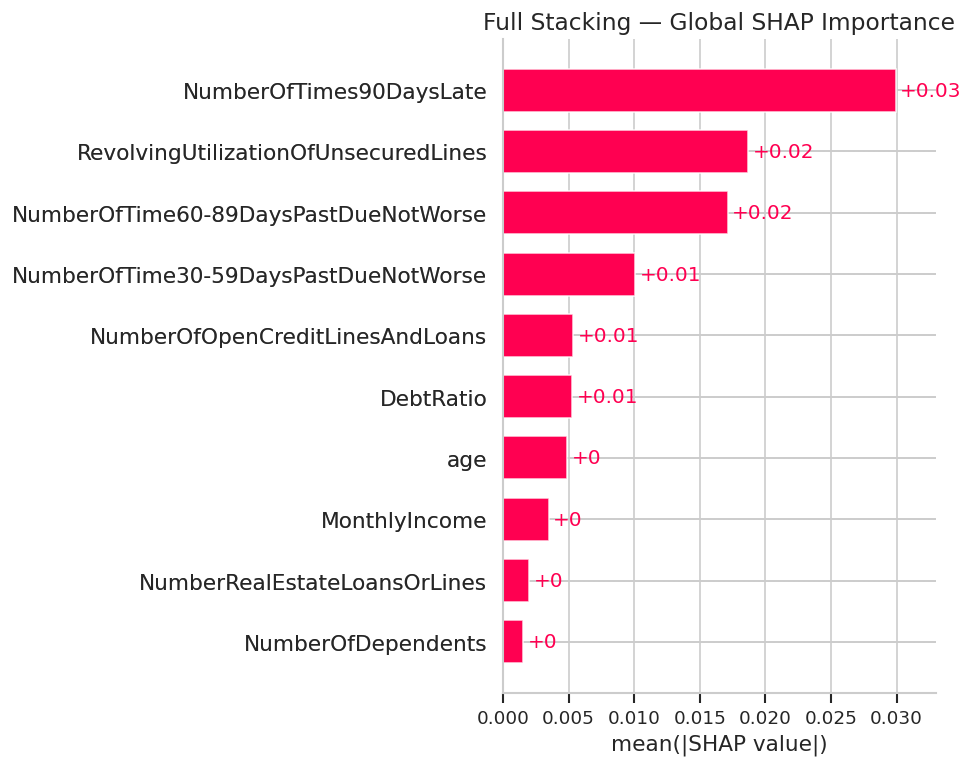

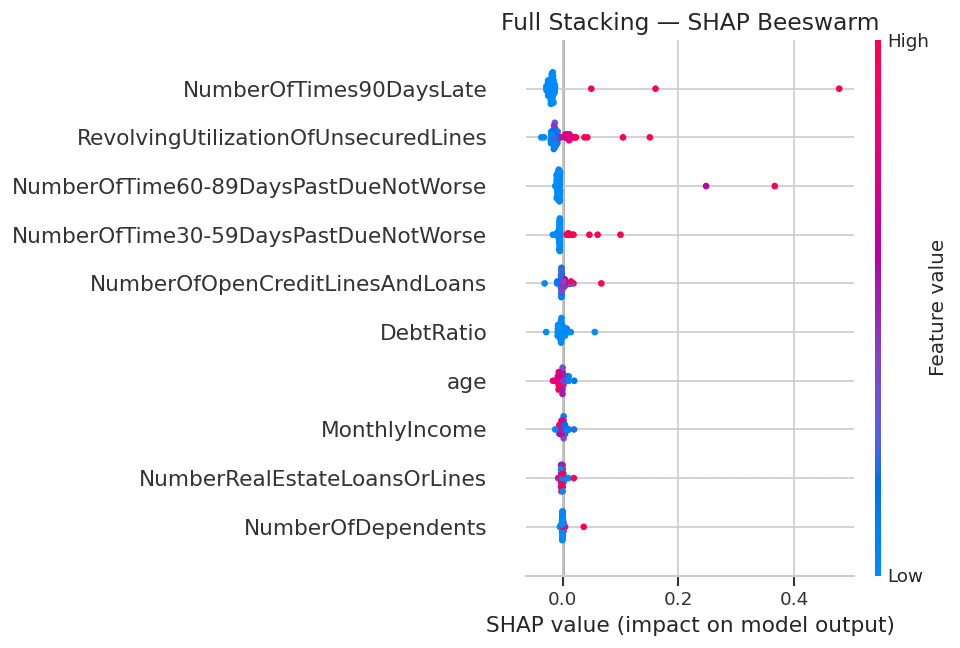


LOCAL EXPLANATION — HIGH-RISK OBSERVATION
Raw Stacking probability: 0.961428
Calibrated probability: 1.0
True class: 1


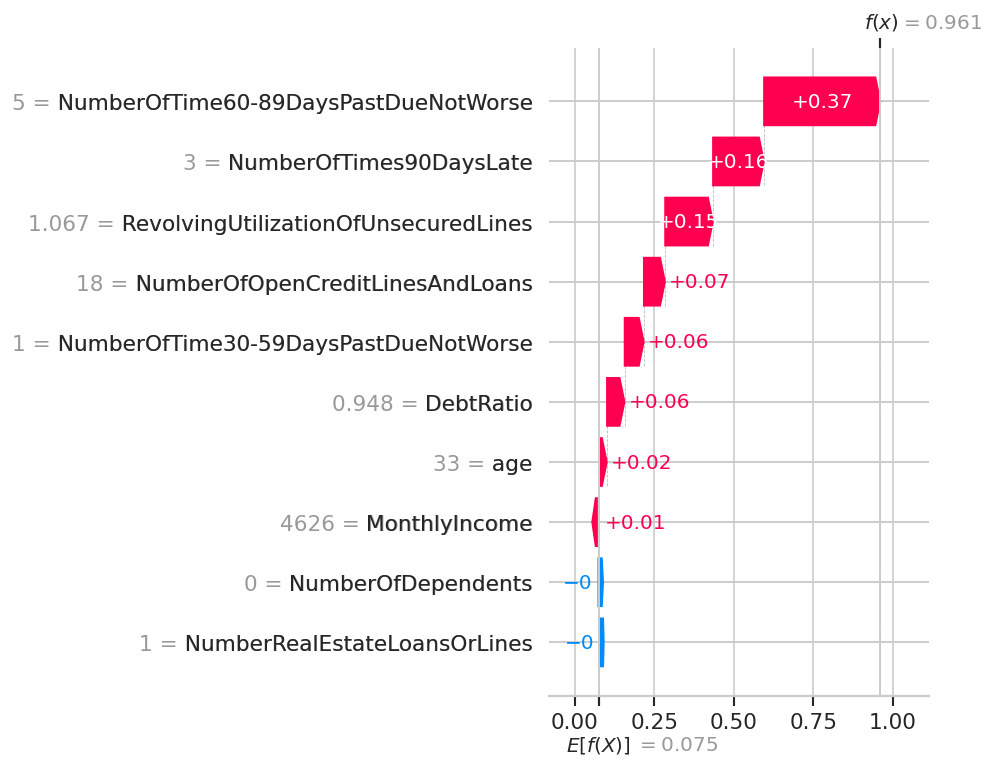


Top SHAP feature: NumberOfTimes90DaysLate


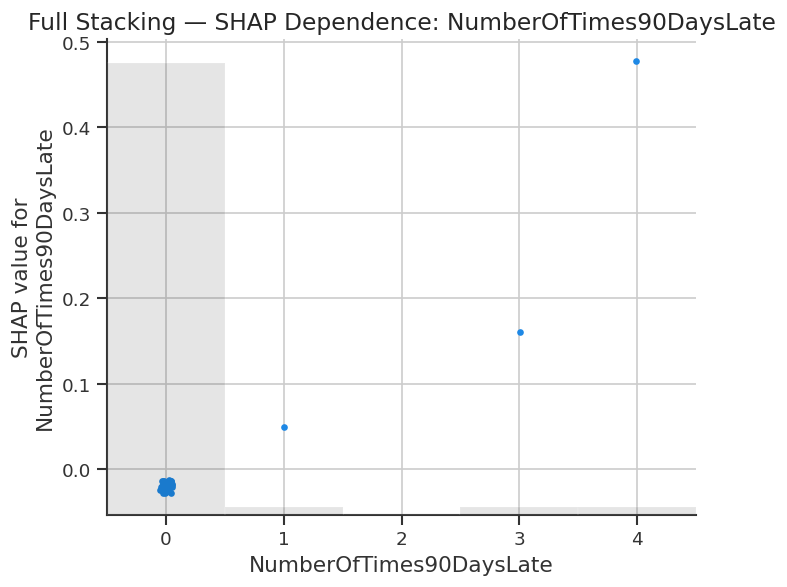


CatBoost transformed data:
Shape: (500, 26)

Calculating CatBoost TreeSHAP...
TreeSHAP elapsed seconds: 0.63
TreeSHAP shape: (500, 26)

CATBOOST TREESHAP — TOP FEATURES


,Feature,Mean_Absolute_TreeSHAP
0,num__log_RevolvingUtilizationOfUnsecuredLines,0.335767
1,num__RevolvingUtilizationOfUnsecuredLines,0.279857
2,num__age,0.228928
3,num__NumberOfTime30_59DaysPastDueNotWorse,0.148118
4,num__log_NumberOfTime30_59DaysPastDueNotWorse,0.141050
5,num__log_NumberOfTimes90DaysLate,0.099407
6,num__DebtRatio,0.081983
7,num__NumberOfOpenCreditLinesAndLoans,0.078298
8,num__MonthlyIncome_is_missing,0.074701
9,num__log_NumberOfTime60_89DaysPastDueNotWorse,0.070335


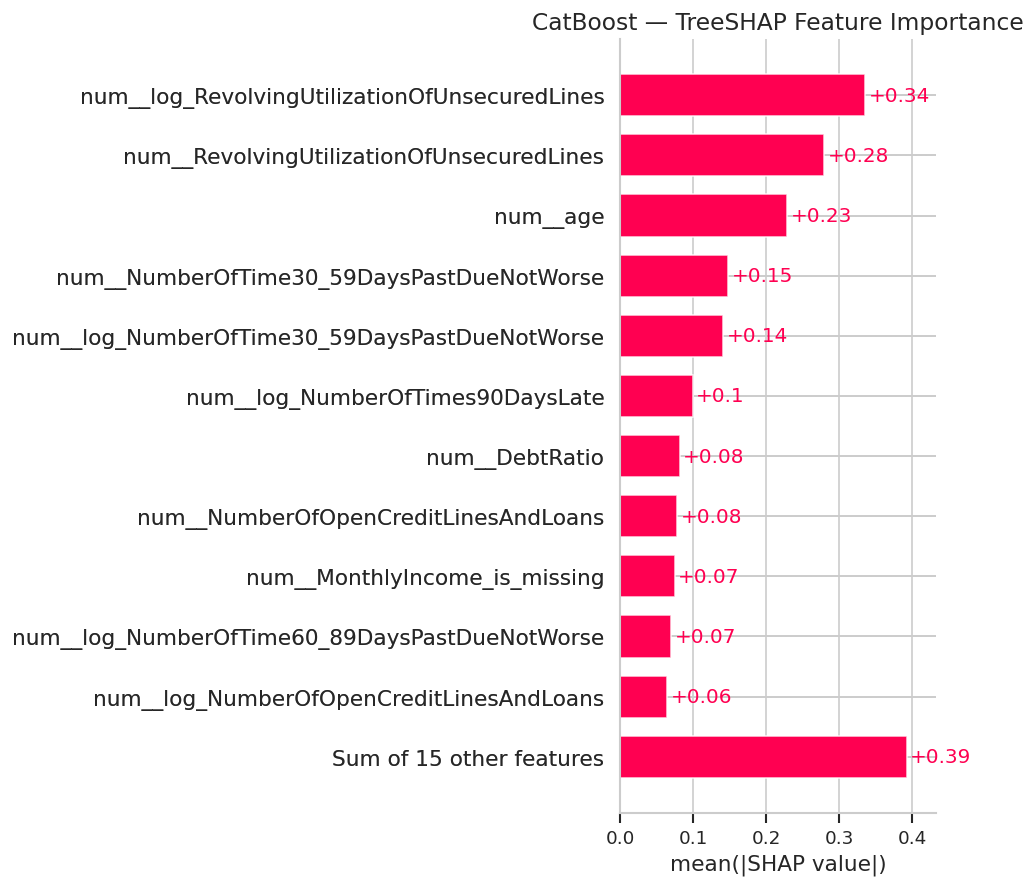

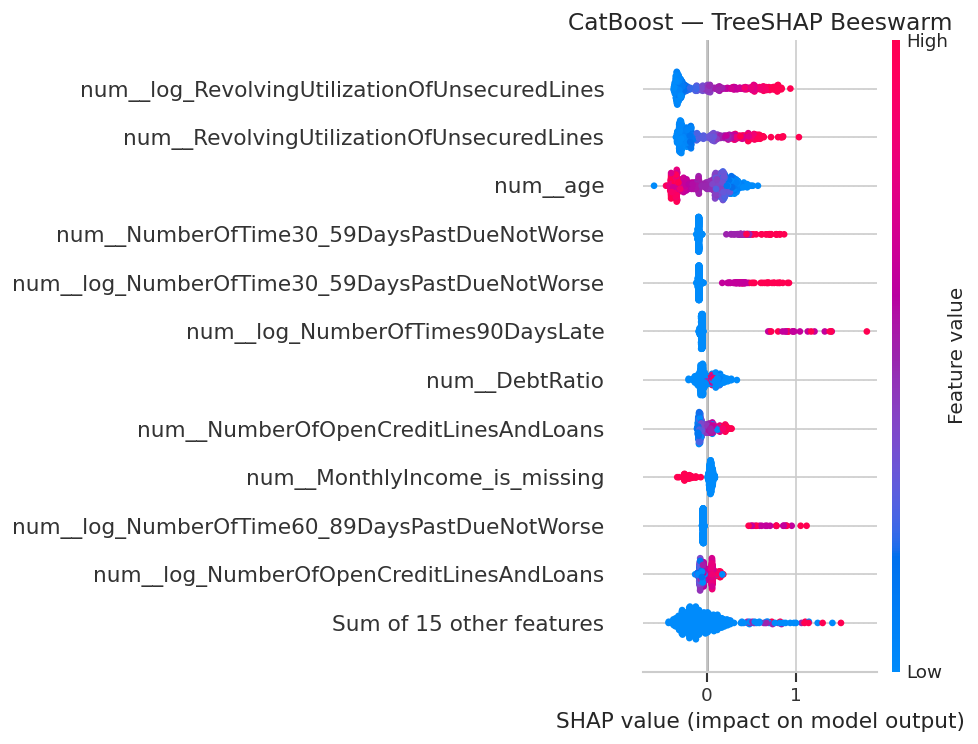


SHAP ANALYSIS COMPLETED

Top 5 full-Stacking SHAP features:


,Feature,Mean_Absolute_SHAP
0,NumberOfTimes90DaysLate,0.029920
1,RevolvingUtilizationOfUnsecuredLines,0.018707
2,NumberOfTime60-89DaysPastDueNotWorse,0.017127
3,NumberOfTime30-59DaysPastDueNotWorse,0.010072
4,NumberOfOpenCreditLinesAndLoans,0.005326



Top 5 CatBoost TreeSHAP features:


,Feature,Mean_Absolute_TreeSHAP
0,num__log_RevolvingUtilizationOfUnsecuredLines,0.335767
1,num__RevolvingUtilizationOfUnsecuredLines,0.279857
2,num__age,0.228928
3,num__NumberOfTime30_59DaysPastDueNotWorse,0.148118
4,num__log_NumberOfTime30_59DaysPastDueNotWorse,0.141050



Interpretation notes:
- Full Stacking SHAP explains raw class-1 scores.
- CatBoost TreeSHAP explains CatBoost raw margins.
- TreeSHAP values are not probability-point changes.
- Correlated features affect attribution.
- SHAP attribution does not establish causality.

No model training or tuning performed.
Holdout used for explanation only.
Kaggle test data has NOT been used.


In [38]:
import sys
import subprocess
from IPython.display import display

try:
    import shap
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "shap"
    ])
    import shap

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SHAP_BACKGROUND_SIZE = 30
SHAP_EXPLAIN_SIZE = 60
TREE_SHAP_SAMPLE_SIZE = 500

SHAP_RANDOM_STATE = RANDOM_STATE + 3000

rng = np.random.default_rng(SHAP_RANDOM_STATE)

print("=" * 65)
print("SHAP EXPLAINABILITY ANALYSIS")
print("=" * 65)

print("SHAP version:", shap.__version__)
print("Final model:", FINAL_MODEL_NAME)
print("Background samples:", SHAP_BACKGROUND_SIZE)
print("Stacking explanation samples:", SHAP_EXPLAIN_SIZE)


# ============================================================
# PART A — FULL STACKING: MODEL-AGNOSTIC SHAP
# ============================================================

# ------------------------------------------------------------
# 2. Select background and explanation samples
# ------------------------------------------------------------

# Background data comes from development data.
X_shap_background = (
    X_train[FINAL_RAW_FEATURES]
    .sample(
        n=min(SHAP_BACKGROUND_SIZE, len(X_train)),
        random_state=SHAP_RANDOM_STATE
    )
    .copy()
)

# Include one high-risk observation for local explanation.
highest_risk_pos = int(
    np.argmax(holdout_raw_probabilities)
)

available_positions = np.arange(
    len(X_holdout_final)
)

available_positions = available_positions[
    available_positions != highest_risk_pos
]

other_positions = rng.choice(
    available_positions,
    size=min(
        SHAP_EXPLAIN_SIZE - 1,
        len(available_positions)
    ),
    replace=False
)

shap_positions = np.concatenate([
    [highest_risk_pos],
    other_positions
])

X_shap_raw = (
    X_holdout_final
    .iloc[shap_positions][FINAL_RAW_FEATURES]
    .copy()
)

print("\nBackground shape:", X_shap_background.shape)
print("Explanation shape:", X_shap_raw.shape)


# ------------------------------------------------------------
# 3. Prediction function for full Stacking
# ------------------------------------------------------------

def stacking_predict_probability(data):
    """
    Raw 10-feature input -> Stacking class-1 probability.

    SHAP supplies NumPy arrays to the prediction
    function, so feature names are reconstructed.
    """

    if isinstance(data, pd.DataFrame):
        data_df = data.loc[
            :, FINAL_RAW_FEATURES
        ].copy()
    else:
        data_df = pd.DataFrame(
            np.asarray(data, dtype=float),
            columns=FINAL_RAW_FEATURES
        )

    return (
        final_development_model_fitted
        .predict_proba(data_df)[:, 1]
    )


# ------------------------------------------------------------
# 4. Build model-agnostic SHAP explainer
# ------------------------------------------------------------

print("\nCalculating full Stacking SHAP values...")

start_time = time.perf_counter()

stacking_shap_explainer = shap.Explainer(
    stacking_predict_probability,
    shap.maskers.Independent(
        X_shap_background,
        max_samples=len(X_shap_background)
    ),
    algorithm="permutation",
    seed=SHAP_RANDOM_STATE
)

# Each pass requires at least 2*M + 1 evaluations.
# Use two permutation passes per observation.

n_raw_features = len(FINAL_RAW_FEATURES)

SHAP_MAX_EVALS = (
    2 * n_raw_features + 1
) * 2

stacking_shap_values = stacking_shap_explainer(
    X_shap_raw,
    max_evals=SHAP_MAX_EVALS,
    silent=True
)

shap_elapsed = time.perf_counter() - start_time

print("Full Stacking SHAP computation complete.")
print("SHAP values shape:", stacking_shap_values.values.shape)
print("Elapsed seconds:", round(shap_elapsed, 2))

assert stacking_shap_values.values.shape == (
    len(X_shap_raw),
    len(FINAL_RAW_FEATURES)
)


# ------------------------------------------------------------
# 5. Check SHAP additivity
# ------------------------------------------------------------

reconstructed_probabilities = (
    np.asarray(stacking_shap_values.base_values).ravel()
    + stacking_shap_values.values.sum(axis=1)
)

actual_probabilities = (
    stacking_predict_probability(X_shap_raw)
)

max_additivity_error = np.max(
    np.abs(
        reconstructed_probabilities
        - actual_probabilities
    )
)

print(
    "\nMaximum SHAP additivity error:",
    round(float(max_additivity_error), 8)
)


# ------------------------------------------------------------
# 6. Global SHAP Feature Importance
# ------------------------------------------------------------

mean_absolute_shap = np.mean(
    np.abs(stacking_shap_values.values),
    axis=0
)

stacking_shap_importance_df = (
    pd.DataFrame({
        "Feature": FINAL_RAW_FEATURES,
        "Mean_Absolute_SHAP": mean_absolute_shap
    })
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("GLOBAL SHAP IMPORTANCE — FULL STACKING")
print("=" * 65)

display(
    stacking_shap_importance_df.round(6)
)


# ------------------------------------------------------------
# 7. Global SHAP Bar Plot
# ------------------------------------------------------------

shap.plots.bar(
    stacking_shap_values,
    max_display=10,
    show=False
)

plt.title(
    "Full Stacking — Global SHAP Importance"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. SHAP Beeswarm Plot
# ------------------------------------------------------------

shap.plots.beeswarm(
    stacking_shap_values,
    max_display=10,
    show=False
)

plt.title(
    "Full Stacking — SHAP Beeswarm"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Local explanation — high-risk customer
# ------------------------------------------------------------

# First observation was explicitly selected
# as the highest-scoring holdout observation.

local_index = 0

local_raw_probability = float(
    actual_probabilities[local_index]
)

local_calibrated_probability = float(
    holdout_calibrated_probabilities[
        highest_risk_pos
    ]
)

local_true_label = int(
    y_holdout_final[highest_risk_pos]
)

print("\n" + "=" * 65)
print("LOCAL EXPLANATION — HIGH-RISK OBSERVATION")
print("=" * 65)

print(
    "Raw Stacking probability:",
    round(local_raw_probability, 6)
)

print(
    "Calibrated probability:",
    round(local_calibrated_probability, 6)
)

print("True class:", local_true_label)

# Waterfall contributions are in raw Stacking
# probability units, not calibrated probabilities.

shap.plots.waterfall(
    stacking_shap_values[local_index],
    max_display=10,
    show=False
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. SHAP Dependence Plot
# ------------------------------------------------------------

top_raw_feature = (
    stacking_shap_importance_df
    .iloc[0]["Feature"]
)

print("\nTop SHAP feature:", top_raw_feature)

shap.plots.scatter(
    stacking_shap_values[:, top_raw_feature],
    show=False
)

plt.title(
    f"Full Stacking — SHAP Dependence: {top_raw_feature}"
)

plt.tight_layout()
plt.show()


# ============================================================
# PART B — CATBOOST TREESHAP
# ============================================================

# ------------------------------------------------------------
# 11. Select fitted CatBoost base learner
# ------------------------------------------------------------

fitted_catboost_pipeline = (
    final_development_model_fitted
    .named_estimators_["catboost"]
)

fitted_catboost_model = (
    fitted_catboost_pipeline
    .named_steps["classifier"]
)

fitted_catboost_preprocessing = (
    fitted_catboost_pipeline
    .named_steps["preprocessing"]
)


# ------------------------------------------------------------
# 12. Transform data using fitted preprocessing
# ------------------------------------------------------------

X_tree_raw = (
    X_holdout_final[FINAL_RAW_FEATURES]
    .sample(
        n=min(
            TREE_SHAP_SAMPLE_SIZE,
            len(X_holdout_final)
        ),
        random_state=SHAP_RANDOM_STATE
    )
)

X_tree_transformed = (
    fitted_catboost_preprocessing
    .transform(X_tree_raw)
)

print("\nCatBoost transformed data:")
print("Shape:", X_tree_transformed.shape)

assert X_tree_transformed.shape[1] == 26


# ------------------------------------------------------------
# 13. Calculate TreeSHAP
# ------------------------------------------------------------

print("\nCalculating CatBoost TreeSHAP...")

start_time = time.perf_counter()

catboost_shap_explainer = shap.TreeExplainer(
    fitted_catboost_model,
    model_output="raw"
)

catboost_shap_values = (
    catboost_shap_explainer(
        X_tree_transformed
    )
)

# Handle multi-output explanations if present.
if catboost_shap_values.values.ndim == 3:
    catboost_shap_values = (
        catboost_shap_values[:, :, 1]
    )

tree_shap_elapsed = (
    time.perf_counter() - start_time
)

print(
    "TreeSHAP elapsed seconds:",
    round(tree_shap_elapsed, 2)
)

print(
    "TreeSHAP shape:",
    catboost_shap_values.values.shape
)


# ------------------------------------------------------------
# 14. CatBoost Global SHAP Importance
# ------------------------------------------------------------

catboost_mean_shap = np.mean(
    np.abs(catboost_shap_values.values),
    axis=0
)

catboost_shap_importance_df = (
    pd.DataFrame({
        "Feature": X_tree_transformed.columns,
        "Mean_Absolute_TreeSHAP": catboost_mean_shap
    })
    .sort_values(
        "Mean_Absolute_TreeSHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("CATBOOST TREESHAP — TOP FEATURES")
print("=" * 65)

display(
    catboost_shap_importance_df
    .head(15)
    .round(6)
)


# ------------------------------------------------------------
# 15. CatBoost SHAP Bar Plot
# ------------------------------------------------------------

shap.plots.bar(
    catboost_shap_values,
    max_display=12,
    show=False
)

plt.title(
    "CatBoost — TreeSHAP Feature Importance"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. CatBoost Beeswarm Plot
# ------------------------------------------------------------

shap.plots.beeswarm(
    catboost_shap_values,
    max_display=12,
    show=False
)

plt.title(
    "CatBoost — TreeSHAP Beeswarm"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 17. Final SHAP summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SHAP ANALYSIS COMPLETED")
print("=" * 65)

print("\nTop 5 full-Stacking SHAP features:")

display(
    stacking_shap_importance_df.head(5).round(6)
)

print("\nTop 5 CatBoost TreeSHAP features:")

display(
    catboost_shap_importance_df.head(5).round(6)
)

print("\nInterpretation notes:")
print("- Full Stacking SHAP explains raw class-1 scores.")
print("- CatBoost TreeSHAP explains CatBoost raw margins.")
print("- TreeSHAP values are not probability-point changes.")
print("- Correlated features affect attribution.")
print("- SHAP attribution does not establish causality.")

print("\nNo model training or tuning performed.")
print("Holdout used for explanation only.")
print("Kaggle test data has NOT been used.")

# Group Comparison Analysis

GROUP COMPARISON — FINAL HOLDOUT
Observations: 30000
Positive cases: 2005
Thresholds: {'Maximum_F2': 0.1111111111111111, 'Recall_78': 0.06838709677419354}

Income group boundaries: [ -inf 3400. 5390. 8238.   inf]

AGE_GROUP — MAXIMUM F2 THRESHOLD


,Group,Customers,Positive_Cases,Event_Rate,ROC_AUC,Average_Precision,Precision,Recall,Recall_CI_Low,Recall_CI_High,FPR
0,18-29,1738,227,0.13061,0.84130,0.47167,0.32535,0.71806,0.65628,0.77259,0.22369
2,30-44,7820,772,0.09872,0.84952,0.44854,0.32185,0.71373,0.68085,0.74450,0.16473
4,45-59,10747,725,0.06746,0.85345,0.38597,0.28156,0.62759,0.59181,0.66202,0.11585
6,60-74,7418,244,0.03289,0.87095,0.36423,0.29655,0.52869,0.46609,0.59039,0.04265
8,75+,2277,37,0.01625,0.84225,0.16359,0.18750,0.24324,0.13361,0.40118,0.01741



INCOME_QUARTILE — MAXIMUM F2 THRESHOLD


,Group,Customers,Positive_Cases,Event_Rate,ROC_AUC,Average_Precision,Precision,Recall,Recall_CI_Low,Recall_CI_High,FPR
10,Missing,6056,350,0.05779,0.89354,0.44331,0.31714,0.67143,0.62059,0.71854,0.08868
12,Q1,5970,560,0.09380,0.85498,0.42361,0.31454,0.70714,0.66814,0.74332,0.15952
14,Q2,5804,455,0.07839,0.86078,0.43351,0.29773,0.66154,0.61687,0.70350,0.13274
16,Q3,6153,375,0.06095,0.86007,0.40230,0.31309,0.61867,0.56854,0.66639,0.08809
18,Q4,6017,265,0.04404,0.85831,0.33547,0.25536,0.53962,0.47947,0.59864,0.07250



INCOME_MISSINGNESS — MAXIMUM F2 THRESHOLD


,Group,Customers,Positive_Cases,Event_Rate,ROC_AUC,Average_Precision,Precision,Recall,Recall_CI_Low,Recall_CI_High,FPR
20,Available,23944,1655,0.06912,0.86325,0.40696,0.30020,0.64773,0.62440,0.67038,0.11212
22,Missing,6056,350,0.05779,0.89354,0.44331,0.31714,0.67143,0.62059,0.71854,0.08868



GROUP RECALL — FIXED RECALL-78 THRESHOLD


,Group_Type,Group,Customers,Positive_Cases,Precision,Recall,Recall_CI_Low,Recall_CI_High,FPR
1,Age_Group,18-29,1738,227,0.23760,0.90749,0.86272,0.93870,0.43746
3,Age_Group,30-44,7820,772,0.21835,0.84456,0.81730,0.86841,0.33116
5,Age_Group,45-59,10747,725,0.19212,0.78069,0.74913,0.80929,0.23748
7,Age_Group,60-74,7418,244,0.20180,0.64344,0.58154,0.70089,0.08656
9,Age_Group,75+,2277,37,0.14151,0.40541,0.26346,0.56514,0.04062
11,Income_Quartile,Missing,6056,350,0.23190,0.81429,0.77021,0.85154,0.16544
13,Income_Quartile,Q1,5970,560,0.22380,0.84643,0.81422,0.87392,0.30388
15,Income_Quartile,Q2,5804,455,0.20387,0.81099,0.77247,0.84430,0.26940
17,Income_Quartile,Q3,6153,375,0.19728,0.73600,0.68915,0.77806,0.19436
19,Income_Quartile,Q4,6017,265,0.17036,0.72453,0.66782,0.77482,0.16255


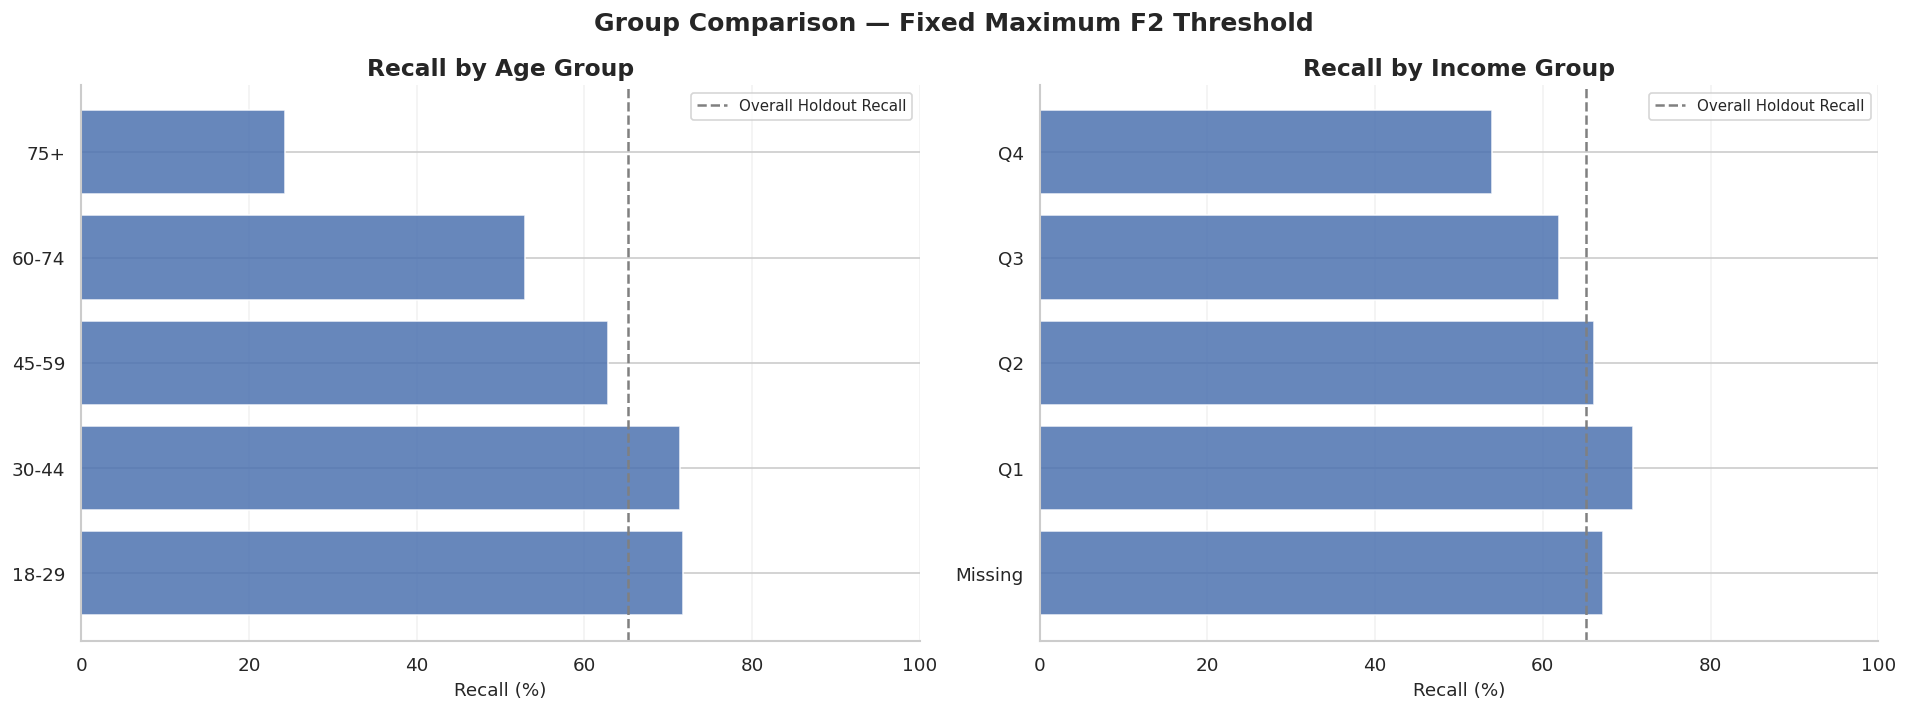


PREDICTED RISK BAND COMPARISON


,Risk_Band,Customers,Delinquencies,Mean_Predicted_Risk,Observed_Risk,Calibration_Gap
0,<1%,7884,37,0.004701,0.004693,0.000008
1,1-5%,13955,344,0.024089,0.024651,-0.000562
2,5-10%,3445,266,0.081003,0.077213,0.003790
3,10-25%,2542,425,0.158569,0.167191,-0.008622
4,25%+,2174,933,0.430439,0.429163,0.001276


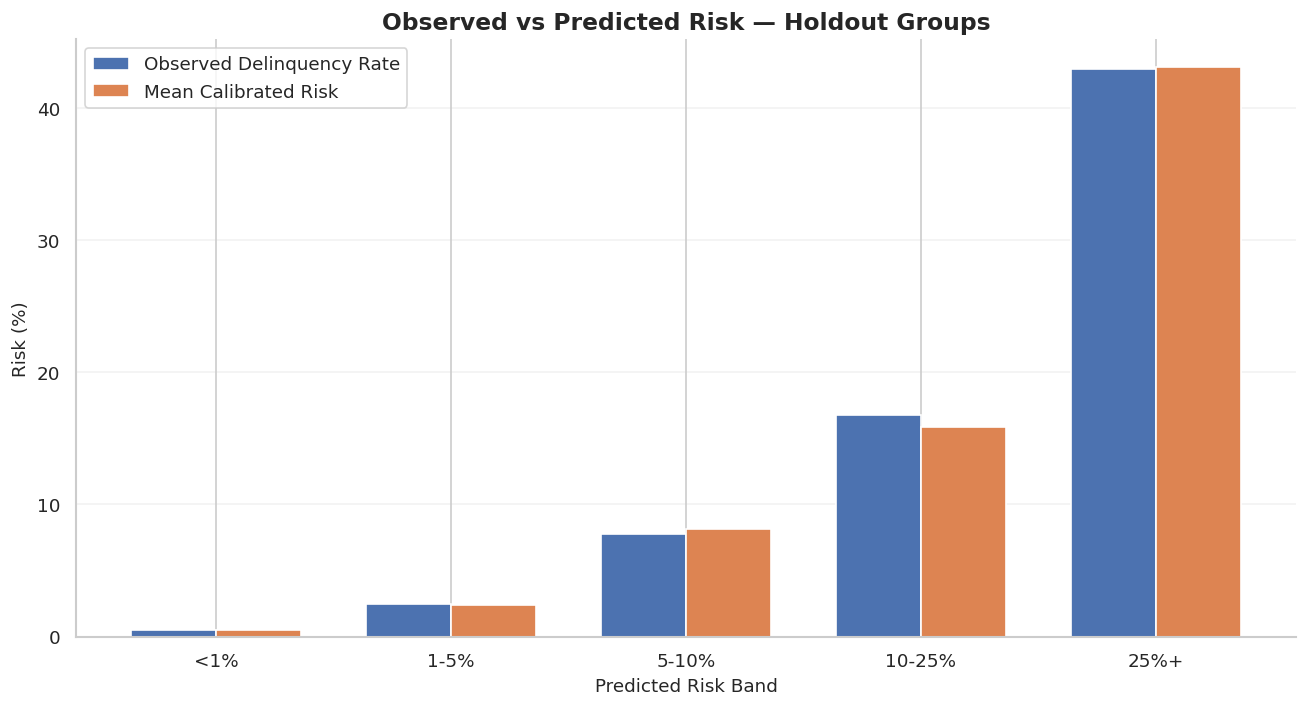


GROUP PERFORMANCE RANGES

Age_Group
Recall range: 0.2432 to 0.7181
FPR range: 0.0174 to 0.2237
ROC-AUC range: 0.8413 to 0.8710

Income_Quartile
Recall range: 0.5396 to 0.7071
FPR range: 0.0725 to 0.1595
ROC-AUC range: 0.8550 to 0.8935

Income_Missingness
Recall range: 0.6477 to 0.6714
FPR range: 0.0887 to 0.1121
ROC-AUC range: 0.8633 to 0.8935

GROUP COMPARISON ANALYSIS COMPLETED
Model: Stacking_Tuned
Calibration: Isotonic
Thresholds remained unchanged.
No models were retrained.
No groups were used for model selection.
Kaggle test dataset has NOT been used.


In [39]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MIN_GROUP_SAMPLES = 100
MIN_POSITIVES_FOR_AUC = 15

GROUP_THRESHOLDS = {
    "Maximum_F2": CALIBRATED_THRESHOLD_F2,
    "Recall_78": CALIBRATED_THRESHOLD_RECALL78
}

group_data = X_holdout_final.reset_index(
    drop=True
).copy()

group_data["Actual"] = np.asarray(
    y_holdout_final, dtype=int
)

group_data["Raw_Score"] = np.asarray(
    holdout_raw_probabilities, dtype=float
)

group_data["Calibrated_Risk"] = np.asarray(
    holdout_calibrated_probabilities, dtype=float
)

assert len(group_data) == 30000

print("=" * 65)
print("GROUP COMPARISON — FINAL HOLDOUT")
print("=" * 65)

print("Observations:", len(group_data))
print("Positive cases:", group_data["Actual"].sum())
print("Thresholds:", GROUP_THRESHOLDS)


# ------------------------------------------------------------
# 2. Age groups
# ------------------------------------------------------------

AGE_LABELS = [
    "18-29",
    "30-44",
    "45-59",
    "60-74",
    "75+"
]

age_values = group_data["age"]

# Treat invalid / missing ages separately.
age_valid = age_values.where(age_values >= 18)

age_groups = pd.cut(
    age_valid,
    bins=[18, 30, 45, 60, 75, np.inf],
    labels=AGE_LABELS,
    right=False
)

group_data["Age_Group"] = (
    age_groups.astype(object)
    .fillna("Unknown/Invalid")
)


# ------------------------------------------------------------
# 3. Monthly income quartiles
# ------------------------------------------------------------

# Quartile cutoffs come from development data,
# not the holdout labels.

train_income = (
    X_train["MonthlyIncome"]
    .dropna()
    .to_numpy(dtype=float)
)

income_quantiles = np.unique(
    np.quantile(
        train_income,
        [0, 0.25, 0.50, 0.75, 1.0]
    )
)

income_bins = np.concatenate([
    [-np.inf],
    income_quantiles[1:-1],
    [np.inf]
])

n_income_groups = len(income_bins) - 1

INCOME_LABELS = [
    f"Q{i + 1}"
    for i in range(n_income_groups)
]

income_groups = pd.cut(
    group_data["MonthlyIncome"],
    bins=income_bins,
    labels=INCOME_LABELS,
    include_lowest=True
)

group_data["Income_Quartile"] = (
    income_groups.astype(object)
    .fillna("Missing")
)

group_data["Income_Missingness"] = np.where(
    group_data["MonthlyIncome"].isna(),
    "Missing",
    "Available"
)

print("\nIncome group boundaries:", income_bins)


# ------------------------------------------------------------
# 4. Predicted risk bands
# ------------------------------------------------------------

RISK_BAND_LABELS = [
    "<1%",
    "1-5%",
    "5-10%",
    "10-25%",
    "25%+"
]

group_data["Risk_Band"] = pd.cut(
    group_data["Calibrated_Risk"],
    bins=[0, 0.01, 0.05, 0.10, 0.25, np.inf],
    labels=RISK_BAND_LABELS,
    right=False,
    include_lowest=True
)


# ------------------------------------------------------------
# 5. Wilson confidence intervals
# ------------------------------------------------------------

def wilson_interval(successes, total, z=1.96):

    if total == 0:
        return np.nan, np.nan

    p = successes / total
    z2 = z ** 2

    denominator = 1 + z2 / total

    center = (
        p + z2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            p * (1 - p) / total
            + z2 / (4 * total ** 2)
        )
    ) / denominator

    return (
        max(0, center - margin),
        min(1, center + margin)
    )


# ------------------------------------------------------------
# 6. Group performance metrics
# ------------------------------------------------------------

def evaluate_group(
    subset,
    group_type,
    group_name,
    strategy,
    threshold
):

    y = subset["Actual"].to_numpy(
        dtype=int
    )

    scores = subset["Raw_Score"].to_numpy()
    calibrated = subset["Calibrated_Risk"].to_numpy()

    pred = calibrated >= threshold

    tp = int(np.sum((y == 1) & pred))
    fp = int(np.sum((y == 0) & pred))
    fn = int(np.sum((y == 1) & ~pred))
    tn = int(np.sum((y == 0) & ~pred))

    n = len(y)
    positive_count = tp + fn
    negative_count = tn + fp

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else np.nan
    )

    recall = (
        tp / positive_count
        if positive_count > 0 else np.nan
    )

    fpr = (
        fp / negative_count
        if negative_count > 0 else np.nan
    )

    recall_low, recall_high = wilson_interval(
        tp, positive_count
    )

    fpr_low, fpr_high = wilson_interval(
        fp, negative_count
    )

    # Avoid interpreting AUC from tiny groups.
    if (
        positive_count >= MIN_POSITIVES_FOR_AUC
        and negative_count >= MIN_POSITIVES_FOR_AUC
        and n >= MIN_GROUP_SAMPLES
    ):
        auc = roc_auc_score(y, scores)
        ap = average_precision_score(y, scores)
    else:
        auc = np.nan
        ap = np.nan

    return {
        "Group_Type": group_type,
        "Group": str(group_name),
        "Strategy": strategy,
        "Customers": n,
        "Positive_Cases": positive_count,
        "Event_Rate": positive_count / n,
        "Mean_Calibrated_Risk": np.mean(calibrated),
        "ROC_AUC": auc,
        "Average_Precision": ap,
        "Precision": precision,
        "Recall": recall,
        "Recall_CI_Low": recall_low,
        "Recall_CI_High": recall_high,
        "FPR": fpr,
        "FPR_CI_Low": fpr_low,
        "FPR_CI_High": fpr_high,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }


# ------------------------------------------------------------
# 7. Evaluate demographic / data-quality groups
# ------------------------------------------------------------

GROUP_COLUMNS = [
    "Age_Group",
    "Income_Quartile",
    "Income_Missingness"
]

group_rows = []

for group_column in GROUP_COLUMNS:

    for group_name, subset in group_data.groupby(
        group_column,
        sort=True,
        dropna=False
    ):

        for strategy, threshold in (
            GROUP_THRESHOLDS.items()
        ):

            result = evaluate_group(
                subset,
                group_column,
                group_name,
                strategy,
                threshold
            )

            group_rows.append(result)

group_comparison_df = pd.DataFrame(
    group_rows
)


# ------------------------------------------------------------
# 8. Summary tables
# ------------------------------------------------------------

summary_columns = [
    "Group",
    "Customers",
    "Positive_Cases",
    "Event_Rate",
    "ROC_AUC",
    "Average_Precision",
    "Precision",
    "Recall",
    "Recall_CI_Low",
    "Recall_CI_High",
    "FPR"
]

for group_column in GROUP_COLUMNS:

    print("\n" + "=" * 65)
    print(
        f"{group_column.upper()} — MAXIMUM F2 THRESHOLD"
    )
    print("=" * 65)

    result = group_comparison_df[
        (group_comparison_df["Group_Type"] == group_column)
        & (group_comparison_df["Strategy"] == "Maximum_F2")
    ]

    display(
        result[summary_columns].round(5)
    )


# ------------------------------------------------------------
# 9. Recall >= 78% strategy comparison
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("GROUP RECALL — FIXED RECALL-78 THRESHOLD")
print("=" * 65)

recall78_group_table = group_comparison_df[
    group_comparison_df["Strategy"] == "Recall_78"
][[
    "Group_Type",
    "Group",
    "Customers",
    "Positive_Cases",
    "Precision",
    "Recall",
    "Recall_CI_Low",
    "Recall_CI_High",
    "FPR"
]]

display(recall78_group_table.round(5))


# ------------------------------------------------------------
# 10. Age & Income group visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6)
)

for ax, group_column, title in zip(
    axes,
    ["Age_Group", "Income_Quartile"],
    ["Recall by Age Group", "Recall by Income Group"]
):

    plot_df = group_comparison_df[
        (group_comparison_df["Group_Type"] == group_column)
        & (group_comparison_df["Strategy"] == "Maximum_F2")
    ].copy()

    plot_df = plot_df[
        plot_df["Positive_Cases"] >= MIN_POSITIVES_FOR_AUC
    ]

    ax.barh(
        plot_df["Group"],
        plot_df["Recall"] * 100,
        alpha=0.85
    )

    ax.axvline(
        65.187,
        linestyle="--",
        color="gray",
        label="Overall Holdout Recall"
    )

    ax.set_xlabel("Recall (%)")
    ax.set_xlim(0, 100)
    ax.set_title(title, fontweight="bold")

    ax.grid(axis="x", alpha=0.25)
    ax.legend(fontsize=9)

plt.suptitle(
    "Group Comparison — Fixed Maximum F2 Threshold",
    fontweight="bold",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Risk band calibration analysis
# ------------------------------------------------------------

risk_band_analysis = (
    group_data.groupby(
        "Risk_Band",
        observed=True
    )
    .agg(
        Customers=("Actual", "size"),
        Delinquencies=("Actual", "sum"),
        Mean_Predicted_Risk=(
            "Calibrated_Risk", "mean"
        ),
        Observed_Risk=("Actual", "mean")
    )
    .reset_index()
)

risk_band_analysis["Calibration_Gap"] = (
    risk_band_analysis["Mean_Predicted_Risk"]
    - risk_band_analysis["Observed_Risk"]
)

print("\n" + "=" * 65)
print("PREDICTED RISK BAND COMPARISON")
print("=" * 65)

display(risk_band_analysis.round(6))


# ------------------------------------------------------------
# 12. Observed vs predicted risk by band
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

positions = np.arange(len(risk_band_analysis))
bar_width = 0.36

ax.bar(
    positions - bar_width / 2,
    risk_band_analysis["Observed_Risk"] * 100,
    width=bar_width,
    label="Observed Delinquency Rate"
)

ax.bar(
    positions + bar_width / 2,
    risk_band_analysis["Mean_Predicted_Risk"] * 100,
    width=bar_width,
    label="Mean Calibrated Risk"
)

ax.set_xticks(positions)
ax.set_xticklabels(
    risk_band_analysis["Risk_Band"]
)

ax.set_xlabel("Predicted Risk Band")
ax.set_ylabel("Risk (%)")

ax.set_title(
    "Observed vs Predicted Risk — Holdout Groups",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Performance differences across groups
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("GROUP PERFORMANCE RANGES")
print("=" * 65)

for group_column in GROUP_COLUMNS:

    subset = group_comparison_df[
        (group_comparison_df["Group_Type"] == group_column)
        & (group_comparison_df["Strategy"] == "Maximum_F2")
        & (
            group_comparison_df["Positive_Cases"]
            >= MIN_POSITIVES_FOR_AUC
        )
        & (
            group_comparison_df["Customers"]
            >= MIN_GROUP_SAMPLES
        )
    ]

    if len(subset) < 2:
        continue

    print(f"\n{group_column}")

    print(
        "Recall range:",
        f"{subset['Recall'].min():.4f}",
        "to",
        f"{subset['Recall'].max():.4f}"
    )

    print(
        "FPR range:",
        f"{subset['FPR'].min():.4f}",
        "to",
        f"{subset['FPR'].max():.4f}"
    )

    print(
        "ROC-AUC range:",
        f"{subset['ROC_AUC'].min():.4f}",
        "to",
        f"{subset['ROC_AUC'].max():.4f}"
    )


# ------------------------------------------------------------
# 14. Final checks and summary
# ------------------------------------------------------------

assert group_data["Actual"].sum() == (
    y_holdout_final.sum()
)

assert len(group_data) == len(X_holdout_final)

print("\n" + "=" * 65)
print("GROUP COMPARISON ANALYSIS COMPLETED")
print("=" * 65)

print("Model:", FINAL_MODEL_NAME)
print("Calibration:", FINAL_CALIBRATION_METHOD)
print("Thresholds remained unchanged.")
print("No models were retrained.")
print("No groups were used for model selection.")
print("Kaggle test dataset has NOT been used.")

# FINAL MODEL PERSISTENCE

In [40]:
import json
import sys
import joblib
import cloudpickle
import importlib.metadata
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

# ------------------------------------------------------------
# 1. Artifact directory
# ------------------------------------------------------------

ARTIFACT_DIR = Path(
    "/content/drive/MyDrive/Datasets/"
    "Give Me Some Credit/modeling_data/final_artifacts"
)

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

JOBLIB_PATH = ARTIFACT_DIR / "credit_risk_stacking.joblib"
CLOUDPICKLE_PATH = ARTIFACT_DIR / "credit_risk_stacking.pkl"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.json"

print("=" * 65)
print("FINAL MODEL PERSISTENCE")
print("=" * 65)

print("Artifact directory:", ARTIFACT_DIR)


# ------------------------------------------------------------
# 2. Capture package versions
# ------------------------------------------------------------

package_names = [
    "scikit-learn",
    "numpy",
    "pandas",
    "scipy",
    "catboost",
    "xgboost",
    "lightgbm",
    "joblib",
    "cloudpickle"
]

package_versions = {}

for package in package_names:
    try:
        package_versions[package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        package_versions[package] = "unknown"


# ------------------------------------------------------------
# 3. Model metadata
# ------------------------------------------------------------

model_metadata = {
    "model_name": FINAL_MODEL_NAME,
    "model_type": "StackingClassifier",
    "calibration_method": FINAL_CALIBRATION_METHOD,

    "target_name": TARGET,
    "positive_class": 1,

    "primary_metric": "roc_auc",

    "raw_feature_columns": list(
        FINAL_RAW_FEATURES
    ),

    "expected_feature_count": len(
        FINAL_RAW_FEATURES
    ),

    "thresholds": {
        "default": 0.50,
        "maximum_f2": float(
            CALIBRATED_THRESHOLD_F2
        ),
        "recall_78": float(
            CALIBRATED_THRESHOLD_RECALL78
        )
    },

    "training_samples": int(
        len(X_train)
    ),

    "bootstrap_holdout_samples": int(
        len(X_holdout_final)
    ),

    "saved_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "python_version": sys.version.split()[0],

    "package_versions": package_versions,

    "notes": (
        "Model trained on 120000 development rows. "
        "Isotonic calibrator fitted on development "
        "OOF predictions. Holdout excluded from fitting. "
        "Use uncalibrated scores for Kaggle ROC-AUC."
    )
}


# ------------------------------------------------------------
# 4. Build complete model artifact
# ------------------------------------------------------------

final_model_bundle = {
    "model": final_development_model_fitted,
    "calibrator": final_isotonic_calibrator,
    "metadata": model_metadata
}

required_bundle_keys = {
    "model",
    "calibrator",
    "metadata"
}

assert required_bundle_keys.issubset(
    final_model_bundle.keys()
)


# ------------------------------------------------------------
# 5. Save Joblib artifact
# ------------------------------------------------------------

joblib.dump(
    final_model_bundle,
    JOBLIB_PATH,
    compress=3
)

print("\nJoblib model saved:")
print(JOBLIB_PATH)


# ------------------------------------------------------------
# 6. Save Cloudpickle artifact
# ------------------------------------------------------------

with open(CLOUDPICKLE_PATH, "wb") as file:
    cloudpickle.dump(
        final_model_bundle,
        file
    )

print("\nCloudpickle model saved:")
print(CLOUDPICKLE_PATH)


# ------------------------------------------------------------
# 7. Save metadata JSON
# ------------------------------------------------------------

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nMetadata saved:")
print(METADATA_PATH)


# ------------------------------------------------------------
# 8. Reload saved artifacts
# ------------------------------------------------------------

print("\nReloading saved artifacts...")

loaded_joblib_bundle = joblib.load(
    JOBLIB_PATH
)

with open(CLOUDPICKLE_PATH, "rb") as file:
    loaded_cloudpickle_bundle = (
        cloudpickle.load(file)
    )

assert required_bundle_keys.issubset(
    loaded_joblib_bundle.keys()
)

assert required_bundle_keys.issubset(
    loaded_cloudpickle_bundle.keys()
)

print("Both artifacts loaded successfully.")


# ------------------------------------------------------------
# 9. Reusable inference function
# ------------------------------------------------------------

def predict_credit_risk(
    customer_data,
    artifacts,
    threshold=None
):
    """
    Predict serious delinquency risk using
    the saved Stacking model and calibrator.

    Parameters
    ----------
    customer_data : pd.DataFrame
        Raw input with the 10 expected features.

    artifacts : dict
        Loaded model bundle.

    threshold : float or None
        If provided, add a decision flag using
        calibrated probabilities.

    Returns
    -------
    pd.DataFrame:
        Raw_Probability
        Calibrated_Probability
        Predicted_Class (optional)
    """

    if not isinstance(customer_data, pd.DataFrame):
        raise TypeError(
            "customer_data must be a pandas DataFrame."
        )

    required_features = artifacts[
        "metadata"
    ]["raw_feature_columns"]

    missing_features = [
        column
        for column in required_features
        if column not in customer_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # Preserve training feature order.
    X_input = customer_data.loc[
        :,
        required_features
    ].copy()

    raw_probabilities = (
        artifacts["model"]
        .predict_proba(X_input)[:, 1]
    )

    calibrated_probabilities = (
        artifacts["calibrator"]
        .predict(raw_probabilities)
    )

    raw_probabilities = np.clip(
        np.asarray(raw_probabilities, dtype=float),
        0.0,
        1.0
    )

    calibrated_probabilities = np.clip(
        np.asarray(
            calibrated_probabilities,
            dtype=float
        ),
        0.0,
        1.0
    )

    if (
        not np.isfinite(raw_probabilities).all()
        or not np.isfinite(
            calibrated_probabilities
        ).all()
    ):
        raise ValueError(
            "Non-finite prediction values detected."
        )

    result = pd.DataFrame(
        {
            "Raw_Probability": raw_probabilities,
            "Calibrated_Probability":
                calibrated_probabilities
        },
        index=customer_data.index
    )

    if threshold is not None:

        if not 0 <= threshold <= 1:
            raise ValueError(
                "Threshold must be between 0 and 1."
            )

        result["Predicted_Class"] = (
            calibrated_probabilities >= threshold
        ).astype(int)

    return result


# ------------------------------------------------------------
# 10. Prediction equivalence test
# ------------------------------------------------------------

print("\nRunning prediction equivalence test...")

TEST_SAMPLE_SIZE = 100

X_test_sample = (
    X_holdout_final
    .iloc[:TEST_SAMPLE_SIZE]
    .copy()
)

original_predictions = predict_credit_risk(
    X_test_sample,
    final_model_bundle
)

joblib_predictions = predict_credit_risk(
    X_test_sample,
    loaded_joblib_bundle
)

cloudpickle_predictions = predict_credit_risk(
    X_test_sample,
    loaded_cloudpickle_bundle
)

prediction_columns = [
    "Raw_Probability",
    "Calibrated_Probability"
]

original_values = original_predictions[
    prediction_columns
].to_numpy()

joblib_values = joblib_predictions[
    prediction_columns
].to_numpy()

cloudpickle_values = cloudpickle_predictions[
    prediction_columns
].to_numpy()

joblib_max_difference = np.max(
    np.abs(
        original_values - joblib_values
    )
)

cloudpickle_max_difference = np.max(
    np.abs(
        original_values - cloudpickle_values
    )
)

assert np.allclose(
    original_values,
    joblib_values,
    rtol=0,
    atol=1e-12
)

assert np.allclose(
    original_values,
    cloudpickle_values,
    rtol=0,
    atol=1e-12
)

print("Joblib maximum difference:",
      joblib_max_difference)

print("Cloudpickle maximum difference:",
      cloudpickle_max_difference)


# ------------------------------------------------------------
# 11. Test prediction at fixed F2 threshold
# ------------------------------------------------------------

selected_threshold = loaded_joblib_bundle[
    "metadata"
]["thresholds"]["maximum_f2"]

inference_example = predict_credit_risk(
    X_test_sample.iloc[:10],
    loaded_joblib_bundle,
    threshold=selected_threshold
)

print("\nINFERENCE EXAMPLE — FIRST 10 CUSTOMERS")

display(
    inference_example.round(6)
)


# ------------------------------------------------------------
# 12. File verification
# ------------------------------------------------------------

saved_files = [
    JOBLIB_PATH,
    CLOUDPICKLE_PATH,
    METADATA_PATH
]

file_summary = pd.DataFrame([
    {
        "File": path.name,
        "Exists": path.is_file(),
        "Size_MB": path.stat().st_size / (1024 ** 2)
    }
    for path in saved_files
])

print("\n" + "=" * 65)
print("SAVED ARTIFACTS")
print("=" * 65)

display(file_summary.round(3))

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in saved_files
)

print("\n" + "=" * 65)
print("MODEL PERSISTENCE VERIFICATION")
print("=" * 65)

print("Model:", FINAL_MODEL_NAME)
print("Calibration:", FINAL_CALIBRATION_METHOD)

print(
    "Raw features:",
    len(FINAL_RAW_FEATURES)
)

print(
    "Joblib equivalence:",
    "PASSED"
)

print(
    "Cloudpickle equivalence:",
    "PASSED"
)

print("\nModel artifacts saved successfully.")
print("No retraining or threshold modification.")

FINAL MODEL PERSISTENCE
Artifact directory: /content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts

Joblib model saved:
/content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts/credit_risk_stacking.joblib

Cloudpickle model saved:
/content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts/credit_risk_stacking.pkl

Metadata saved:
/content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts/model_metadata.json

Reloading saved artifacts...
Both artifacts loaded successfully.

Running prediction equivalence test...
Joblib maximum difference: 0.0
Cloudpickle maximum difference: 0.0

INFERENCE EXAMPLE — FIRST 10 CUSTOMERS


,Raw_Probability,Calibrated_Probability,Predicted_Class
0,0.028507,0.005718,0
1,0.032569,0.026672,0
2,0.028034,0.003211,0
3,0.029045,0.010695,0
4,0.029232,0.011497,0
5,0.027748,0.003211,0
6,0.028284,0.003211,0
7,0.864261,0.680851,1
8,0.030099,0.012225,0
9,0.035228,0.036234,0



SAVED ARTIFACTS


,File,Exists,Size_MB
0,credit_risk_stacking.joblib,True,0.667
1,credit_risk_stacking.pkl,True,1.802
2,model_metadata.json,True,0.001



MODEL PERSISTENCE VERIFICATION
Model: Stacking_Tuned
Calibration: Isotonic
Raw features: 10
Joblib equivalence: PASSED
Cloudpickle equivalence: PASSED

Model artifacts saved successfully.
No retraining or threshold modification.


# FINAL TRAINING ON ALL LABELED DATA

In [42]:
import time
import json
import sys
import cloudpickle
import importlib.metadata

import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from sklearn.base import clone

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

FINAL_KAGGLE_MODEL_NAME = "Stacking_Tuned_Full150K"

KAGGLE_ARTIFACT_DIR = Path(
    "/content/drive/MyDrive/Datasets/"
    "Give Me Some Credit/modeling_data/final_artifacts"
)

KAGGLE_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

KAGGLE_MODEL_PATH = (
    KAGGLE_ARTIFACT_DIR
    / "credit_risk_kaggle_full_150k.pkl"
)

KAGGLE_METADATA_PATH = (
    KAGGLE_ARTIFACT_DIR
    / "kaggle_model_metadata.json"
)

print("=" * 65)
print("FINAL KAGGLE MODEL TRAINING")
print("=" * 65)

print("Model:", FINAL_KAGGLE_MODEL_NAME)
print("Primary metric: ROC-AUC")
print("Calibration: None")
print("Model selection: Already completed")


# ------------------------------------------------------------
# 2. Verify original data
# ------------------------------------------------------------

assert len(X_train) == len(y_train)
assert len(X_holdout) == len(y_holdout)

assert list(X_train.columns) == FINAL_RAW_FEATURES

assert set(X_holdout.columns) == set(
    FINAL_RAW_FEATURES
)

print("\nDevelopment samples:", len(X_train))
print("Former holdout samples:", len(X_holdout))


# ------------------------------------------------------------
# 3. Combine all labeled data
# ------------------------------------------------------------

X_full = pd.concat(
    [
        X_train.loc[:, FINAL_RAW_FEATURES],
        X_holdout.loc[:, FINAL_RAW_FEATURES]
    ],
    axis=0,
    ignore_index=True
)

y_full = np.concatenate([
    np.asarray(y_train).astype(int).ravel(),
    np.asarray(y_holdout).astype(int).ravel()
])

assert len(X_full) == len(y_full)
assert len(X_full) == 150000
assert X_full.shape[1] == 10
assert set(np.unique(y_full)) == {0, 1}

print("\n" + "=" * 65)
print("FINAL TRAINING DATA SUMMARY")
print("=" * 65)

print("Feature matrix:", X_full.shape)
print("Target vector:", y_full.shape)

print(
    "Class 0:",
    int(np.sum(y_full == 0))
)

print(
    "Class 1:",
    int(np.sum(y_full == 1))
)

print(
    "Positive class rate:",
    f"{np.mean(y_full):.4%}"
)

print("\nRaw features:")

for i, feature in enumerate(
    FINAL_RAW_FEATURES, 1
):
    print(f"{i:02d}. {feature}")


# ------------------------------------------------------------
# 4. Create final Stacking model
# ------------------------------------------------------------

# Clone the selected model architecture.
# It includes preprocessing inside each base pipeline.

final_kaggle_model = clone(
    final_model_pipeline
)

print("\nFinal model configuration:")

print("Base learners:")
print(" - Original CatBoost")
print(" - Optuna XGBoost")
print(" - Optuna LightGBM")

print("Meta learner: Logistic Regression")
print("Inner stacking CV: 3 folds")


# ------------------------------------------------------------
# 5. Train on all 150,000 observations
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING FINAL STACKING MODEL")
print("=" * 65)

start_time = time.perf_counter()

final_kaggle_model.fit(
    X_full,
    y_full
)

final_training_seconds = (
    time.perf_counter() - start_time
)

print("\nFinal training completed.")

print(
    "Total training time:",
    round(final_training_seconds, 2),
    "seconds"
)


# ------------------------------------------------------------
# 6. Verify model structure
# ------------------------------------------------------------

assert hasattr(
    final_kaggle_model,
    "predict_proba"
)

fitted_base_models = list(
    final_kaggle_model.named_estimators_.keys()
)

expected_base_models = [
    "catboost",
    "xgboost",
    "lightgbm"
]

assert all(
    name in fitted_base_models
    for name in expected_base_models
)

print("\nFitted base learners:", fitted_base_models)


# ------------------------------------------------------------
# 7. Prediction sanity check
# ------------------------------------------------------------

# This is NOT a performance evaluation.
# It checks output shape, finite values and range.

X_sanity = X_full.iloc[:100].copy()

sanity_probabilities = (
    final_kaggle_model
    .predict_proba(X_sanity)[:, 1]
)

assert len(sanity_probabilities) == 100
assert np.isfinite(sanity_probabilities).all()

assert np.all(
    (sanity_probabilities >= 0)
    & (sanity_probabilities <= 1)
)

print("\nPrediction sanity check: PASSED")

print(
    "Minimum probability:",
    round(float(sanity_probabilities.min()), 6)
)

print(
    "Maximum probability:",
    round(float(sanity_probabilities.max()), 6)
)


# ------------------------------------------------------------
# 8. Capture model metadata
# ------------------------------------------------------------

package_names = [
    "scikit-learn",
    "catboost",
    "xgboost",
    "lightgbm",
    "numpy",
    "pandas",
    "cloudpickle"
]

kaggle_package_versions = {}

for package in package_names:
    try:
        kaggle_package_versions[package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        kaggle_package_versions[package] = "unknown"

kaggle_model_metadata = {
    "model_name": FINAL_KAGGLE_MODEL_NAME,
    "model_type": "StackingClassifier",
    "training_samples": int(len(X_full)),
    "feature_count": int(X_full.shape[1]),
    "raw_features": list(FINAL_RAW_FEATURES),
    "target": TARGET,
    "positive_class": 1,
    "primary_metric": "roc_auc",
    "calibration": "None",
    "prediction_method": "predict_proba[:, 1]",
    "training_time_seconds": float(
        final_training_seconds
    ),
    "trained_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "python_version": sys.version.split()[0],
    "package_versions": kaggle_package_versions,
    "notes": (
        "Final Kaggle model trained on all 150000 "
        "labeled observations after independent "
        "holdout evaluation was completed. "
        "Use raw class-1 probability scores for "
        "Kaggle ROC-AUC submission."
    )
}


# ------------------------------------------------------------
# 9. Save complete final Kaggle artifact
# ------------------------------------------------------------

kaggle_model_bundle = {
    "model": final_kaggle_model,
    "metadata": kaggle_model_metadata
}

with open(KAGGLE_MODEL_PATH, "wb") as file:
    cloudpickle.dump(
        kaggle_model_bundle,
        file
    )

with open(
    KAGGLE_METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        kaggle_model_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nFinal Kaggle model saved:")
print(KAGGLE_MODEL_PATH)


# ------------------------------------------------------------
# 10. Reload artifact and verify predictions
# ------------------------------------------------------------

print("\nReloading final Kaggle model...")

with open(KAGGLE_MODEL_PATH, "rb") as file:
    loaded_kaggle_bundle = (
        cloudpickle.load(file)
    )

loaded_kaggle_model = (
    loaded_kaggle_bundle["model"]
)

reloaded_probabilities = (
    loaded_kaggle_model
    .predict_proba(X_sanity)[:, 1]
)

max_difference = float(
    np.max(
        np.abs(
            sanity_probabilities
            - reloaded_probabilities
        )
    )
)

assert np.allclose(
    sanity_probabilities,
    reloaded_probabilities,
    rtol=0,
    atol=1e-12
)

print("Reload verification: PASSED")
print("Maximum prediction difference:", max_difference)


# ------------------------------------------------------------
# 11. Final training summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL KAGGLE TRAINING SUMMARY")
print("=" * 65)

print("Model:", FINAL_KAGGLE_MODEL_NAME)
print("Training samples:", len(X_full))
print("Raw features:", X_full.shape[1])

print(
    "Training time:",
    round(final_training_seconds, 2),
    "seconds"
)

print("Calibration used: No")
print("Model saved:", KAGGLE_MODEL_PATH.is_file())

print(
    "Model file size (MB):",
    round(
        KAGGLE_MODEL_PATH.stat().st_size
        / (1024 ** 2),
        3
    )
)

print("Prediction sanity check: PASSED")
print("Save/load verification: PASSED")

print("\nAll labeled data used for final training.")
print("No evaluation on the former holdout performed.")
print("Kaggle test predictions have NOT been generated.")

FINAL KAGGLE MODEL TRAINING
Model: Stacking_Tuned_Full150K
Primary metric: ROC-AUC
Calibration: None
Model selection: Already completed

Development samples: 120000
Former holdout samples: 30000

FINAL TRAINING DATA SUMMARY
Feature matrix: (150000, 10)
Target vector: (150000,)
Class 0: 139974
Class 1: 10026
Positive class rate: 6.6840%

Raw features:
01. RevolvingUtilizationOfUnsecuredLines
02. age
03. NumberOfTime30-59DaysPastDueNotWorse
04. DebtRatio
05. MonthlyIncome
06. NumberOfOpenCreditLinesAndLoans
07. NumberOfTimes90DaysLate
08. NumberRealEstateLoansOrLines
09. NumberOfTime60-89DaysPastDueNotWorse
10. NumberOfDependents

Final model configuration:
Base learners:
 - Original CatBoost
 - Optuna XGBoost
 - Optuna LightGBM
Meta learner: Logistic Regression
Inner stacking CV: 3 folds

TRAINING FINAL STACKING MODEL

Final training completed.
Total training time: 107.52 seconds

Fitted base learners: ['catboost', 'xgboost', 'lightgbm']

Prediction sanity check: PASSED
Minimum probabil

# FINAL KAGGLE SUBMISSION

FINAL KAGGLE SUBMISSION

Loading final Kaggle model...
Model: Stacking_Tuned_Full150K
Training samples: 150000
Expected features: 10
Model loaded successfully.

Loading Kaggle test dataset...
Test dataset shape: (101503, 11)
Available columns: ['Id', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Test matrix: (101503, 10)
Unique IDs: 101503
Feature order verified: PASSED
sampleEntry.csv format and ID order: PASSED

Generating final predictions...
Predictions generated successfully.
Minimum probability: 0.027201
Maximum probability: 0.962893
Mean probability: 0.066921

SUBMISSION PREVIEW — FIRST 10 ROWS


,Id,Probability
0,1,0.043830
1,2,0.039410
2,3,0.029201
3,4,0.048641
4,5,0.060468
5,6,0.032707
6,7,0.034383
7,8,0.034134
8,9,0.027334
9,10,0.265933



Submission saved to Google Drive:
/content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts/submission.csv

Local copy:
/content/submission.csv

Saved CSV verification: PASSED


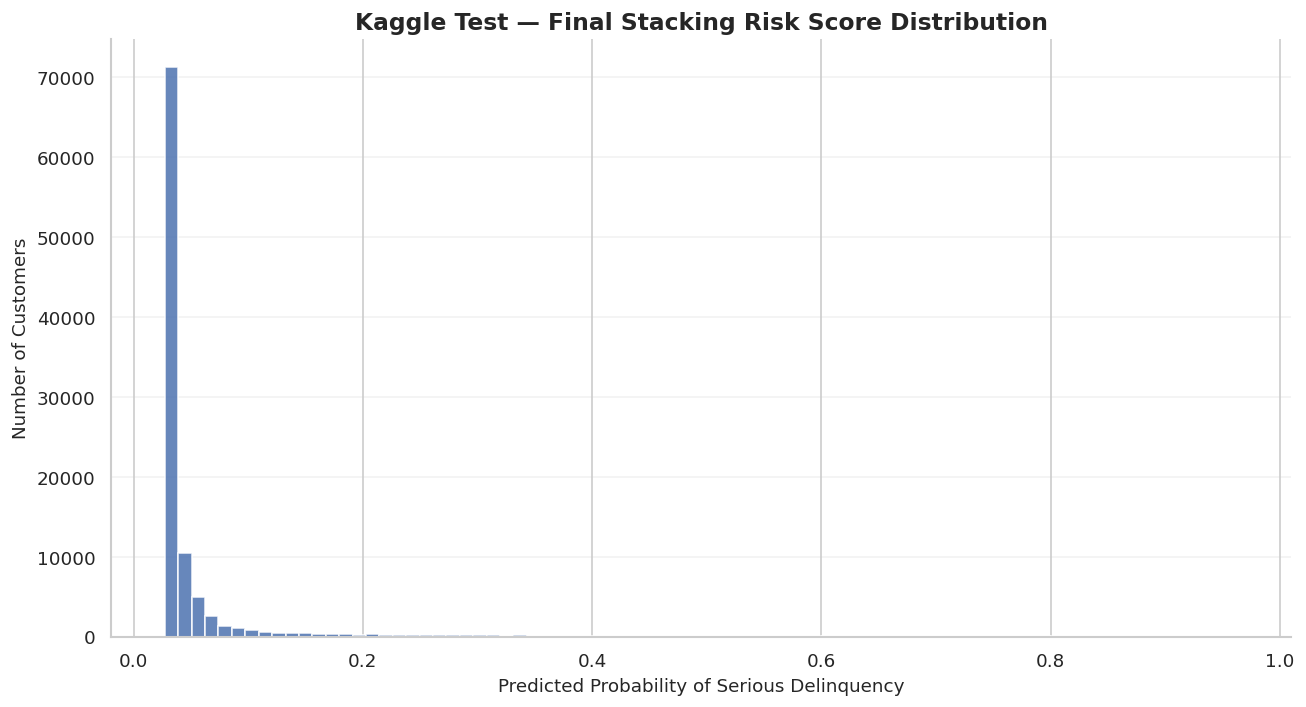


FINAL KAGGLE SUBMISSION SUMMARY


,Model,Training_Samples,Test_Samples,Features,Min_Probability,Mean_Probability,Max_Probability,Missing_Values,Duplicate_IDs,File_Size_MB
0,Stacking_Tuned_Full150K,150000,101503,10,0.027201,0.066921,0.962893,0,0,2.584385



Validation checklist:
[PASS] 101,503 test predictions
[PASS] Exactly 2 submission columns
[PASS] Original Kaggle ID order preserved
[PASS] No duplicate IDs
[PASS] No missing predictions
[PASS] All probabilities between 0 and 1
[PASS] Saved CSV reloaded successfully
[PASS] No threshold applied
[PASS] No probability calibration applied

KAGGLE SUBMISSION FILE READY
File: /content/drive/MyDrive/Datasets/Give Me Some Credit/modeling_data/final_artifacts/submission.csv
Model: Stacking_Tuned_Full150K
Evaluation metric: ROC-AUC


In [43]:
import json
import shutil
import cloudpickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DATA_DIR = Path(
    "/content/drive/MyDrive/Datasets/Give Me Some Credit"
)

MODEL_DIR = DATA_DIR / "modeling_data"

ARTIFACT_DIR = MODEL_DIR / "final_artifacts"

MODEL_PATH = (
    ARTIFACT_DIR / "credit_risk_kaggle_full_150k.pkl"
)

TEST_PATH = (
    MODEL_DIR / "kaggle_test_raw.parquet"
)

SAMPLE_PATH = DATA_DIR / "sampleEntry.csv"

SUBMISSION_PATH = ARTIFACT_DIR / "submission.csv"

LOCAL_SUBMISSION_PATH = Path(
    "/content/submission.csv"
)

print("=" * 65)
print("FINAL KAGGLE SUBMISSION")
print("=" * 65)

assert MODEL_PATH.is_file(), (
    f"Model file not found: {MODEL_PATH}"
)

assert TEST_PATH.is_file(), (
    f"Test file not found: {TEST_PATH}"
)


# ------------------------------------------------------------
# 2. Load final trained model
# ------------------------------------------------------------

print("\nLoading final Kaggle model...")

with open(MODEL_PATH, "rb") as file:
    loaded_bundle = cloudpickle.load(file)

model = loaded_bundle["model"]
metadata = loaded_bundle["metadata"]

expected_features = list(
    metadata["raw_features"]
)

assert len(expected_features) == 10

assert np.array_equal(
    np.asarray(model.classes_),
    np.array([0, 1])
)

print("Model:", metadata["model_name"])
print("Training samples:", metadata["training_samples"])
print("Expected features:", len(expected_features))
print("Model loaded successfully.")


# ------------------------------------------------------------
# 3. Load untouched Kaggle test data
# ------------------------------------------------------------

print("\nLoading Kaggle test dataset...")

test_raw = pd.read_parquet(TEST_PATH)

print("Test dataset shape:", test_raw.shape)
print("Available columns:", list(test_raw.columns))

# The original Kaggle row identifier may be stored
# as Id or Unnamed: 0 depending on export.

if "Id" in test_raw.columns:
    id_column = "Id"

elif "Unnamed: 0" in test_raw.columns:
    id_column = "Unnamed: 0"

else:
    raise ValueError(
        "Original Kaggle test ID column was not found. "
        "Do not generate synthetic IDs."
    )

missing_features = [
    col for col in expected_features
    if col not in test_raw.columns
]

if missing_features:
    raise ValueError(
        f"Missing required model features: {missing_features}"
    )

X_test_final = test_raw.loc[
    :,
    expected_features
].copy()

# Original Kaggle IDs, in original row order.
raw_ids = pd.to_numeric(
    test_raw[id_column],
    errors="raise"
)

assert raw_ids.notna().all()
assert np.isfinite(
    raw_ids.to_numpy(dtype=float)
).all()

assert np.all(
    raw_ids.to_numpy() ==
    np.floor(raw_ids.to_numpy())
)

test_ids = raw_ids.astype(
    np.int64
).to_numpy()

assert len(X_test_final) == 101503
assert X_test_final.shape[1] == 10
assert len(test_ids) == len(X_test_final)

assert pd.Index(test_ids).is_unique

assert (
    "SeriousDlqin2yrs"
    not in X_test_final.columns
)

print("\nTest matrix:", X_test_final.shape)
print("Unique IDs:", len(np.unique(test_ids)))
print("Feature order verified: PASSED")


# ------------------------------------------------------------
# 4. Verify against sampleEntry.csv (if available)
# ------------------------------------------------------------

if SAMPLE_PATH.is_file():

    sample_entry = pd.read_csv(SAMPLE_PATH)

    assert list(sample_entry.columns) == [
        "Id", "Probability"
    ], (
        "Unexpected sampleEntry.csv column format."
    )

    assert len(sample_entry) == len(test_ids)

    sample_ids = pd.to_numeric(
        sample_entry["Id"],
        errors="raise"
    ).astype(np.int64).to_numpy()

    assert np.array_equal(
        test_ids,
        sample_ids
    ), (
        "Test IDs do not match sampleEntry.csv order."
    )

    print(
        "sampleEntry.csv format and ID order: PASSED"
    )

else:
    print(
        "sampleEntry.csv not found; "
        "original test IDs will be preserved."
    )


# ------------------------------------------------------------
# 5. Generate positive-class probabilities
# ------------------------------------------------------------

print("\nGenerating final predictions...")

test_probabilities = (
    model.predict_proba(
        X_test_final
    )[:, 1]
)

test_probabilities = np.asarray(
    test_probabilities,
    dtype=np.float64
)

assert len(test_probabilities) == len(test_ids)

assert np.isfinite(
    test_probabilities
).all()

assert np.all(
    (test_probabilities >= 0.0)
    &
    (test_probabilities <= 1.0)
)

print("Predictions generated successfully.")

print(
    "Minimum probability:",
    round(float(test_probabilities.min()), 6)
)

print(
    "Maximum probability:",
    round(float(test_probabilities.max()), 6)
)

print(
    "Mean probability:",
    round(float(test_probabilities.mean()), 6)
)


# ------------------------------------------------------------
# 6. Construct Kaggle submission
# ------------------------------------------------------------

submission = pd.DataFrame({
    "Id": test_ids,
    "Probability": test_probabilities
})

assert submission.shape == (101503, 2)

assert list(submission.columns) == [
    "Id",
    "Probability"
]

assert submission["Id"].is_unique

assert submission.isna().sum().sum() == 0

assert submission["Probability"].between(
    0, 1
).all()

print("\n" + "=" * 65)
print("SUBMISSION PREVIEW — FIRST 10 ROWS")
print("=" * 65)

display(
    submission.head(10).round(8)
)


# ------------------------------------------------------------
# 7. Save submission to Google Drive
# ------------------------------------------------------------

SUBMISSION_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

submission.to_csv(
    SUBMISSION_PATH,
    index=False,
    float_format="%.17g"
)

# Additional local copy for Colab download.
shutil.copy2(
    SUBMISSION_PATH,
    LOCAL_SUBMISSION_PATH
)

print("\nSubmission saved to Google Drive:")
print(SUBMISSION_PATH)

print("\nLocal copy:")
print(LOCAL_SUBMISSION_PATH)


# ------------------------------------------------------------
# 8. Reload and verify saved CSV
# ------------------------------------------------------------

reloaded_submission = pd.read_csv(
    SUBMISSION_PATH
)

assert reloaded_submission.shape == (
    101503, 2
)

assert list(reloaded_submission.columns) == [
    "Id",
    "Probability"
]

assert np.array_equal(
    reloaded_submission["Id"].to_numpy(),
    submission["Id"].to_numpy()
)

assert np.allclose(
    reloaded_submission["Probability"].to_numpy(),
    submission["Probability"].to_numpy(),
    rtol=0,
    atol=1e-12
)

assert not reloaded_submission.isna().any().any()

assert reloaded_submission[
    "Probability"
].between(0, 1).all()

print("\nSaved CSV verification: PASSED")


# ------------------------------------------------------------
# 9. Prediction distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    submission["Probability"],
    bins=80,
    edgecolor="white",
    alpha=0.85
)

ax.set_xlabel(
    "Predicted Probability of Serious Delinquency"
)

ax.set_ylabel("Number of Customers")

ax.set_title(
    "Kaggle Test — Final Stacking Risk Score Distribution",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Final submission summary
# ------------------------------------------------------------

submission_summary = pd.DataFrame([{
    "Model": metadata["model_name"],
    "Training_Samples": metadata["training_samples"],
    "Test_Samples": len(submission),
    "Features": len(expected_features),
    "Min_Probability": test_probabilities.min(),
    "Mean_Probability": test_probabilities.mean(),
    "Max_Probability": test_probabilities.max(),
    "Missing_Values": int(
        submission.isna().sum().sum()
    ),
    "Duplicate_IDs": int(
        submission["Id"].duplicated().sum()
    ),
    "File_Size_MB": (
        SUBMISSION_PATH.stat().st_size / 1024**2
    )
}])

print("\n" + "=" * 65)
print("FINAL KAGGLE SUBMISSION SUMMARY")
print("=" * 65)

display(submission_summary.round(6))

print("\nValidation checklist:")
print("[PASS] 101,503 test predictions")
print("[PASS] Exactly 2 submission columns")
print("[PASS] Original Kaggle ID order preserved")
print("[PASS] No duplicate IDs")
print("[PASS] No missing predictions")
print("[PASS] All probabilities between 0 and 1")
print("[PASS] Saved CSV reloaded successfully")
print("[PASS] No threshold applied")
print("[PASS] No probability calibration applied")

print("\n" + "=" * 65)
print("KAGGLE SUBMISSION FILE READY")
print("=" * 65)

print("File:", SUBMISSION_PATH)
print("Model:", metadata["model_name"])
print("Evaluation metric: ROC-AUC")